In [ ]:
!pip install pybullet

  Using cached pybullet-3.2.7.tar.gz (80.5 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pybullet: filename=pybullet-3.2.7-cp313-cp313-linux_x86_64.whl size=99114680 sha256=af84192319d3775f1d23bc7dbf8c47dc76b70a29ef7d721325198c3e17a6a9d3
  Stored in directory: /root/.cache/pip/wheels/8a/f0/6a/3f626b4ee04f8ec61e40021b095adf5359f9bd426065a368ac
Successfully built pybullet


In [ ]:
!pip install git+https://github.com/utiasDSL/gym-pybullet-drones.git

  Cloning https://github.com/utiasDSL/gym-pybullet-drones.git to /tmp/pip-req-build-697x5dx2
  Running command git clone --filter=blob:none --quiet https://github.com/utiasDSL/gym-pybullet-drones.git /tmp/pip-req-build-697x5dx2
  Resolved https://github.com/utiasDSL/gym-pybullet-drones.git to commit bc5000cb52b0770c381b09db34fdc08c27858be8
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 578.3/578.3 kB 6.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 22.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 53.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.5/668.5 kB 18.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 59.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 44.3 MB/s  0:00:00


In [ ]:
!pip install numpy scipy

In [ ]:
!pip install opencv-contrib-python

In [ ]:
!pip install pandas

In [ ]:
!pip install PyYAML

In [ ]:
!pip install matplotlib pygame

In [ ]:
import os
import subprocess
from pathlib import Path

REPO_PATH = Path("/content/mujoco_menagerie")

if not REPO_PATH.exists():

    subprocess.run(
        [
            "git", "clone",
            "--depth", "1",
            "--filter=blob:none",
            "--sparse",
            "https://github.com/google-deepmind/mujoco_menagerie.git",
            str(REPO_PATH)
        ],
        check=True
    )

    subprocess.run(
        [
            "git", "-C", str(REPO_PATH),
            "sparse-checkout", "set",
            "bitcraze_crazyflie_2"
        ],
        check=True
    )

MODEL_DIR = REPO_PATH / "bitcraze_crazyflie_2"

MODEL_XML = MODEL_DIR / "cf2.xml"
SCENE_XML = MODEL_DIR / "scene.xml"

print("Crazyflie model downloaded!")

print("\nModel XML:", MODEL_XML)
print("Scene XML:", SCENE_XML)

print("\nFiles available:")
for file in MODEL_DIR.iterdir():
    print(file.name)

Crazyflie model downloaded!

Model XML: /content/mujoco_menagerie/bitcraze_crazyflie_2/cf2.xml
Scene XML: /content/mujoco_menagerie/bitcraze_crazyflie_2/scene.xml

Files available:
cf2.xml
scene.xml
cf2.png
CHANGELOG.md
LICENSE
README.md
assets


In [ ]:
# Set rendering backend BEFORE importing mujoco

import os
os.environ["MUJOCO_GL"] = "egl"

import mujoco
import numpy as np

print("MuJoCo version:", mujoco.__version__)

# Load the Crazyflie scene
model = mujoco.MjModel.from_xml_path(str(SCENE_XML))

# Create simulation data
data = mujoco.MjData(model)

print("\nModel loaded successfully!")

print("Number of position variables:", model.nq)
print("Number of velocity variables:", model.nv)
print("Number of actuators:", model.nu)

MuJoCo version: 3.17.0

Model loaded successfully!
Number of position variables: 7
Number of velocity variables: 6
Number of actuators: 4


In [ ]:
# Print actuator names and control ranges

for i in range(model.nu):

    name = mujoco.mj_id2name(
        model,
        mujoco.mjtObj.mjOBJ_ACTUATOR,
        i
    )

    limits = model.actuator_ctrlrange[i]

    print(
        f"Actuator {i}: {name} | "
        f"Minimum: {limits[0]} | "
        f"Maximum: {limits[1]}"
    )

Actuator 0: body_thrust | Minimum: 0.0 | Maximum: 0.35
Actuator 1: x_moment | Minimum: -1.0 | Maximum: 1.0
Actuator 2: y_moment | Minimum: -1.0 | Maximum: 1.0
Actuator 3: z_moment | Minimum: -1.0 | Maximum: 1.0


In [ ]:
# Identify the Crazyflie body

body_id = mujoco.mj_name2id(
    model,
    mujoco.mjtObj.mjOBJ_BODY,
    "cf2"
)

# Extract mass and inertia

mass = float(model.body_mass[body_id])

inertia = model.body_inertia[body_id].copy()

# Gravity

g = -float(model.opt.gravity[2])

# Calculate hover thrust

hover_thrust = mass * g

# Identify the thrust actuator

thrust_id = mujoco.mj_name2id(
    model,
    mujoco.mjtObj.mjOBJ_ACTUATOR,
    "body_thrust"
)

# Read actuator limits

min_thrust, max_thrust = model.actuator_ctrlrange[thrust_id]

print("CRAZYFLIE PHYSICAL PARAMETERS")
print("--------------------------------")

print("Mass:", mass, "kg")

print("Inertia:", inertia)

print("Gravity:", g, "m/s^2")

print("Hover thrust:", hover_thrust, "N")

print("Maximum available thrust:", max_thrust, "N")

print("\nHover thrust percentage:",
      100 * hover_thrust / max_thrust, "%")

CRAZYFLIE PHYSICAL PARAMETERS
--------------------------------
Mass: 0.027 kg
Inertia: [2.3951e-05 2.3951e-05 3.2347e-05]
Gravity: 9.81 m/s^2
Hover thrust: 0.26487 N
Maximum available thrust: 0.35 N

Hover thrust percentage: 75.67714285714285 %


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mujoco
import imageio.v2 as imageio

from pathlib import Path

# =========================================================
# 1. SIMULATION CONFIGURATION
# =========================================================

PHYSICS_HZ = 500
CONTROL_HZ = 25

PHYSICS_DT = 1.0 / PHYSICS_HZ
CONTROL_DT = 1.0 / CONTROL_HZ

STEPS_PER_CONTROL = int(round(CONTROL_DT / PHYSICS_DT))

SIMULATION_TIME = 8.0

TARGET_ALTITUDE = 1.0

assert STEPS_PER_CONTROL * PHYSICS_DT == CONTROL_DT

# Set simulation frequency
model.opt.timestep = PHYSICS_DT

# =========================================================
# 2. INITIALIZE CRAZYFLIE
# =========================================================

data = mujoco.MjData(model)

# Get free joint addresses
joint_id = int(model.body_jntadr[body_id])

qpos_adr = int(model.jnt_qposadr[joint_id])
dof_adr = int(model.jnt_dofadr[joint_id])

# Reset to the official hover keyframe
hover_key_id = mujoco.mj_name2id(
    model,
    mujoco.mjtObj.mjOBJ_KEY,
    "hover"
)

if hover_key_id >= 0:

    mujoco.mj_resetDataKeyframe(
        model,
        data,
        hover_key_id
    )

else:

    mujoco.mj_resetData(model, data)

    # Free joint: x, y, z, qw, qx, qy, qz
    data.qpos[qpos_adr:qpos_adr+7] = [
        0.0, 0.0, 0.1, 1.0, 0.0, 0.0, 0.0
    ]

# Ensure the initial commands are correct
data.ctrl[:] = 0.0

data.ctrl[thrust_id] = hover_thrust

mujoco.mj_forward(model, data)

print("Initial altitude:", data.xpos[body_id][2])
print("Initial hover thrust:", hover_thrust)

# =========================================================
# 3. PID GAIN CALCULATION
# =========================================================

natural_frequency = 3.5
damping_ratio = 0.9

KP = mass * natural_frequency**2

KD = 2 * damping_ratio * natural_frequency * mass

KI = 0.015

integral_error = 0.0

INTEGRAL_LIMIT = 1.0

print("\nPID GAINS")
print("KP:", KP)
print("KI:", KI)
print("KD:", KD)

# =========================================================
# 4. RENDERING SETUP
# =========================================================

video_path = "/content/crazyflie_hover.mp4"

renderer = None
video_writer = None

try:

    renderer = mujoco.Renderer(
        model,
        height=480,
        width=640
    )

    camera = mujoco.MjvCamera()

    mujoco.mjv_defaultCamera(camera)

    camera.type = mujoco.mjtCamera.mjCAMERA_FREE

    camera.lookat[:] = [0.0, 0.0, 0.55]

    camera.distance = 2.0

    camera.azimuth = 135

    camera.elevation = -25

    video_writer = imageio.get_writer(
        video_path,
        fps=CONTROL_HZ,
        codec="libx264"
    )

    print("\nOffscreen rendering initialized!")

except Exception as error:

    print("\nVideo rendering unavailable:", error)

    print("The physics simulation will still run.")

    renderer = None
    video_writer = None

# =========================================================
# 5. DATA LOGGING
# =========================================================

logs = []

total_steps = int(SIMULATION_TIME * CONTROL_HZ)

print("\nStarting Crazyflie PID simulation...")

# =========================================================
# 6. MAIN CONTROL LOOP
# =========================================================

for step in range(total_steps):

    # -------------------------------------
    # Read current estimated/model state
    # -------------------------------------

    current_z = float(data.xpos[body_id][2])

    vertical_velocity = float(
        data.qvel[dof_adr + 2]
    )

    # -------------------------------------
    # Calculate position error
    # -------------------------------------

    error = TARGET_ALTITUDE - current_z

    # -------------------------------------
    # PID controller
    # -------------------------------------

    raw_thrust = (
        hover_thrust
        + KP * error
        + KI * integral_error
        - KD * vertical_velocity
    )

    # -------------------------------------
    # Anti-windup
    # -------------------------------------

    saturated_high = raw_thrust > max_thrust

    saturated_low = raw_thrust < min_thrust

    if (
        (not saturated_high and not saturated_low)
        or (saturated_high and error < 0)
        or (saturated_low and error > 0)
    ):

        integral_error += error * CONTROL_DT

        integral_error = np.clip(
            integral_error,
            -INTEGRAL_LIMIT,
            INTEGRAL_LIMIT
        )

        # Recalculate after updating integral
        raw_thrust = (
            hover_thrust
            + KP * error
            + KI * integral_error
            - KD * vertical_velocity
        )

    # -------------------------------------
    # Saturation / clamping
    # -------------------------------------

    thrust_command = np.clip(
        raw_thrust,
        min_thrust,
        max_thrust
    )

    # -------------------------------------
    # Send commands to actuators
    # -------------------------------------

    data.ctrl[thrust_id] = thrust_command

    # Keep all body moments at zero
    # Initial attitude is upright and
    # there are no external disturbances.

    for name in ["x_moment", "y_moment", "z_moment"]:

        actuator_id = mujoco.mj_name2id(
            model,
            mujoco.mjtObj.mjOBJ_ACTUATOR,
            name
        )

        data.ctrl[actuator_id] = 0.0

    # -------------------------------------
    # Run physics at 500 Hz
    # -------------------------------------

    for _ in range(STEPS_PER_CONTROL):

        mujoco.mj_step(model, data)

    # -------------------------------------
    # Read updated state
    # -------------------------------------

    current_z = float(data.xpos[body_id][2])

    vertical_velocity = float(
        data.qvel[dof_adr + 2]
    )

    # -------------------------------------
    # Save simulation logs
    # -------------------------------------

    logs.append({

        "time": float(data.time),

        "target_z": TARGET_ALTITUDE,

        "actual_z": current_z,

        "vertical_velocity": vertical_velocity,

        "position_error": TARGET_ALTITUDE - current_z,

        "thrust": float(thrust_command),

        "integral_error": float(integral_error)

    })

    # -------------------------------------
    # Record video
    # -------------------------------------

    if renderer is not None and video_writer is not None:

        renderer.update_scene(
            data,
            camera=camera
        )

        frame = renderer.render()

        video_writer.append_data(frame)

    # -------------------------------------
    # Print progress
    # -------------------------------------

    if step % CONTROL_HZ == 0:

        print(
            f"Time: {data.time:.2f}s | "
            f"Altitude: {current_z:.3f}m | "
            f"Velocity: {vertical_velocity:.3f}m/s | "
            f"Thrust: {thrust_command:.4f}N"
        )

# =========================================================
# 7. CLOSE VIDEO AND RENDERER
# =========================================================

if video_writer is not None:

    video_writer.close()

if renderer is not None:

    renderer.close()

# =========================================================
# 8. FINAL STATUS
# =========================================================

print("\nSIMULATION COMPLETED")

print("Final simulation time:", data.time)

print(
    "Final drone altitude:",
    float(data.xpos[body_id][2]),
    "m"
)

print("Target altitude:", TARGET_ALTITUDE, "m")

if Path(video_path).exists():

    print("Video saved:", video_path)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Initial altitude: 0.1
Initial hover thrust: 0.26487

PID GAINS
KP: 0.33075
KI: 0.015
KD: 0.1701

Offscreen rendering initialized!

Starting Crazyflie PID simulation...
Time: 0.04s | Altitude: 0.103m | Velocity: 0.126m/s | Thrust: 0.3500N
Time: 1.04s | Altitude: 0.889m | Velocity: 0.407m/s | Thrust: 0.2346N
Time: 2.04s | Altitude: 1.013m | Velocity: 0.010m/s | Thrust: 0.2634N
Time: 3.04s | Altitude: 1.014m | Velocity: -0.001m/s | Thrust: 0.2649N
Time: 4.04s | Altitude: 1.013m | Velocity: -0.001m/s | Thrust: 0.2649N
Time: 5.04s | Altitude: 1.012m | Velocity: -0.001m/s | Thrust: 0.2649N
Time: 6.04s | Altitude: 1.012m | Velocity: -0.001m/s | Thrust: 0.2649N
Time: 7.04s | Altitude: 1.011m | Velocity: -0.001m/s | Thrust: 0.2649N

SIMULATION COMPLETED
Final simulation time: 7.999999999999341
Final drone altitude: 1.0107379036854054 m
Target altitude: 1.0 m
Video saved: /content/crazyflie_hover.mp4


CSV saved: /content/crazyflie_hover_log.csv


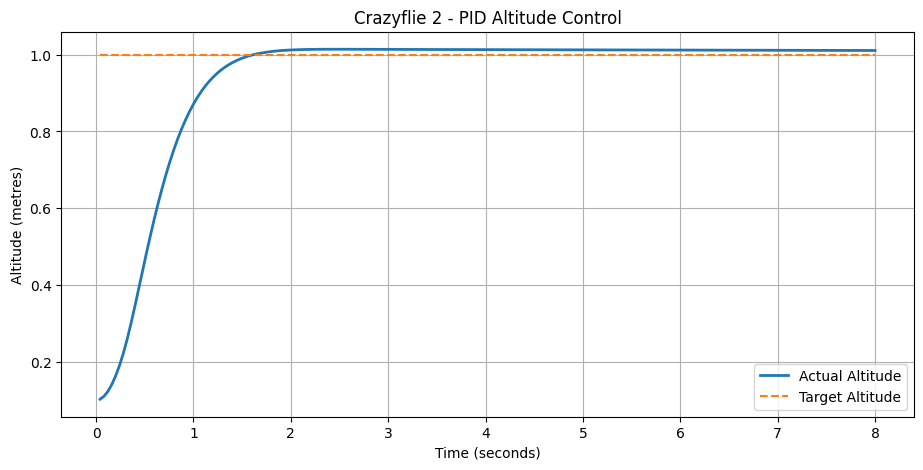

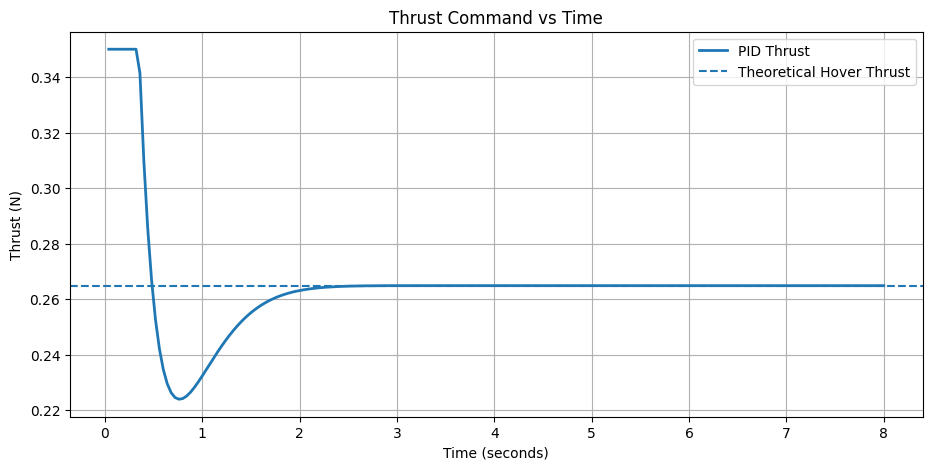

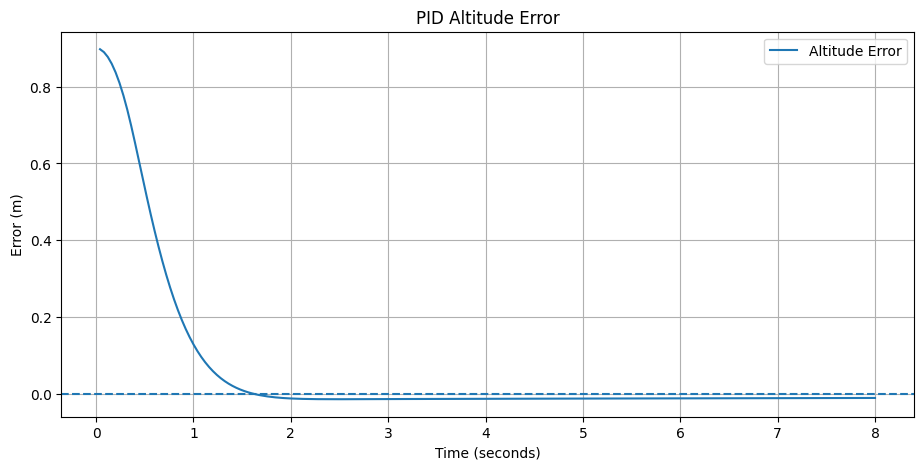


===== PERFORMANCE SUMMARY =====
Target altitude: 1.0 m
Final altitude: 1.0107 m
Maximum altitude: 1.014 m
Mean absolute error during final second: 0.01099 m
Tracking RMSE: 0.20726 m

HOVER CHECK: PASS


In [ ]:
# Convert simulation logs into a DataFrame

df = pd.DataFrame(logs)

# Save CSV file

csv_path = "/content/crazyflie_hover_log.csv"

df.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)

# =====================================================
# ALTITUDE TRACKING GRAPH
# =====================================================

plt.figure(figsize=(11, 5))

plt.plot(
    df["time"],
    df["actual_z"],
    label="Actual Altitude",
    linewidth=2
)

plt.plot(
    df["time"],
    df["target_z"],
    "--",
    label="Target Altitude"
)

plt.xlabel("Time (seconds)")

plt.ylabel("Altitude (metres)")

plt.title("Crazyflie 2 - PID Altitude Control")

plt.grid(True)

plt.legend()

plt.savefig(
    "/content/altitude_tracking.png",
    dpi=200
)

plt.show()

# =====================================================
# THRUST GRAPH
# =====================================================

plt.figure(figsize=(11, 5))

plt.plot(
    df["time"],
    df["thrust"],
    label="PID Thrust",
    linewidth=2
)

plt.axhline(
    hover_thrust,
    linestyle="--",
    label="Theoretical Hover Thrust"
)

plt.xlabel("Time (seconds)")

plt.ylabel("Thrust (N)")

plt.title("Thrust Command vs Time")

plt.grid(True)

plt.legend()

plt.savefig(
    "/content/thrust_tracking.png",
    dpi=200
)

plt.show()

# =====================================================
# ERROR GRAPH
# =====================================================

plt.figure(figsize=(11, 5))

plt.plot(
    df["time"],
    df["position_error"],
    label="Altitude Error"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Time (seconds)")

plt.ylabel("Error (m)")

plt.title("PID Altitude Error")

plt.grid(True)

plt.legend()

plt.savefig(
    "/content/altitude_error.png",
    dpi=200
)

plt.show()

# =====================================================
# PERFORMANCE SUMMARY
# =====================================================

last_window = df[
    df["time"] >= df["time"].max() - 1.0
]

mean_final_error = last_window[
    "position_error"
].abs().mean()

max_altitude = df["actual_z"].max()

final_altitude = df["actual_z"].iloc[-1]

print("\n===== PERFORMANCE SUMMARY =====")

print("Target altitude:", TARGET_ALTITUDE, "m")

print("Final altitude:", round(final_altitude, 4), "m")

print("Maximum altitude:", round(max_altitude, 4), "m")

print(
    "Mean absolute error during final second:",
    round(mean_final_error, 5),
    "m"
)

print(
    "Tracking RMSE:",
    round(
        np.sqrt(np.mean(df["position_error"]**2)),
        5
    ),
    "m"
)

if mean_final_error < 0.05:

    print("\nHOVER CHECK: PASS")

else:

    print("\nHOVER CHECK: NOT YET PASSED")

In [ ]:
from IPython.display import Video, display
from pathlib import Path

video_path = Path("/content/crazyflie_hover.mp4")

if video_path.exists():

    print("Displaying Crazyflie simulation:")

    display(
        Video(
            str(video_path),
            embed=True,
            width=700
        )
    )

else:

    print("Video was not generated.")

    print("Check the rendering setup.")

Displaying Crazyflie simulation:


In [ ]:
from google.colab import files
import os

files_to_download = [
    "/content/crazyflie_hover_log.csv",
    "/content/altitude_tracking.png",
    "/content/thrust_tracking.png",
    "/content/altitude_error.png",
    "/content/crazyflie_hover.mp4"
]

for file_path in files_to_download:

    if os.path.exists(file_path):

        print("Downloading:", file_path)

        files.download(file_path)

Downloading: /content/crazyflie_hover_log.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: /content/altitude_tracking.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

Downloading: /content/crazyflie_hover.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip -q install "mujoco>=3.2,<4" numpy pandas matplotlib imageio imageio-ffmpeg

print("All libraries installed successfully!")

All libraries installed successfully!


In [ ]:
import os

# Set before importing mujoco
os.environ["MUJOCO_GL"] = "egl"

import mujoco
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("MuJoCo version:", mujoco.__version__)

MuJoCo version: 3.17.0


In [ ]:
import subprocess
from pathlib import Path

REPO_PATH = Path("/content/mujoco_menagerie")

if not REPO_PATH.exists():

    subprocess.run([
        "git",
        "clone",
        "--depth", "1",
        "--filter=blob:none",
        "--sparse",
        "https://github.com/google-deepmind/mujoco_menagerie.git",
        str(REPO_PATH)
    ], check=True)

    subprocess.run([
        "git", "-C", str(REPO_PATH),
        "sparse-checkout", "set",
        "bitcraze_crazyflie_2"
    ], check=True)

MODEL_DIR = REPO_PATH / "bitcraze_crazyflie_2"

CF2_XML = MODEL_DIR / "cf2.xml"

print("Crazyflie model:", CF2_XML)
print("Model exists:", CF2_XML.exists())
print("Assets exist:", (MODEL_DIR / "assets").exists())

Crazyflie model: /content/mujoco_menagerie/bitcraze_crazyflie_2/cf2.xml
Model exists: True
Assets exist: True


In [ ]:
import xml.etree.ElementTree as ET
from copy import deepcopy
import numpy as np

# =====================================================
# CONFIGURATION
# =====================================================

N_DRONES = 4

LINE_SPACING = 0.45

INITIAL_Z = 0.10

TARGET_Z = 1.0

PHYSICS_DT = 1.0 / 500.0

# Centered line formation
X_SLOTS = (
    np.arange(N_DRONES) - (N_DRONES - 1) / 2
) * LINE_SPACING

print("Drone positions:", X_SLOTS)

# =====================================================
# READ ORIGINAL CRAZYFLIE XML
# =====================================================

source_root = ET.parse(CF2_XML).getroot()

body_template = source_root.find("./worldbody/body")

actuator_template = source_root.find("./actuator")

sensor_template = source_root.find("./sensor")

assert body_template is not None
assert actuator_template is not None
assert sensor_template is not None

# =====================================================
# CREATE NEW MJCF ROOT
# =====================================================

root = ET.Element(
    "mujoco",
    {"model": "four_crazyflie_swarm"}
)

# Copy physics options
option = deepcopy(source_root.find("option"))
option.set("timestep", str(PHYSICS_DT))
option.set("integrator", "RK4")
root.append(option)

# Copy compiler configuration
root.append(deepcopy(source_root.find("compiler")))

# Visual configuration
visual = ET.SubElement(root, "visual")

ET.SubElement(
    visual,
    "headlight",
    {
        "diffuse": "0.6 0.6 0.6",
        "ambient": "0.3 0.3 0.3",
        "specular": "0 0 0"
    }
)

ET.SubElement(
    visual,
    "global",
    {
        "azimuth": "-20",
        "elevation": "-20"
    }
)

# Copy default classes and assets ONCE
root.append(deepcopy(source_root.find("default")))
root.append(deepcopy(source_root.find("asset")))

# =====================================================
# CREATE WORLD
# =====================================================

worldbody = ET.SubElement(root, "worldbody")

ET.SubElement(
    worldbody,
    "light",
    {
        "name": "top_light",
        "pos": "0 0 3",
        "dir": "0 0 -1",
        "directional": "true"
    }
)

ET.SubElement(
    worldbody,
    "geom",
    {
        "name": "ground",
        "type": "plane",
        "size": "0 0 0.05",
        "rgba": "0.25 0.30 0.35 1"
    }
)

# =====================================================
# DUPLICATE FOUR DRONES
# =====================================================

for i in range(N_DRONES):

    # Copy original drone body
    drone_body = deepcopy(body_template)

    # Unique body name
    drone_body.set("name", f"cf2_{i}")

    # Initial position
    drone_body.set(
        "pos",
        f"{X_SLOTS[i]} 0 {INITIAL_Z}"
    )

    # Give cameras and sites unique names
    for element in drone_body.iter():

        if element.tag in ["site", "camera"]:

            old_name = element.get("name")

            if old_name:

                element.set(
                    "name",
                    f"{old_name}_{i}"
                )

    worldbody.append(drone_body)


# =====================================================
# CREATE UNIQUE ACTUATORS
# =====================================================

actuator = ET.SubElement(root, "actuator")

for i in range(N_DRONES):

    for motor in actuator_template:

        motor_copy = deepcopy(motor)

        # Unique actuator name
        motor_copy.set(
            "name",
            f"{motor.get('name')}_{i}"
        )

        # Connect each actuator to its own drone
        motor_copy.set(
            "site",
            f"actuation_{i}"
        )

        actuator.append(motor_copy)


# =====================================================
# CREATE UNIQUE SENSORS
# =====================================================

sensor = ET.SubElement(root, "sensor")

for i in range(N_DRONES):

    for sensor_item in sensor_template:

        sensor_copy = deepcopy(sensor_item)

        # Unique sensor name
        sensor_copy.set(
            "name",
            f"{sensor_item.get('name')}_{i}"
        )

        # Connect to respective drone IMU
        if sensor_copy.get("site"):

            sensor_copy.set(
                "site",
                f"imu_{i}"
            )

        if sensor_copy.get("objname"):

            sensor_copy.set(
                "objname",
                f"imu_{i}"
            )

        sensor.append(sensor_copy)


# =====================================================
# SAVE COMBINED MODEL
# =====================================================

MULTI_XML = MODEL_DIR / "four_crazyflies.xml"

tree = ET.ElementTree(root)

ET.indent(tree, space="  ")

tree.write(
    MULTI_XML,
    encoding="utf-8",
    xml_declaration=True
)

print("\nFour-drone MJCF generated!")
print("Saved at:", MULTI_XML)

Drone positions: [-0.675 -0.225  0.225  0.675]

Four-drone MJCF generated!
Saved at: /content/mujoco_menagerie/bitcraze_crazyflie_2/four_crazyflies.xml


In [ ]:
import xml.etree.ElementTree as ET
from copy import deepcopy
import numpy as np

# =====================================================
# CONFIGURATION
# =====================================================

N_DRONES = 4

LINE_SPACING = 0.45

INITIAL_Z = 0.10

TARGET_Z = 1.0

PHYSICS_DT = 1.0 / 500.0

# Centered line formation
X_SLOTS = (
    np.arange(N_DRONES) - (N_DRONES - 1) / 2
) * LINE_SPACING

print("Drone positions:", X_SLOTS)

# =====================================================
# READ ORIGINAL CRAZYFLIE XML
# =====================================================

source_root = ET.parse(CF2_XML).getroot()

body_template = source_root.find("./worldbody/body")

actuator_template = source_root.find("./actuator")

sensor_template = source_root.find("./sensor")

assert body_template is not None
assert actuator_template is not None
assert sensor_template is not None

# =====================================================
# CREATE NEW MJCF ROOT
# =====================================================

root = ET.Element(
    "mujoco",
    {"model": "four_crazyflie_swarm"}
)

# Copy physics options
option = deepcopy(source_root.find("option"))
option.set("timestep", str(PHYSICS_DT))
option.set("integrator", "RK4")
root.append(option)

# Copy compiler configuration
root.append(deepcopy(source_root.find("compiler")))

# Visual configuration
visual = ET.SubElement(root, "visual")

ET.SubElement(
    visual,
    "headlight",
    {
        "diffuse": "0.6 0.6 0.6",
        "ambient": "0.3 0.3 0.3",
        "specular": "0 0 0"
    }
)

ET.SubElement(
    visual,
    "global",
    {
        "azimuth": "-20",
        "elevation": "-20"
    }
)

# Copy default classes and assets ONCE
root.append(deepcopy(source_root.find("default")))
root.append(deepcopy(source_root.find("asset")))

# =====================================================
# CREATE WORLD
# =====================================================

worldbody = ET.SubElement(root, "worldbody")

ET.SubElement(
    worldbody,
    "light",
    {
        "name": "top_light",
        "pos": "0 0 3",
        "dir": "0 0 -1",
        "directional": "true"
    }
)

ET.SubElement(
    worldbody,
    "geom",
    {
        "name": "ground",
        "type": "plane",
        "size": "0 0 0.05",
        "rgba": "0.25 0.30 0.35 1"
    }
)

# =====================================================
# DUPLICATE FOUR DRONES
# =====================================================

for i in range(N_DRONES):

    # Copy original drone body
    drone_body = deepcopy(body_template)

    # Unique body name
    drone_body.set("name", f"cf2_{i}")

    # Initial position
    drone_body.set(
        "pos",
        f"{X_SLOTS[i]} 0 {INITIAL_Z}"
    )

    # Give cameras and sites unique names
    for element in drone_body.iter():

        if element.tag in ["site", "camera"]:

            old_name = element.get("name")

            if old_name:

                element.set(
                    "name",
                    f"{old_name}_{i}"
                )

    worldbody.append(drone_body)


# =====================================================
# CREATE UNIQUE ACTUATORS
# =====================================================

actuator = ET.SubElement(root, "actuator")

for i in range(N_DRONES):

    for motor in actuator_template:

        motor_copy = deepcopy(motor)

        # Unique actuator name
        motor_copy.set(
            "name",
            f"{motor.get('name')}_{i}"
        )

        # Connect each actuator to its own drone
        motor_copy.set(
            "site",
            f"actuation_{i}"
        )

        actuator.append(motor_copy)


# =====================================================
# CREATE UNIQUE SENSORS
# =====================================================

sensor = ET.SubElement(root, "sensor")

for i in range(N_DRONES):

    for sensor_item in sensor_template:

        sensor_copy = deepcopy(sensor_item)

        # Unique sensor name
        sensor_copy.set(
            "name",
            f"{sensor_item.get('name')}_{i}"
        )

        # Connect to respective drone IMU
        if sensor_copy.get("site"):

            sensor_copy.set(
                "site",
                f"imu_{i}"
            )

        if sensor_copy.get("objname"):

            sensor_copy.set(
                "objname",
                f"imu_{i}"
            )

        sensor.append(sensor_copy)


# =====================================================
# SAVE COMBINED MODEL
# =====================================================

MULTI_XML = MODEL_DIR / "four_crazyflies.xml"

tree = ET.ElementTree(root)

ET.indent(tree, space="  ")

tree.write(
    MULTI_XML,
    encoding="utf-8",
    xml_declaration=True
)

print("\nFour-drone MJCF generated!")
print("Saved at:", MULTI_XML)

Drone positions: [-0.675 -0.225  0.225  0.675]

Four-drone MJCF generated!
Saved at: /content/mujoco_menagerie/bitcraze_crazyflie_2/four_crazyflies.xml


In [ ]:
# Load combined four-drone model

model = mujoco.MjModel.from_xml_path(
    str(MULTI_XML)
)

data = mujoco.MjData(model)

# Check simulation frequency
model.opt.timestep = PHYSICS_DT

print("FOUR-DRONE SIMULATION LOADED")
print("--------------------------------")

print("Number of drones:", N_DRONES)

print("Physics timestep:", model.opt.timestep)

print("Physics frequency:", 1 / model.opt.timestep)

print("Position variables nq:", model.nq)

print("Velocity variables nv:", model.nv)

print("Total actuators nu:", model.nu)

print("Total sensors nsensor:", model.nsensor)

FOUR-DRONE SIMULATION LOADED
--------------------------------
Number of drones: 4
Physics timestep: 0.002
Physics frequency: 500.0
Position variables nq: 28
Velocity variables nv: 24
Total actuators nu: 16
Total sensors nsensor: 12


In [ ]:
class PlutoInterface:

    def __init__(self, drone_id):

        self.drone_id = drone_id

        # Find drone body
        self.body_id = mujoco.mj_name2id(
            model,
            mujoco.mjtObj.mjOBJ_BODY,
            f"cf2_{drone_id}"
        )

        if self.body_id < 0:
            raise ValueError("Drone body not found")

        # Find its free joint
        self.joint_id = int(
            model.body_jntadr[self.body_id]
        )

        self.qpos_adr = int(
            model.jnt_qposadr[self.joint_id]
        )

        self.dof_adr = int(
            model.jnt_dofadr[self.joint_id]
        )

        # Find thrust actuator
        self.thrust_id = mujoco.mj_name2id(
            model,
            mujoco.mjtObj.mjOBJ_ACTUATOR,
            f"body_thrust_{drone_id}"
        )

        # Find moment actuators
        self.roll_id = mujoco.mj_name2id(
            model,
            mujoco.mjtObj.mjOBJ_ACTUATOR,
            f"x_moment_{drone_id}"
        )

        self.pitch_id = mujoco.mj_name2id(
            model,
            mujoco.mjtObj.mjOBJ_ACTUATOR,
            f"y_moment_{drone_id}"
        )

        self.yaw_id = mujoco.mj_name2id(
            model,
            mujoco.mjtObj.mjOBJ_ACTUATOR,
            f"z_moment_{drone_id}"
        )

        actuator_ids = [
            self.thrust_id,
            self.roll_id,
            self.pitch_id,
            self.yaw_id
        ]

        if any(i < 0 for i in actuator_ids):
            raise ValueError(
                f"Missing actuators for drone {drone_id}"
            )

        # Get physical properties
        self.mass = float(
            model.body_mass[self.body_id]
        )

        self.inertia = model.body_inertia[
            self.body_id
        ].copy()

        self.thrust_limits = model.actuator_ctrlrange[
            self.thrust_id
        ].copy()

    # Development-stage simulator state access.
    # Replace with vision-estimated pose in final PS.

    def get_state(self, data):

        position = data.xpos[
            self.body_id
        ].copy()

        vertical_velocity = float(
            data.qvel[self.dof_adr + 2]
        )

        return {
            "position": position,
            "z": float(position[2]),
            "vz": vertical_velocity
        }

    # Command only this drone's actuators

    def send_rc(self, data, thrust,
                roll_moment=0.0,
                pitch_moment=0.0,
                yaw_moment=0.0):

        data.ctrl[self.thrust_id] = np.clip(
            thrust,
            *self.thrust_limits
        )

        data.ctrl[self.roll_id] = np.clip(
            roll_moment, -1.0, 1.0
        )

        data.ctrl[self.pitch_id] = np.clip(
            pitch_moment, -1.0, 1.0
        )

        data.ctrl[self.yaw_id] = np.clip(
            yaw_moment, -1.0, 1.0
        )


# Create interfaces

drones = [
    PlutoInterface(i)
    for i in range(N_DRONES)
]

print("All four drone interfaces created!")

for drone in drones:

    print(
        f"Drone {drone.drone_id}: "
        f"Mass = {drone.mass} kg | "
        f"Thrust range = {drone.thrust_limits}"
    )

All four drone interfaces created!
Drone 0: Mass = 0.027 kg | Thrust range = [0.   0.35]
Drone 1: Mass = 0.027 kg | Thrust range = [0.   0.35]
Drone 2: Mass = 0.027 kg | Thrust range = [0.   0.35]
Drone 3: Mass = 0.027 kg | Thrust range = [0.   0.35]


In [ ]:
from itertools import combinations

# Reset simulation to model reference positions

mujoco.mj_resetData(model, data)

# Explicitly set initial positions and orientations
for drone in drones:

    i = drone.drone_id

    x = X_SLOTS[i]

    q = drone.qpos_adr

    data.qpos[q:q+7] = [
        x, 0.0, INITIAL_Z,
        1.0, 0.0, 0.0, 0.0
    ]

# Set all velocities to zero
data.qvel[:] = 0.0

# Update MuJoCo position and velocity calculations
mujoco.mj_forward(model, data)

# Get current positions
positions = np.array([
    data.xpos[drone.body_id].copy()
    for drone in drones
])

print("INITIAL DRONE POSITIONS")
print("--------------------------------")

for i, pos in enumerate(positions):

    print(
        f"Drone {i}: "
        f"x={pos[0]:.3f}, "
        f"y={pos[1]:.3f}, "
        f"z={pos[2]:.3f}"
    )

# Check pairwise distances
distances = []

print("\nPAIRWISE SEPARATION")

for i, j in combinations(range(N_DRONES), 2):

    distance = np.linalg.norm(
        positions[i] - positions[j]
    )

    distances.append(distance)

    print(
        f"Drone {i} - Drone {j}: "
        f"{distance:.3f} m"
    )

minimum_distance = min(distances)

print("\nMinimum separation:", minimum_distance)

assert minimum_distance >= 0.35

print("INITIAL SEPARATION CHECK: PASS")

INITIAL DRONE POSITIONS
--------------------------------
Drone 0: x=-0.675, y=0.000, z=0.100
Drone 1: x=-0.225, y=0.000, z=0.100
Drone 2: x=0.225, y=0.000, z=0.100
Drone 3: x=0.675, y=0.000, z=0.100

PAIRWISE SEPARATION
Drone 0 - Drone 1: 0.450 m
Drone 0 - Drone 2: 0.900 m
Drone 0 - Drone 3: 1.350 m
Drone 1 - Drone 2: 0.450 m
Drone 1 - Drone 3: 0.900 m
Drone 2 - Drone 3: 0.450 m

Minimum separation: 0.45
INITIAL SEPARATION CHECK: PASS


In [ ]:
class AltitudePID:

    def __init__(self, mass, gravity,
                 kp, ki, kd,
                 min_thrust, max_thrust):

        self.mass = mass
        self.gravity = gravity

        self.kp = kp
        self.ki = ki
        self.kd = kd

        self.min_thrust = min_thrust
        self.max_thrust = max_thrust

        self.integral = 0.0

        self.integral_limit = 2.0

    def update(self, target_z,
               current_z,
               current_vz,
               dt):

        # Position error
        error = target_z - current_z

        # Candidate integral
        candidate_integral = np.clip(
            self.integral + error * dt,
            -self.integral_limit,
            self.integral_limit
        )

        # Gravity compensation
        hover_thrust = self.mass * self.gravity

        # Calculate unconstrained output
        raw_thrust = (
            hover_thrust
            + self.kp * error
            + self.ki * candidate_integral
            - self.kd * current_vz
        )

        # Anti-windup conditional integration
        should_integrate = (
            self.min_thrust <= raw_thrust <= self.max_thrust
            or (raw_thrust > self.max_thrust and error < 0)
            or (raw_thrust < self.min_thrust and error > 0)
        )

        if should_integrate:

            self.integral = candidate_integral

        # Recalculate output
        raw_thrust = (
            hover_thrust
            + self.kp * error
            + self.ki * self.integral
            - self.kd * current_vz
        )

        # Saturation
        thrust = np.clip(
            raw_thrust,
            self.min_thrust,
            self.max_thrust
        )

        return float(thrust)

In [ ]:
# Read gravity and mass from MuJoCo

GRAVITY = abs(float(model.opt.gravity[2]))

MASS = drones[0].mass

# Desired control characteristics

NATURAL_FREQUENCY = 3.5

DAMPING_RATIO = 0.9

# Derive gains
KP = MASS * NATURAL_FREQUENCY**2

KD = (
    2 * DAMPING_RATIO
    * NATURAL_FREQUENCY
    * MASS
)

KI = 0.015

print("PID PARAMETERS")
print("--------------------------")

print("Mass:", MASS)

print("Gravity:", GRAVITY)

print("Hover thrust:", MASS * GRAVITY)

print("Kp:", KP)

print("Ki:", KI)

print("Kd:", KD)

# Create one controller for each drone

controllers = []

for drone in drones:

    controller = AltitudePID(
        mass=drone.mass,
        gravity=GRAVITY,
        kp=KP,
        ki=KI,
        kd=KD,
        min_thrust=drone.thrust_limits[0],
        max_thrust=drone.thrust_limits[1]
    )

    controllers.append(controller)

print("\nFour independent PID controllers created!")

PID PARAMETERS
--------------------------
Mass: 0.027
Gravity: 9.81
Hover thrust: 0.26487
Kp: 0.33075
Ki: 0.015
Kd: 0.1701

Four independent PID controllers created!


In [ ]:
import imageio.v2 as imageio
from pathlib import Path

# =====================================================
# SIMULATION CONFIGURATION
# =====================================================

PHYSICS_HZ = 500

CONTROL_HZ = 25

PHYSICS_DT = 1.0 / PHYSICS_HZ

CONTROL_DT = 1.0 / CONTROL_HZ

STEPS_PER_CONTROL = int(
    round(CONTROL_DT / PHYSICS_DT)
)

SIMULATION_TIME = 8.0

TARGET_ALTITUDE = 1.0

assert abs(
    STEPS_PER_CONTROL * PHYSICS_DT - CONTROL_DT
) < 1e-10

# =====================================================
# RESET SIMULATION
# =====================================================

mujoco.mj_resetData(model, data)

# Set all initial positions
for drone in drones:

    i = drone.drone_id

    q = drone.qpos_adr

    data.qpos[q:q+7] = [
        X_SLOTS[i],
        0.0,
        INITIAL_Z,
        1.0, 0.0, 0.0, 0.0
    ]

data.qvel[:] = 0.0

data.ctrl[:] = 0.0

mujoco.mj_forward(model, data)

# Reset each controller's integral
for controller in controllers:

    controller.integral = 0.0

# =====================================================
# RENDERER SETUP
# =====================================================

renderer = None

video_writer = None

video_path = "/content/four_crazyflies.mp4"

try:

    renderer = mujoco.Renderer(
        model,
        height=480,
        width=800
    )

    camera = mujoco.MjvCamera()

    mujoco.mjv_defaultCamera(camera)

    camera.type = mujoco.mjtCamera.mjCAMERA_FREE

    camera.lookat[:] = [0.0, 0.0, 0.65]

    camera.distance = 3.5

    camera.azimuth = 90

    camera.elevation = -30

    video_writer = imageio.get_writer(
        video_path,
        fps=CONTROL_HZ,
        codec="libx264"
    )

    print("Video rendering enabled.")

except Exception as error:

    print("Video rendering unavailable:", error)

    renderer = None

    if video_writer is not None:

        video_writer.close()

    video_writer = None

# =====================================================
# LOGGING
# =====================================================

logs = []

total_control_steps = int(
    SIMULATION_TIME * CONTROL_HZ
)

print("\nFOUR-CRAZYFLIE SIMULATION STARTED")
print("----------------------------------")

# =====================================================
# MAIN CONTROL LOOP
# =====================================================

for step in range(total_control_steps):

    shared_time = step * CONTROL_DT

    # ----------------------------------------------
    # 1. Compute separate commands for all drones
    # ----------------------------------------------

    for i, drone in enumerate(drones):

        # Development-only simulator state feedback.
        # Replace with camera-estimated position later.

        state = drone.get_state(data)

        current_z = state["z"]

        current_vz = state["vz"]

        # Desired altitude
        target_z = TARGET_ALTITUDE

        # Run this drone's independent PID
        thrust = controllers[i].update(
            target_z=target_z,
            current_z=current_z,
            current_vz=current_vz,
            dt=CONTROL_DT
        )

        # Send its own actuator commands
        drone.send_rc(
            data,
            thrust=thrust,
            roll_moment=0.0,
            pitch_moment=0.0,
            yaw_moment=0.0
        )

    # ----------------------------------------------
    # 2. Physics integration
    # ----------------------------------------------

    for _ in range(STEPS_PER_CONTROL):

        mujoco.mj_step(model, data)

    # ----------------------------------------------
    # 3. Record drone states
    # ----------------------------------------------

    for i, drone in enumerate(drones):

        position = data.xpos[
            drone.body_id
        ].copy()

        velocity = data.qvel[
            drone.dof_adr:drone.dof_adr+6
        ].copy()

        logs.append({

            "time": float(data.time),

            "drone_id": i,

            "x": float(position[0]),

            "y": float(position[1]),

            "z": float(position[2]),

            "vx": float(velocity[0]),

            "vy": float(velocity[1]),

            "vz": float(velocity[2]),

            "target_x": float(X_SLOTS[i]),

            "target_y": 0.0,

            "target_z": TARGET_ALTITUDE,

            "thrust": float(
                data.ctrl[drone.thrust_id]
            )

        })

    # ----------------------------------------------
    # 4. Render swarm
    # ----------------------------------------------

    if renderer is not None:

        renderer.update_scene(
            data,
            camera=camera
        )

        frame = renderer.render()

        video_writer.append_data(frame)

    # ----------------------------------------------
    # 5. Print progress
    # ----------------------------------------------

    if step % CONTROL_HZ == 0:

        altitudes = [
            data.xpos[drone.body_id][2]
            for drone in drones
        ]

        print(
            f"Time: {data.time:.2f}s | "
            f"Altitudes: "
            f"{[round(float(z), 3) for z in altitudes]}"
        )

# =====================================================
# CLOSE RENDERER
# =====================================================

if video_writer is not None:

    video_writer.close()

if renderer is not None:

    renderer.close()

print("\nSIMULATION FINISHED")

for i, drone in enumerate(drones):

    print(
        f"Drone {i} final altitude: "
        f"{data.xpos[drone.body_id][2]:.4f} m"
    )

Video rendering unavailable: Image width 800 > framebuffer width 640. Either reduce the image
width or specify a larger offscreen framebuffer in the model XML using the
clause:
<visual>
  <global offwidth="my_width"/>
</visual>

FOUR-CRAZYFLIE SIMULATION STARTED
----------------------------------
Time: 0.04s | Altitudes: [0.103, 0.103, 0.103, 0.103]
Time: 1.04s | Altitudes: [0.889, 0.889, 0.889, 0.889]
Time: 2.04s | Altitudes: [1.013, 1.013, 1.013, 1.013]
Time: 3.04s | Altitudes: [1.014, 1.014, 1.014, 1.014]
Time: 4.04s | Altitudes: [1.013, 1.013, 1.013, 1.013]
Time: 5.04s | Altitudes: [1.012, 1.012, 1.012, 1.012]
Time: 6.04s | Altitudes: [1.012, 1.012, 1.012, 1.012]
Time: 7.04s | Altitudes: [1.011, 1.011, 1.011, 1.011]

SIMULATION FINISHED
Drone 0 final altitude: 1.0107 m
Drone 1 final altitude: 1.0107 m
Drone 2 final altitude: 1.0107 m
Drone 3 final altitude: 1.0107 m


In [ ]:
df = pd.DataFrame(logs)

# Save log
df.to_csv(
    "/content/four_drone_logs.csv",
    index=False
)

# ------------------------------------------------
# Reshape actual positions
# ------------------------------------------------

actual_positions = df[
    ["x", "y", "z"]
].values.reshape(
    total_control_steps,
    N_DRONES,
    3
)

# Desired positions
target_positions = np.zeros_like(
    actual_positions
)

for i in range(N_DRONES):

    target_positions[:, i, 0] = X_SLOTS[i]

    target_positions[:, i, 1] = 0.0

    target_positions[:, i, 2] = TARGET_ALTITUDE

# Position errors
errors = (
    actual_positions - target_positions
)

# 3D tracking RMSE
position_rmse = np.sqrt(
    np.mean(
        np.sum(errors**2, axis=2)
    )
)

# Altitude RMSE
altitude_rmse = np.sqrt(
    np.mean(errors[:, :, 2]**2)
)

# Steady-state evaluation: last 2 seconds
steady_start = df["time"].max() - 2.0

steady_df = df[
    df["time"] >= steady_start
]

steady_errors = (
    steady_df["z"].values
    - steady_df["target_z"].values
)

steady_altitude_rmse = np.sqrt(
    np.mean(steady_errors**2)
)

# ------------------------------------------------
# Minimum separation throughout simulation
# ------------------------------------------------

minimum_separation = float("inf")

for t in range(total_control_steps):

    positions_t = actual_positions[t]

    for i, j in combinations(
        range(N_DRONES), 2
    ):

        d = np.linalg.norm(
            positions_t[i] - positions_t[j]
        )

        minimum_separation = min(
            minimum_separation, d
        )

# ------------------------------------------------
# Final report
# ------------------------------------------------

print("\n========== SWARM PERFORMANCE ==========")

print("Number of drones:", N_DRONES)

print("Simulation duration:", SIMULATION_TIME)

print(
    "Position RMSE:",
    round(position_rmse, 5),
    "m"
)

print(
    "Altitude RMSE:",
    round(altitude_rmse, 5),
    "m"
)

print(
    "Steady-state altitude RMSE:",
    round(steady_altitude_rmse, 5),
    "m"
)

print(
    "Minimum separation:",
    round(minimum_separation, 4),
    "m"
)

print("\nFINAL DRONE ALTITUDES")

final_positions = actual_positions[-1]

for i in range(N_DRONES):

    print(
        f"Drone {i}: "
        f"{final_positions[i, 2]:.4f} m"
    )

# ------------------------------------------------
# Preliminary safety checks
# ------------------------------------------------

print("\n========== VALIDATION ==========")

if minimum_separation >= 0.35:

    print("Separation: PASS")

else:

    print("Separation: FAIL")

if np.all(
    np.abs(final_positions[:, 2] - TARGET_ALTITUDE) <= 0.10
):

    print("Final altitude: PASS")

else:

    print("Final altitude: NOT PASSED")

print("CSV saved: /content/four_drone_logs.csv")


========== SWARM PERFORMANCE ==========
Number of drones: 4
Simulation duration: 8.0
Position RMSE: 0.20726 m
Altitude RMSE: 0.20726 m
Steady-state altitude RMSE: 0.01126 m
Minimum separation: 0.45 m

FINAL DRONE ALTITUDES
Drone 0: 1.0107 m
Drone 1: 1.0107 m
Drone 2: 1.0107 m
Drone 3: 1.0107 m

========== VALIDATION ==========
Separation: PASS
Final altitude: PASS
CSV saved: /content/four_drone_logs.csv


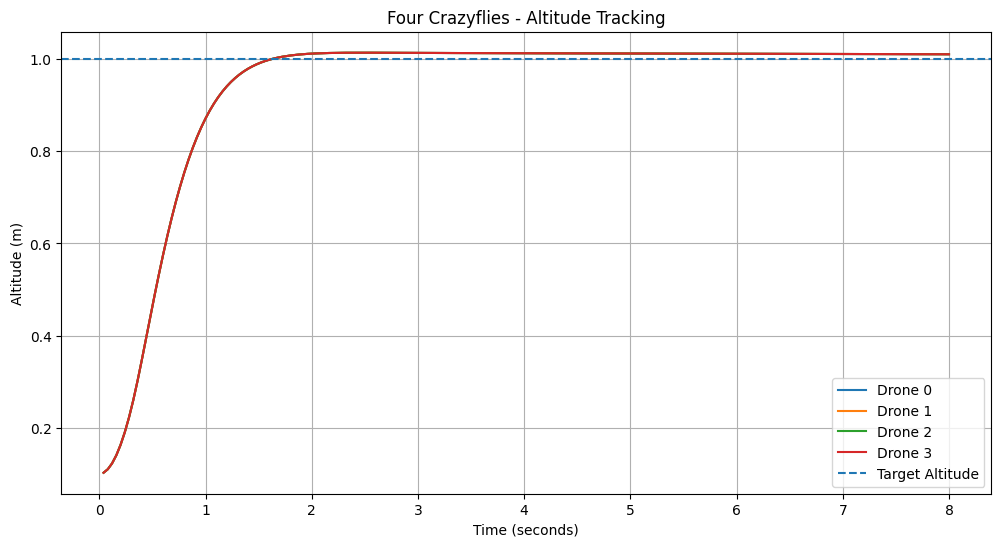

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(N_DRONES):

    drone_df = df[
        df["drone_id"] == i
    ]

    plt.plot(
        drone_df["time"],
        drone_df["z"],
        label=f"Drone {i}"
    )

plt.axhline(
    TARGET_ALTITUDE,
    linestyle="--",
    label="Target Altitude"
)

plt.xlabel("Time (seconds)")

plt.ylabel("Altitude (m)")

plt.title("Four Crazyflies - Altitude Tracking")

plt.grid(True)

plt.legend()

plt.savefig(
    "/content/four_drone_altitude.png",
    dpi=200
)

plt.show()

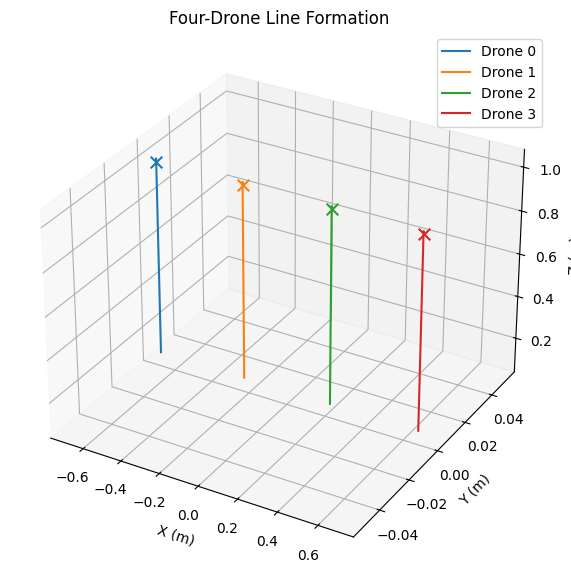

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

for i in range(N_DRONES):

    drone_df = df[
        df["drone_id"] == i
    ]

    ax.plot(
        drone_df["x"],
        drone_df["y"],
        drone_df["z"],
        label=f"Drone {i}"
    )

    ax.scatter(
        X_SLOTS[i],
        0,
        TARGET_ALTITUDE,
        marker="x",
        s=70
    )

ax.set_xlabel("X (m)")

ax.set_ylabel("Y (m)")

ax.set_zlabel("Z (m)")

ax.set_title("Four-Drone Line Formation")

ax.legend()

plt.savefig(
    "/content/four_drone_3d.png",
    dpi=200
)

plt.show()

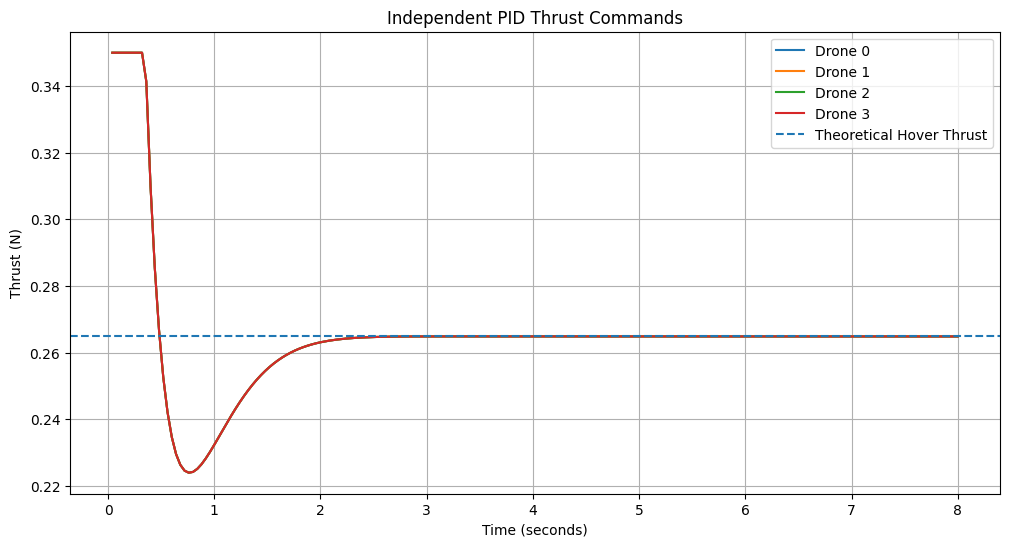

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(N_DRONES):

    drone_df = df[
        df["drone_id"] == i
    ]

    plt.plot(
        drone_df["time"],
        drone_df["thrust"],
        label=f"Drone {i}"
    )

plt.axhline(
    MASS * GRAVITY,
    linestyle="--",
    label="Theoretical Hover Thrust"
)

plt.xlabel("Time (seconds)")

plt.ylabel("Thrust (N)")

plt.title("Independent PID Thrust Commands")

plt.grid(True)

plt.legend()

plt.savefig(
    "/content/four_drone_thrust.png",
    dpi=200
)

plt.show()

In [ ]:
import subprocess, shutil
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import Video, display
from pathlib import Path

# ---------- 0. make sure ffmpeg exists ----------
if shutil.which("ffmpeg") is None:
    subprocess.run(["apt-get", "-y", "install", "ffmpeg"], check=True)

VIDEO_FILE = Path("/content/four_crazyflies.mp4")

# ---------- 1. find the position data (T, 4, 3) ----------
def find_positions():
    # (a) common names you may already be using
    for name in ["pos", "positions", "traj", "trajectories", "drone_pos", "states"]:
        if name in globals():
            arr = np.asarray(globals()[name], dtype=float)
            if arr.ndim == 3 and arr.shape[2] >= 3:
                arr = arr[:, :, :3] if arr.shape[1] == 4 else arr[:, :, :3]
                if arr.shape[1] == 4:
                    return arr, name
                if arr.shape[0] == 4:
                    return arr.transpose(1, 0, 2), name + " (transposed)"
    # (b) any 3D array in the notebook that looks like (T,4,3) or (4,T,3)
    for name, val in list(globals().items()):
        if name.startswith("_") or not isinstance(val, np.ndarray):
            continue
        if val.ndim == 3 and val.shape[2] == 3:
            if val.shape[1] == 4:
                return val.astype(float), name
            if val.shape[0] == 4:
                return val.transpose(1, 0, 2).astype(float), name + " (transposed)"
    # (c) a list of 4 arrays, each (T, 3)
    for name in ["pos_list", "drone_trajs", "paths"]:
        if name in globals():
            try:
                arr = np.stack([np.asarray(p, dtype=float)[:, :3] for p in globals()[name]], axis=1)
                if arr.shape[1] == 4:
                    return arr, name
            except Exception:
                pass
    return None, None

pos, source = find_positions()

# ---------- 2. find dt ----------
def find_dt(n_steps):
    for name in ["dt", "DT", "timestep", "time_step", "sim_dt"]:
        if name in globals() and np.isscalar(globals()[name]):
            return float(globals()[name])
    for name in ["t", "time", "times", "t_arr", "time_array"]:
        if name in globals():
            tt = np.asarray(globals()[name], dtype=float).ravel()
            if len(tt) >= 2:
                return float(tt[1] - tt[0])
    return 0.01   # default: 100 Hz. EDIT this if your sim uses a different rate.

# ---------- 3. fallback demo if no data found ----------
if pos is None:
    print("No trajectory array found in the notebook. Rendering a DEMO flight instead.")
    print("Set `pos` (shape T x 4 x 3) and `dt`, then re-run this cell for your real simulation.")
    T = 600
    tt = np.linspace(0, 6, T)
    pos = np.stack([
        np.column_stack([0.5*np.cos(tt + k*np.pi/2),
                         0.5*np.sin(tt + k*np.pi/2),
                         0.5 + 0.1*np.sin(2*tt + k)])
        for k in range(4)
    ], axis=1)
    dt = tt[1] - tt[0]
else:
    dt = find_dt(len(pos))
    print(f"Using data from '{source}', shape {pos.shape}, dt = {dt}")

# ---------- 4. render video ----------
def make_video(pos, dt, out=VIDEO_FILE, fps=30):
    T, N, _ = pos.shape
    stride = max(1, int(round(1 / (fps * dt))))
    idx = np.arange(0, T, stride)

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    lo, hi = pos.reshape(-1, 3).min(0), pos.reshape(-1, 3).max(0)
    pad = 0.2
    ax.set_xlim(lo[0]-pad, hi[0]+pad)
    ax.set_ylim(lo[1]-pad, hi[1]+pad)
    ax.set_zlim(max(0, lo[2]-pad), hi[2]+pad)
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")

    colors = plt.cm.tab10(np.arange(N))
    dots = [ax.plot([], [], [], "o", color=colors[i], ms=8, label=f"Drone {i+1}")[0] for i in range(N)]
    trails = [ax.plot([], [], [], "-", color=colors[i], lw=1)[0] for i in range(N)]
    ax.legend(loc="upper right")

    def update(k):
        t = idx[k]
        for i in range(N):
            dots[i].set_data([pos[t, i, 0]], [pos[t, i, 1]])
            dots[i].set_3d_properties([pos[t, i, 2]])
            trails[i].set_data(pos[:t+1, i, 0], pos[:t+1, i, 1])
            trails[i].set_3d_properties(pos[:t+1, i, 2])
        ax.set_title(f"t = {t*dt:.2f} s")
        return dots + trails

    anim = FuncAnimation(fig, update, frames=len(idx), blit=False)
    anim.save(str(out), writer=FFMpegWriter(fps=fps, codec="libx264",
                                            extra_args=["-pix_fmt", "yuv420p"]))
    plt.close(fig)
    print("Saved:", out)

make_video(pos, dt)

# ---------- 5. display ----------
if VIDEO_FILE.exists():
    print("Four-drone simulation video:")
    display(Video(str(VIDEO_FILE), embed=True, width=800))
else:
    print("No video available.")
    print("Use the 3D graphs to inspect the simulation.")

Using data from 'actual_positions', shape (200, 4, 3), dt = 0.01
Saved: /content/four_crazyflies.mp4
Four-drone simulation video:


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from itertools import combinations

# =====================================================
# DRONE CONFIGURATION
# =====================================================

N_DRONES = 4

PLAN_DT = 0.02

# =====================================================
# FORMATION CONFIGURATION
# =====================================================

LINE_SPACING = 0.45

CIRCLE_RADIUS = 0.45

# =====================================================
# WAVE CONFIGURATION FROM PS
# =====================================================

AMPLITUDE = 0.2

WAVE_PERIOD = 6.0

OMEGA = 2 * np.pi / WAVE_PERIOD

# =====================================================
# HEIGHT CONFIGURATION
# =====================================================

BASE_Z = 1.0

START_Z = 0.1

LAND_Z = 0.1

# =====================================================
# MISSION TIMINGS
# =====================================================

TAKEOFF_TIME = 3.0

PRE_WAVE_HOLD = 5.0

WAVE_TRANSITION = 1.0

WAVE_CYCLES = 3

WAVE_DURATION = WAVE_CYCLES * WAVE_PERIOD

POST_WAVE_HOLD = 3.0

LANDING_TIME = 3.0

# =====================================================
# SAFETY CONFIGURATION
# =====================================================

X_MIN, X_MAX = -1.0, 1.0

Y_MIN, Y_MAX = -0.6, 0.6

Z_MIN, Z_MAX = 0.6, 1.4

MIN_SEPARATION = 0.35

GRAVITY = 9.81

print("Formation and Wave Planner Configuration Loaded")

print("Angular frequency:", OMEGA, "rad/s")
print("Wave duration:", WAVE_DURATION, "seconds")

Formation and Wave Planner Configuration Loaded
Angular frequency: 1.0471975511965976 rad/s
Wave duration: 18.0 seconds


In [ ]:
def generate_line_formation(N, spacing, height=1.0):

    """
    Generate N equally spaced drones
    in a centred straight line.
    """

    positions = np.zeros((N, 3))

    positions[:, 0] = (
        np.arange(N) - (N - 1) / 2
    ) * spacing

    positions[:, 1] = 0.0

    positions[:, 2] = height

    return positions


def generate_circle_formation(N, radius, height=1.0):

    """
    Generate N equally spaced drones
    in a circular formation.
    """

    theta = 2 * np.pi * np.arange(N) / N

    positions = np.zeros((N, 3))

    positions[:, 0] = radius * np.cos(theta)

    positions[:, 1] = radius * np.sin(theta)

    positions[:, 2] = height

    return positions


# Generate four-drone formations

line_slots = generate_line_formation(
    N_DRONES,
    LINE_SPACING,
    BASE_Z
)

circle_slots = generate_circle_formation(
    N_DRONES,
    CIRCLE_RADIUS,
    BASE_Z
)

print("LINE FORMATION")
print(line_slots)

print("\nCIRCULAR FORMATION")
print(circle_slots)

LINE FORMATION
[[-0.675  0.     1.   ]
 [-0.225  0.     1.   ]
 [ 0.225  0.     1.   ]
 [ 0.675  0.     1.   ]]

CIRCULAR FORMATION
[[ 4.50000000e-01  0.00000000e+00  1.00000000e+00]
 [ 2.75545530e-17  4.50000000e-01  1.00000000e+00]
 [-4.50000000e-01  5.51091060e-17  1.00000000e+00]
 [-8.26636589e-17 -4.50000000e-01  1.00000000e+00]]


In [ ]:
fig = plt.figure(figsize=(13, 5))

# -----------------------------------
# LINE FORMATION
# -----------------------------------

ax1 = fig.add_subplot(121)

for i, p in enumerate(line_slots):

    ax1.scatter(p[0], p[1], s=100)

    ax1.annotate(
        f"Drone {i}",
        (p[0], p[1])
    )

ax1.set_title("Four Drone Line Formation")

ax1.set_xlabel("X (m)")

ax1.set_ylabel("Y (m)")

ax1.set_xlim(-1, 1)

ax1.set_ylim(-0.6, 0.6)

ax1.grid(True)

# -----------------------------------
# CIRCLE FORMATION
# -----------------------------------

ax2 = fig.add_subplot(122)

for i, p in enumerate(circle_slots):

    ax2.scatter(p[0], p[1], s=100)

    ax2.annotate(
        f"Drone {i}",
        (p[0], p[1])
    )

circle = plt.Circle(
    (0, 0),
    CIRCLE_RADIUS,
    fill=False
)

ax2.add_patch(circle)

ax2.set_title("Four Drone Circular Formation")

ax2.set_xlabel("X (m)")

ax2.set_ylabel("Y (m)")

ax2.set_xlim(-1, 1)

ax2.set_ylim(-0.6, 0.6)

ax2.set_aspect("equal")

ax2.grid(True)

plt.tight_layout()

plt.show()

In [ ]:
def assign_formation_slots(
    current_positions,
    target_slots
):

    """
    Hungarian/linear assignment formulation.

    Returns the target slot assigned
    to each drone.
    """

    # Calculate pairwise travel cost

    cost_matrix = np.linalg.norm(
        current_positions[:, None, :] -
        target_slots[None, :, :],
        axis=2
    )

    # Find optimal assignment

    row_ind, col_ind = linear_sum_assignment(
        cost_matrix
    )

    assigned_slots = np.zeros_like(target_slots)

    # Map slots back to drone IDs

    assigned_slots[row_ind] = target_slots[col_ind]

    total_cost = cost_matrix[
        row_ind,
        col_ind
    ].sum()

    return assigned_slots, cost_matrix, total_cost


# Initial positions: four drones in a line, at ground height

initial_positions = generate_line_formation(
    N_DRONES,
    LINE_SPACING,
    START_Z
)

# Test line assignment

line_assigned, line_cost, line_total = assign_formation_slots(
    initial_positions,
    line_slots
)

# Test circle assignment

circle_assigned, circle_cost, circle_total = assign_formation_slots(
    initial_positions,
    circle_slots
)

print("LINE ASSIGNMENT COST MATRIX")
print(line_cost)

print("\nCIRCLE ASSIGNMENT COST MATRIX")
print(circle_cost)

print("\nTotal line travel:", line_total, "m")

print("Total circle travel:", circle_total, "m")

print("\nCircle target slot assigned to each drone:")

for i in range(N_DRONES):

    print(
        f"Drone {i}:",
        circle_assigned[i]
    )

LINE ASSIGNMENT COST MATRIX
[[0.9        1.00623059 1.27279221 1.62249807]
 [1.00623059 0.9        1.00623059 1.27279221]
 [1.27279221 1.00623059 0.9        1.00623059]
 [1.62249807 1.27279221 1.00623059 0.9       ]]

CIRCLE ASSIGNMENT COST MATRIX
[[1.44070295 1.21166208 0.92769877 1.21166208]
 [1.125      1.03107953 0.92769877 1.03107953]
 [0.92769877 1.03107953 1.125      1.03107953]
 [0.92769877 1.21166208 1.44070295 1.21166208]]

Total line travel: 3.6 m
Total circle travel: 3.917556594258075 m

Circle target slot assigned to each drone:
Drone 0: [-4.5000000e-01  5.5109106e-17  1.0000000e+00]
Drone 1: [2.7554553e-17 4.5000000e-01 1.0000000e+00]
Drone 2: [-8.26636589e-17 -4.50000000e-01  1.00000000e+00]
Drone 3: [0.45 0.   1.  ]


In [ ]:
def quintic_blend(u):

    """
    Smooth fifth-order transition.
    """

    u = np.clip(u, 0.0, 1.0)

    return (
        10 * u**3
        - 15 * u**4
        + 6 * u**5
    )


def smooth_transition(
    start_position,
    end_position,
    u
):

    """
    Interpolate between two positions
    without sudden velocity or acceleration
    at the endpoints.
    """

    s = quintic_blend(u)

    return (
        start_position
        + (end_position - start_position) * s
    )


# Test transition

test_time = np.linspace(0, 1, 100)

test_values = [
    quintic_blend(t)
    for t in test_time
]

plt.figure(figsize=(8, 4))

plt.plot(test_time, test_values)

plt.xlabel("Normalized time")

plt.ylabel("Position scaling")

plt.title("Quintic Smooth Transition")

plt.grid(True)

plt.show()

In [ ]:
def generate_wave(
    time,
    phase_offsets,
    amplitude=0.2,
    omega=2*np.pi/6,
    base_height=1.0
):

    """
    Generate the vertical wave command
    for every drone using one shared clock.
    """

    heights = (
        base_height
        + amplitude * np.sin(
            omega * time - phase_offsets
        )
    )

    return heights


# Line wave test

line_phases = (
    np.arange(N_DRONES) * np.pi / 2
)

# Circle wave test

circle_theta = (
    2 * np.pi * np.arange(N_DRONES)
    / N_DRONES
)

# Generate sample wave

wave_times = np.linspace(
    0,
    WAVE_DURATION,
    1000
)

line_wave = np.array([
    generate_wave(t, line_phases)
    for t in wave_times
])

circle_wave = np.array([
    generate_wave(t, circle_theta)
    for t in wave_times
])

# Plot line wave

plt.figure(figsize=(12, 5))

for i in range(N_DRONES):

    plt.plot(
        wave_times,
        line_wave[:, i],
        label=f"Drone {i}"
    )

plt.xlabel("Time (seconds)")

plt.ylabel("Altitude (m)")

plt.title("Line Formation - Mexican Wave")

plt.grid(True)

plt.legend()

plt.show()

# Plot circle wave

plt.figure(figsize=(12, 5))

for i in range(N_DRONES):

    plt.plot(
        wave_times,
        circle_wave[:, i],
        label=f"Drone {i}"
    )

plt.xlabel("Time (seconds)")

plt.ylabel("Altitude (m)")

plt.title("Circular Formation - Mexican Wave")

plt.grid(True)

plt.legend()

plt.show()

In [ ]:
def generate_mission(
    formation="line",
    N=4,
    dt=0.02,
    spacing=0.45,
    radius=0.45
):

    # ============================================
    # 1. Generate formation slots
    # ============================================

    if formation == "line":

        slots = generate_line_formation(
            N,
            spacing,
            BASE_Z
        )

        phases = np.arange(N) * np.pi / 2

    elif formation == "circle":

        slots = generate_circle_formation(
            N,
            radius,
            BASE_Z
        )

        phases = 2 * np.pi * np.arange(N) / N

    else:

        raise ValueError(
            "Formation must be 'line' or 'circle'"
        )

    # ============================================
    # 2. Define initial positions
    # ============================================

    start = generate_line_formation(
        N,
        spacing,
        START_Z
    )

    # ============================================
    # 3. Find optimal slot assignment
    # ============================================

    assigned, cost, total_cost = (
        assign_formation_slots(start, slots)
    )

    # ============================================
    # 4. Mission schedule
    # ============================================

    t0 = 0.0

    t_takeoff_end = TAKEOFF_TIME

    t_hold_end = (
        t_takeoff_end + PRE_WAVE_HOLD
    )

    t_wave_start = t_hold_end

    t_ramp_up_end = (
        t_wave_start + WAVE_TRANSITION
    )

    t_wave_end = (
        t_ramp_up_end + WAVE_DURATION
    )

    t_ramp_down_end = (
        t_wave_end + WAVE_TRANSITION
    )

    t_post_hold_end = (
        t_ramp_down_end + POST_WAVE_HOLD
    )

    t_land_end = (
        t_post_hold_end + LANDING_TIME
    )

    times = np.arange(
        t0,
        t_land_end + dt / 2,
        dt
    )

    # ============================================
    # 5. Allocate reference arrays
    # ============================================

    T = len(times)

    positions = np.zeros((T, N, 3))

    phases_log = []

    # ============================================
    # 6. Generate one shared-clock trajectory
    # ============================================

    for k, t in enumerate(times):

        # ---------------------------
        # TAKEOFF + SLOT TRANSITION
        # ---------------------------

        if t < t_takeoff_end:

            u = t / TAKEOFF_TIME

            for i in range(N):

                positions[k, i] = smooth_transition(
                    start[i],
                    assigned[i],
                    u
                )

            phase_name = "takeoff"

        # ---------------------------
        # FORMATION HOLD
        # ---------------------------

        elif t < t_wave_start:

            positions[k] = assigned

            phase_name = "formation_hold"

        # ---------------------------
        # WAVE AND AMPLITUDE ENVELOPE
        # ---------------------------

        elif t < t_ramp_down_end:

            tau = t - t_wave_start

            # Ramp up amplitude
            if tau < WAVE_TRANSITION:

                envelope = quintic_blend(
                    tau / WAVE_TRANSITION
                )

                phase_name = "wave_ramp_up"

            # Full-amplitude wave
            elif tau < (
                WAVE_TRANSITION + WAVE_DURATION
            ):

                envelope = 1.0

                phase_name = "wave"

            # Ramp down amplitude
            else:

                ramp_time = (
                    tau
                    - WAVE_TRANSITION
                    - WAVE_DURATION
                )

                envelope = (
                    1.0
                    - quintic_blend(
                        ramp_time / WAVE_TRANSITION
                    )
                )

                phase_name = "wave_ramp_down"

            # Common global wave clock
            wave_phase_time = tau

            heights = (
                BASE_Z
                + AMPLITUDE
                * envelope
                * np.sin(
                    OMEGA * wave_phase_time
                    - phases
                )
            )

            positions[k] = assigned.copy()

            positions[k, :, 2] = heights

        # ---------------------------
        # FINAL FORMATION HOLD
        # ---------------------------

        elif t < t_post_hold_end:

            positions[k] = assigned

            phase_name = "post_wave_hold"

        # ---------------------------
        # LANDING
        # ---------------------------

        else:

            u = (
                t - t_post_hold_end
            ) / LANDING_TIME

            u = np.clip(u, 0.0, 1.0)

            for i in range(N):

                landing_target = assigned[i].copy()

                landing_target[2] = LAND_Z

                positions[k, i] = smooth_transition(
                    assigned[i],
                    landing_target,
                    u
                )

            phase_name = "landing"

        phases_log.append(phase_name)

    # ============================================
    # 7. Calculate velocity and acceleration
    # ============================================

    velocity = np.gradient(
        positions,
        dt,
        axis=0,
        edge_order=2
    )

    acceleration = np.gradient(
        velocity,
        dt,
        axis=0,
        edge_order=2
    )

    return {

        "formation": formation,

        "time": times,

        "position": positions,

        "velocity": velocity,

        "acceleration": acceleration,

        "phase": np.array(phases_log),

        "slots": assigned,

        "cost_matrix": cost,

        "assignment_cost": total_cost,

        "duration": t_land_end,

        "phase_offsets": phases

    }


# Generate both plans

line_plan = generate_mission(
    formation="line"
)

circle_plan = generate_mission(
    formation="circle"
)

print("Both mission plans generated successfully!")

print("Line plan shape:", line_plan["position"].shape)

print("Circle plan shape:", circle_plan["position"].shape)

print("Total mission duration:", line_plan["duration"], "seconds")

print("Number of samples:", len(line_plan["time"]))

Both mission plans generated successfully!
Line plan shape: (1701, 4, 3)
Circle plan shape: (1701, 4, 3)
Total mission duration: 34.0 seconds
Number of samples: 1701


In [ ]:
def plot_3d_plan(plan):

    positions = plan["position"]

    N = positions.shape[1]

    fig = plt.figure(figsize=(10, 8))

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    for i in range(N):

        ax.plot(
            positions[:, i, 0],
            positions[:, i, 1],
            positions[:, i, 2],
            label=f"Drone {i}"
        )

        ax.scatter(
            positions[0, i, 0],
            positions[0, i, 1],
            positions[0, i, 2],
            marker="o"
        )

        ax.scatter(
            positions[-1, i, 0],
            positions[-1, i, 1],
            positions[-1, i, 2],
            marker="x"
        )

    ax.set_xlabel("X (m)")

    ax.set_ylabel("Y (m)")

    ax.set_zlabel("Z (m)")

    ax.set_title(
        plan["formation"].upper()
        + " FORMATION - COMPLETE MISSION PLAN"
    )

    ax.legend()

    plt.show()


plot_3d_plan(line_plan)

plot_3d_plan(circle_plan)

In [ ]:
def plot_altitude_plan(plan):

    times = plan["time"]

    positions = plan["position"]

    plt.figure(figsize=(13, 5))

    for i in range(N_DRONES):

        plt.plot(
            times,
            positions[:, i, 2],
            label=f"Drone {i}"
        )

    plt.axhline(
        BASE_Z,
        linestyle="--",
        label="Base altitude"
    )

    plt.axhline(
        Z_MIN,
        linestyle=":",
        label="Minimum flight geofence"
    )

    plt.axhline(
        Z_MAX,
        linestyle=":",
        label="Maximum geofence"
    )

    plt.xlabel("Time (seconds)")

    plt.ylabel("Altitude (metres)")

    plt.title(
        plan["formation"].upper()
        + " FORMATION - WAVE TRAJECTORIES"
    )

    plt.grid(True)

    plt.legend()

    plt.show()


plot_altitude_plan(line_plan)

plot_altitude_plan(circle_plan)

In [ ]:
def inspect_kinematics(plan):

    velocity = plan["velocity"]

    acceleration = plan["acceleration"]

    # Magnitude of 3D velocity and acceleration
    speed = np.linalg.norm(
        velocity,
        axis=2
    )

    acceleration_magnitude = np.linalg.norm(
        acceleration,
        axis=2
    )

    print(
        "\nFORMATION:",
        plan["formation"].upper()
    )

    print(
        "Maximum planned speed:",
        round(np.max(speed), 4),
        "m/s"
    )

    print(
        "Maximum planned acceleration:",
        round(np.max(acceleration_magnitude), 4),
        "m/s^2"
    )

    print(
        "Maximum vertical velocity:",
        round(np.max(np.abs(velocity[:, :, 2])), 4),
        "m/s"
    )

    print(
        "Maximum vertical acceleration:",
        round(np.max(np.abs(acceleration[:, :, 2])), 4),
        "m/s^2"
    )


inspect_kinematics(line_plan)

inspect_kinematics(circle_plan)


FORMATION: LINE
Maximum planned speed: 0.5624 m/s
Maximum planned acceleration: 1.399 m/s^2
Maximum vertical velocity: 0.5624 m/s
Maximum vertical acceleration: 1.399 m/s^2

FORMATION: CIRCLE
Maximum planned speed: 0.6443 m/s
Maximum planned acceleration: 1.399 m/s^2
Maximum vertical velocity: 0.5624 m/s
Maximum vertical acceleration: 1.399 m/s^2


In [ ]:
def validate_mission(plan):

    positions = plan["position"]

    times = plan["time"]

    phases = plan["phase"]

    T, N, _ = positions.shape

    # ============================================
    # 1. Check X boundaries
    # ============================================

    x_values = positions[:, :, 0]

    x_ok = np.all(
        (x_values >= X_MIN) &
        (x_values <= X_MAX)
    )

    # ============================================
    # 2. Check Y boundaries
    # ============================================

    y_values = positions[:, :, 1]

    y_ok = np.all(
        (y_values >= Y_MIN) &
        (y_values <= Y_MAX)
    )

    # ============================================
    # 3. Check Z boundaries
    # ============================================

    z_values = positions[:, :, 2]

    strict_z_ok = np.all(
        (z_values >= Z_MIN) &
        (z_values <= Z_MAX)
    )

    # Takeoff and landing are separately
    # identified as ground-operation phases.

    airborne_mask = ~np.isin(
        phases,
        ["takeoff", "landing"]
    )

    airborne_z = z_values[airborne_mask]

    airborne_z_ok = np.all(
        (airborne_z >= Z_MIN) &
        (airborne_z <= Z_MAX)
    )

    # ============================================
    # 4. Check every drone pair
    # ============================================

    minimum_distance = float("inf")

    closest_pair = None

    closest_time = None

    for i, j in combinations(range(N), 2):

        distances = np.linalg.norm(
            positions[:, i, :] -
            positions[:, j, :],
            axis=1
        )

        k = np.argmin(distances)

        if distances[k] < minimum_distance:

            minimum_distance = float(
                distances[k]
            )

            closest_pair = (i, j)

            closest_time = float(times[k])

    separation_ok = (
        minimum_distance >= MIN_SEPARATION
    )

    # ============================================
    # 5. Overall results
    # ============================================

    horizontal_ok = x_ok and y_ok

    operational_flight_ok = (
        horizontal_ok
        and airborne_z_ok
        and separation_ok
    )

    strict_whole_plan_ok = (
        horizontal_ok
        and strict_z_ok
        and separation_ok
    )

    # ============================================
    # 6. Print report
    # ============================================

    print("\n======================================")

    print(
        plan["formation"].upper(),
        "FORMATION VALIDATION"
    )

    print("======================================")

    print("X boundary:", "PASS" if x_ok else "FAIL")

    print("Y boundary:", "PASS" if y_ok else "FAIL")

    print(
        "Z boundary, entire mission:",
        "PASS" if strict_z_ok else "FAIL"
    )

    print(
        "Z boundary, airborne phases:",
        "PASS" if airborne_z_ok else "FAIL"
    )

    print(
        "Minimum separation:",
        round(minimum_distance, 4),
        "m"
    )

    print(
        "Closest drone pair:",
        closest_pair
    )

    print(
        "Closest time:",
        round(closest_time, 2),
        "s"
    )

    print(
        "Separation:",
        "PASS" if separation_ok else "FAIL"
    )

    print("--------------------------------------")

    print(
        "Strict whole-plan result:",
        "ACCEPTED" if strict_whole_plan_ok else "REJECTED"
    )

    print(
        "Airborne-flight result with explicit "
        "takeoff/landing exception:",
        "ACCEPTED" if operational_flight_ok else "REJECTED"
    )

    return {

        "strict": strict_whole_plan_ok,

        "operational": operational_flight_ok,

        "minimum_separation": minimum_distance,

        "closest_pair": closest_pair,

        "x_ok": x_ok,

        "y_ok": y_ok,

        "z_ok": airborne_z_ok,

        "separation_ok": separation_ok

    }


line_result = validate_mission(line_plan)

circle_result = validate_mission(circle_plan)


LINE FORMATION VALIDATION
X boundary: PASS
Y boundary: PASS
Z boundary, entire mission: FAIL
Z boundary, airborne phases: PASS
Minimum separation: 0.45 m
Closest drone pair: (1, 2)
Closest time: 0.0 s
Separation: PASS
--------------------------------------
Strict whole-plan result: REJECTED
Airborne-flight result with explicit takeoff/landing exception: ACCEPTED

CIRCLE FORMATION VALIDATION
X boundary: PASS
Y boundary: PASS
Z boundary, entire mission: FAIL
Z boundary, airborne phases: PASS
Minimum separation: 0.4025 m
Closest drone pair: (1, 2)
Closest time: 0.98 s
Separation: PASS
--------------------------------------
Strict whole-plan result: REJECTED
Airborne-flight result with explicit takeoff/landing exception: ACCEPTED


In [ ]:
def static_formation_validator(
    formation,
    N,
    spacing=0.45,
    radius=0.45
):

    if formation == "line":

        positions = generate_line_formation(
            N,
            spacing,
            BASE_Z
        )

    elif formation == "circle":

        positions = generate_circle_formation(
            N,
            radius,
            BASE_Z
        )

    else:

        raise ValueError("Unknown formation")

    # Boundary checks

    x_ok = np.all(
        (positions[:, 0] >= X_MIN) &
        (positions[:, 0] <= X_MAX)
    )

    y_ok = np.all(
        (positions[:, 1] >= Y_MIN) &
        (positions[:, 1] <= Y_MAX)
    )

    z_ok = np.all(
        (positions[:, 2] >= Z_MIN) &
        (positions[:, 2] <= Z_MAX)
    )

    # Minimum pairwise separation

    distances = []

    for i, j in combinations(range(N), 2):

        distances.append(
            np.linalg.norm(
                positions[i] - positions[j]
            )
        )

    min_distance = min(distances)

    separation_ok = (
        min_distance >= MIN_SEPARATION
    )

    accepted = (
        x_ok
        and y_ok
        and z_ok
        and separation_ok
    )

    print("\n================================")

    print("FORMATION:", formation.upper())

    print("NUMBER OF DRONES:", N)

    print("================================")

    print("X boundary:", x_ok)

    print("Y boundary:", y_ok)

    print("Z boundary:", z_ok)

    print(
        "Minimum separation:",
        round(min_distance, 4),
        "m"
    )

    print("Separation:", separation_ok)

    print(
        "FINAL:",
        "ACCEPTED" if accepted else "REJECTED"
    )

    return accepted


# N=10 using our configured spacing and radius

line_10_result = static_formation_validator(
    "line",
    N=10,
    spacing=LINE_SPACING
)

circle_10_result = static_formation_validator(
    "circle",
    N=10,
    radius=CIRCLE_RADIUS
)


FORMATION: LINE
NUMBER OF DRONES: 10
X boundary: False
Y boundary: True
Z boundary: True
Minimum separation: 0.45 m
Separation: True
FINAL: REJECTED

FORMATION: CIRCLE
NUMBER OF DRONES: 10
X boundary: True
Y boundary: True
Z boundary: True
Minimum separation: 0.2781 m
Separation: False
FINAL: REJECTED


In [ ]:
required_radius_10 = (
    MIN_SEPARATION
    / (2 * np.sin(np.pi / 10))
)

print(
    "Required radius for N=10:",
    required_radius_10,
    "m"
)

print("Maximum radius from Y boundary:", 0.6)

# Test a small safety margin beyond the minimum radius

circle_10_larger_result = static_formation_validator(
    "circle",
    N=10,
    radius=0.57
)

Required radius for N=10: 0.5663118960624632 m
Maximum radius from Y boundary: 0.6

FORMATION: CIRCLE
NUMBER OF DRONES: 10
X boundary: True
Y boundary: True
Z boundary: True
Minimum separation: 0.3523 m
Separation: True
FINAL: ACCEPTED


In [ ]:
def export_plan(plan):

    N = plan["position"].shape[1]

    records = []

    for k, t in enumerate(plan["time"]):

        for i in range(N):

            p = plan["position"][k, i]

            v = plan["velocity"][k, i]

            a = plan["acceleration"][k, i]

            records.append({

                "time": t,

                "drone_id": i,

                "phase": plan["phase"][k],

                "target_x": p[0],

                "target_y": p[1],

                "target_z": p[2],

                "target_vx": v[0],

                "target_vy": v[1],

                "target_vz": v[2],

                "target_ax": a[0],

                "target_ay": a[1],

                "target_az": a[2]

            })

    result_df = pd.DataFrame(records)

    path = (
        f"/content/{plan['formation']}_formation_plan.csv"
    )

    result_df.to_csv(path, index=False)

    print("Saved:", path)

    return result_df


line_df = export_plan(line_plan)

circle_df = export_plan(circle_plan)

print("\nLine plan preview:")

display(line_df.head(8))

Saved: /content/line_formation_plan.csv
Saved: /content/circle_formation_plan.csv

Line plan preview:


,time,drone_id,phase,target_x,target_y,target_z,target_vx,target_vy,target_vz,target_ax,target_ay,target_az
0,0.00,0,takeoff,-0.675,0.0,0.100000,0.0,0.0,-0.000259,0.0,0.0,0.029665
1,0.00,1,takeoff,-0.225,0.0,0.100000,0.0,0.0,-0.000259,0.0,0.0,0.029665
2,0.00,2,takeoff,0.225,0.0,0.100000,0.0,0.0,-0.000259,0.0,0.0,0.029665
3,0.00,3,takeoff,0.675,0.0,0.100000,0.0,0.0,-0.000259,0.0,0.0,0.029665
4,0.02,0,takeoff,-0.675,0.0,0.100003,0.0,0.0,0.000523,0.0,0.0,0.048479
5,0.02,1,takeoff,-0.225,0.0,0.100003,0.0,0.0,0.000523,0.0,0.0,0.048479
6,0.02,2,takeoff,0.225,0.0,0.100003,0.0,0.0,0.000523,0.0,0.0,0.048479
7,0.02,3,takeoff,0.675,0.0,0.100003,0.0,0.0,0.000523,0.0,0.0,0.048479


In [ ]:
from google.colab import files

files.download(
    "/content/line_formation_plan.csv"
)

files.download(
    "/content/circle_formation_plan.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def run_vertical_wave_simulation(plan):

    # ------------------------------------------
    # Check previous simulation objects
    # ------------------------------------------

    assert len(drones) == N_DRONES

    assert len(controllers) == N_DRONES

    # ------------------------------------------
    # Physics and planner timing
    # ------------------------------------------

    model.opt.timestep = 1.0 / 500.0

    physics_dt = model.opt.timestep

    control_dt = PLAN_DT

    substeps = int(round(control_dt / physics_dt))

    assert abs(
        substeps * physics_dt - control_dt
    ) < 1e-9

    # ------------------------------------------
    # Reset simulator
    # ------------------------------------------

    mujoco.mj_resetData(model, data)

    # ------------------------------------------
    # Initialize each drone at its assigned slot
    # ------------------------------------------

    for i, drone in enumerate(drones):

        p = plan["slots"][i]

        q = drone.qpos_adr

        data.qpos[q:q+7] = [
            p[0],
            p[1],
            START_Z,
            1.0, 0.0, 0.0, 0.0
        ]

        controllers[i].integral = 0.0

    data.qvel[:] = 0.0

    data.ctrl[:] = 0.0

    mujoco.mj_forward(model, data)

    # ------------------------------------------
    # Initialize logs
    # ------------------------------------------

    actual_positions = []

    target_positions = []

    actual_positions.append(
        np.array([
            data.xpos[drone.body_id].copy()
            for drone in drones
        ])
    )

    target_positions.append(
        plan["position"][0].copy()
    )

    # ------------------------------------------
    # Main simulation loop
    # ------------------------------------------

    for k in range(len(plan["time"]) - 1):

        # All controllers use the same plan time

        for i, drone in enumerate(drones):

            # Development-only simulator feedback

            state = drone.get_state(data)

            target_z = plan[
                "position"
            ][k, i, 2]

            thrust = controllers[i].update(
                target_z=target_z,
                current_z=state["z"],
                current_vz=state["vz"],
                dt=control_dt
            )

            drone.send_rc(
                data,
                thrust=thrust,
                roll_moment=0.0,
                pitch_moment=0.0,
                yaw_moment=0.0
            )

        # Advance the physics engine

        for _ in range(substeps):

            mujoco.mj_step(model, data)

        # Log actual and desired positions

        actual_positions.append(
            np.array([
                data.xpos[drone.body_id].copy()
                for drone in drones
            ])
        )

        target_positions.append(
            plan["position"][k+1].copy()
        )

    actual_positions = np.array(actual_positions)

    target_positions = np.array(target_positions)

    print("Actual MuJoCo wave simulation completed!")

    print("Actual position array:", actual_positions.shape)

    print("Reference position array:", target_positions.shape)

    print("Final simulation time:", data.time)

    return actual_positions, target_positions


# Run the real line-wave simulation

line_actual, line_target = (
    run_vertical_wave_simulation(line_plan)
)

# Save actual trajectory for later analysis

line_actual_df = pd.DataFrame({

    "time": np.repeat(
        line_plan["time"],
        N_DRONES
    ),

    "drone_id": np.tile(
        np.arange(N_DRONES),
        len(line_plan["time"])
    ),

    "x": line_actual[:, :, 0].reshape(-1),

    "y": line_actual[:, :, 1].reshape(-1),

    "z": line_actual[:, :, 2].reshape(-1),

    "target_z": line_target[:, :, 2].reshape(-1)

})

line_actual_df.to_csv(
    "/content/actual_four_drone_wave.csv",
    index=False
)

Actual MuJoCo wave simulation completed!
Actual position array: (1701, 4, 3)
Reference position array: (1701, 4, 3)
Final simulation time: 33.99999999999559


In [ ]:
circle_actual, circle_target = (
    run_vertical_wave_simulation(circle_plan)
)

Actual MuJoCo wave simulation completed!
Actual position array: (1701, 4, 3)
Reference position array: (1701, 4, 3)
Final simulation time: 33.99999999999559


In [ ]:
def compare_actual_with_target(
    actual,
    target,
    times,
    title
):

    plt.figure(figsize=(13, 6))

    for i in range(N_DRONES):

        plt.plot(
            times,
            actual[:, i, 2],
            label=f"Drone {i} actual"
        )

        plt.plot(
            times,
            target[:, i, 2],
            "--",
            alpha=0.7,
            label=f"Drone {i} target"
        )

    plt.xlabel("Time (seconds)")

    plt.ylabel("Altitude (m)")

    plt.title(title)

    plt.grid(True)

    plt.legend(ncol=2)

    plt.show()


compare_actual_with_target(
    line_actual,
    line_target,
    line_plan["time"],
    "Actual MuJoCo vs Target - Line Wave"
)

compare_actual_with_target(
    circle_actual,
    circle_target,
    circle_plan["time"],
    "Actual MuJoCo vs Target - Circular Wave"
)

In [ ]:
def calculate_wave_tracking_error(
    actual,
    target,
    times
):

    errors = actual - target

    error_3d = np.linalg.norm(
        errors,
        axis=2
    )

    rmse_3d = np.sqrt(
        np.mean(error_3d**2)
    )

    z_error = errors[:, :, 2]

    rmse_z = np.sqrt(
        np.mean(z_error**2)
    )

    wave_start = (
        TAKEOFF_TIME
        + PRE_WAVE_HOLD
        + WAVE_TRANSITION
    )

    wave_end = wave_start + WAVE_DURATION

    steady_mask = (
        (times >= wave_start)
        &
        (times <= wave_end)
    )

    steady_rmse = np.sqrt(
        np.mean(z_error[steady_mask]**2)
    )

    print("\nTRACKING PERFORMANCE")

    print("3D RMSE:", round(rmse_3d, 5), "m")

    print("Altitude RMSE:", round(rmse_z, 5), "m")

    print(
        "Wave tracking RMSE:",
        round(steady_rmse, 5),
        "m"
    )

    return rmse_3d, rmse_z, steady_rmse


line_errors = calculate_wave_tracking_error(
    line_actual,
    line_target,
    line_plan["time"]
)

circle_errors = calculate_wave_tracking_error(
    circle_actual,
    circle_target,
    circle_plan["time"]
)


TRACKING PERFORMANCE
3D RMSE: 0.09326 m
Altitude RMSE: 0.09326 m
Wave tracking RMSE: 0.07498 m

TRACKING PERFORMANCE
3D RMSE: 0.11828 m
Altitude RMSE: 0.09326 m
Wave tracking RMSE: 0.07498 m


In [ ]:
VIDEO_FILE = Path("/content/actual_line_wave.mp4")

# Actual MuJoCo positions, NOT demo trajectories

pos = line_actual.copy()

dt = PLAN_DT

make_video(
    pos,
    dt,
    out=VIDEO_FILE,
    fps=30
)

if VIDEO_FILE.exists():

    display(
        Video(
            str(VIDEO_FILE),
            embed=True,
            width=800
        )
    )

Saved: /content/actual_line_wave.mp4


In [ ]:
import numpy as np
import mujoco

MAX_TILT = np.deg2rad(15.0)

MAX_YAW_RATE = np.deg2rad(90.0)


def wrap_angle(angle):

    return (angle + np.pi) % (2 * np.pi) - np.pi


def quaternion_to_euler(q):

    """
    Quaternion: [w, x, y, z]
    Returns roll, pitch, yaw in radians.
    """

    w, x, y, z = q

    roll = np.arctan2(
        2 * (w*x + y*z),
        1 - 2 * (x*x + y*y)
    )

    sin_pitch = 2 * (w*y - z*x)

    pitch = np.arcsin(
        np.clip(sin_pitch, -1, 1)
    )

    yaw = np.arctan2(
        2 * (w*z + x*y),
        1 - 2 * (y*y + z*z)
    )

    return np.array([roll, pitch, yaw])


class PlutoInterface:

    """
    MuJoCo backend for the PS PlutoInterface.

    RC channels are converted into attitude and
    thrust commands. A low-level attitude controller
    maps these commands to the Menagerie actuators.

    Development note:
    State readings currently use simulator truth.
    Replace the position/velocity estimate with
    camera output in the final PS implementation.
    """

    def __init__(self, drone_id):

        self.drone_id = drone_id

        # Drone body
        self.body_id = mujoco.mj_name2id(
            model,
            mujoco.mjtObj.mjOBJ_BODY,
            f"cf2_{drone_id}"
        )

        if self.body_id < 0:
            raise ValueError("Body not found")

        # Free joint
        joint_id = int(
            model.body_jntadr[self.body_id]
        )

        self.qpos_adr = int(
            model.jnt_qposadr[joint_id]
        )

        self.dof_adr = int(
            model.jnt_dofadr[joint_id]
        )

        # Actuator names
        names = [
            f"body_thrust_{drone_id}",
            f"x_moment_{drone_id}",
            f"y_moment_{drone_id}",
            f"z_moment_{drone_id}"
        ]

        ids = []

        for name in names:

            actuator_id = mujoco.mj_name2id(
                model,
                mujoco.mjtObj.mjOBJ_ACTUATOR,
                name
            )

            if actuator_id < 0:
                raise ValueError(
                    f"Missing actuator: {name}"
                )

            ids.append(actuator_id)

        (
            self.thrust_id,
            self.roll_id,
            self.pitch_id,
            self.yaw_id
        ) = ids

        # Actual physical parameters
        self.mass = float(
            model.body_mass[self.body_id]
        )

        self.inertia = model.body_inertia[
            self.body_id
        ].copy()

        self.max_thrust = float(
            model.actuator_ctrlrange[
                self.thrust_id, 1
            ]
            * model.actuator_gear[
                self.thrust_id, 2
            ]
        )

        # Attitude controller parameters
        self.attitude_wn = 2.0

        self.attitude_zeta = 0.9

        self.yaw_rate_gain = 2.0

    def reset(self):

        self.yaw_reference = None

    def get_state(self, sim_data):

        # World position
        position = sim_data.xpos[
            self.body_id
        ].copy()

        # Free-joint linear velocity is world-frame.
        # Angular velocity is body-frame.
        qvel = sim_data.qvel[self.dof_adr:
                              self.dof_adr + 6]

        velocity_world = qvel[:3].copy()

        omega_body = qvel[3:6].copy()

        quaternion = sim_data.xquat[
            self.body_id
        ].copy()

        rpy = quaternion_to_euler(quaternion)

        if self.yaw_reference is None:

            self.yaw_reference = rpy[2]

        return {

            "position": position,

            "velocity": velocity_world,

            "omega_body": omega_body,

            "rpy": rpy,

            "z": float(position[2]),

            "vz": float(velocity_world[2])

        }

    def send_rc(
        self,
        sim_data,
        rc_roll,
        rc_pitch,
        rc_yaw,
        rc_throttle
    ):

        # -----------------------------------------
        # 1. Clamp input channels
        # -----------------------------------------

        rc_roll = np.clip(rc_roll, 1000, 2000)

        rc_pitch = np.clip(rc_pitch, 1000, 2000)

        rc_yaw = np.clip(rc_yaw, 1000, 2000)

        rc_throttle = np.clip(
            rc_throttle, 1000, 2000
        )

        # -----------------------------------------
        # 2. Convert RC to attitude references
        # -----------------------------------------

        roll_ref = (
            (rc_roll - 1500) / 500
        ) * MAX_TILT

        pitch_ref = (
            (rc_pitch - 1500) / 500
        ) * MAX_TILT

        yaw_rate_ref = (
            (rc_yaw - 1500) / 500
        ) * MAX_YAW_RATE

        # -----------------------------------------
        # 3. Convert throttle to thrust
        # -----------------------------------------

        thrust = (
            (rc_throttle - 1000) / 1000
        ) * self.max_thrust

        # -----------------------------------------
        # 4. Obtain attitude feedback
        # -----------------------------------------

        state = self.get_state(sim_data)

        roll, pitch, yaw = state["rpy"]

        omega = state["omega_body"]

        # -----------------------------------------
        # 5. Attitude errors
        # -----------------------------------------

        attitude_error = np.array([

            wrap_angle(roll_ref - roll),

            wrap_angle(pitch_ref - pitch)

        ])

        # -----------------------------------------
        # 6. Attitude PD control
        # -----------------------------------------

        wn = self.attitude_wn

        zeta = self.attitude_zeta

        kp = wn**2

        kd = 2 * zeta * wn

        torque_xy = (
            self.inertia[:2]
            * (
                kp * attitude_error
                - kd * omega[:2]
            )
        )

        # Yaw rate feedback
        yaw_rate_error = (
            yaw_rate_ref - omega[2]
        )

        torque_z = (
            self.inertia[2]
            * self.yaw_rate_gain
            * yaw_rate_error
        )

        torque = np.array([
            torque_xy[0],
            torque_xy[1],
            torque_z
        ])

        # -----------------------------------------
        # 7. Convert torque into MuJoCo controls
        # -----------------------------------------

        moment_actuators = [
            self.roll_id,
            self.pitch_id,
            self.yaw_id
        ]

        moment_controls = []

        for axis, actuator_id in enumerate(
            moment_actuators
        ):

            # Moment actuator gear components
            gear = model.actuator_gear[
                actuator_id, 3 + axis
            ]

            if abs(gear) < 1e-12:

                raise ValueError(
                    "Invalid moment actuator gear"
                )

            # Important: gear is negative in cf2.xml
            control = torque[axis] / gear

            limits = model.actuator_ctrlrange[
                actuator_id
            ]

            control = np.clip(
                control,
                limits[0],
                limits[1]
            )

            sim_data.ctrl[actuator_id] = control

            moment_controls.append(
                float(control)
            )

        # -----------------------------------------
        # 8. Thrust actuator
        # -----------------------------------------

        thrust_gear = model.actuator_gear[
            self.thrust_id, 2
        ]

        thrust_control = thrust / thrust_gear

        thrust_limits = model.actuator_ctrlrange[
            self.thrust_id
        ]

        thrust_control = np.clip(
            thrust_control,
            *thrust_limits
        )

        sim_data.ctrl[
            self.thrust_id
        ] = thrust_control

        return {

            "thrust": float(thrust),

            "torque": torque.copy(),

            "moment_controls": moment_controls,

            "roll_reference": float(roll_ref),

            "pitch_reference": float(pitch_ref),

            "yaw_rate_reference": float(yaw_rate_ref)

        }


# Create four interfaces

interfaces = [
    PlutoInterface(i)
    for i in range(N_DRONES)
]

print("Four updated PlutoInterface instances created!")

for interface in interfaces:

    print(
        f"Drone {interface.drone_id}: "
        f"Mass={interface.mass:.4f} kg | "
        f"Inertia={interface.inertia}"
    )

Four updated PlutoInterface instances created!
Drone 0: Mass=0.0270 kg | Inertia=[2.3951e-05 2.3951e-05 3.2347e-05]
Drone 1: Mass=0.0270 kg | Inertia=[2.3951e-05 2.3951e-05 3.2347e-05]
Drone 2: Mass=0.0270 kg | Inertia=[2.3951e-05 2.3951e-05 3.2347e-05]
Drone 3: Mass=0.0270 kg | Inertia=[2.3951e-05 2.3951e-05 3.2347e-05]


In [ ]:
class CascadedPIDController:

    def __init__(self, mass, gravity, max_thrust):

        self.mass = mass

        self.gravity = gravity

        self.max_thrust = max_thrust

        # =====================================
        # OUTER POSITION PID GAINS
        # =====================================

        self.KP_POS = np.array([
            1.5, 1.5, 1.8
        ])

        self.KI_POS = np.array([
            0.05, 0.05, 0.10
        ])

        self.KD_POS = np.array([
            0.03, 0.03, 0.04
        ])

        # =====================================
        # INNER VELOCITY PID GAINS
        # =====================================

        self.KP_VEL = np.array([
            2.0, 2.0, 2.4
        ])

        self.KI_VEL = np.array([
            0.30, 0.30, 0.45
        ])

        self.KD_VEL = np.array([
            0.03, 0.03, 0.04
        ])

        # =====================================
        # CONTROL LIMITS
        # =====================================

        self.MAX_VELOCITY = np.array([
            0.6, 0.6, 0.6
        ])

        self.MIN_ACCEL = np.array([
            -2.0, -2.0, -2.0
        ])

        self.MAX_ACCEL = np.array([
            2.0, 2.0, 1.5
        ])

        self.MAX_TILT = MAX_TILT

        self.MAX_YAW_RATE = MAX_YAW_RATE

        self.KP_YAW = 2.0

        self.integral_pos = np.zeros(3)

        self.integral_vel = np.zeros(3)

        self.previous_velocity = None

        self.yaw_target = None

        self.integral_limit_pos = 1.0

        self.integral_limit_vel = 1.0

    def reset(self, state):

        self.integral_pos[:] = 0.0

        self.integral_vel[:] = 0.0

        self.previous_velocity = (
            state["velocity"].copy()
        )

        # Maintain initial yaw throughout mission

        self.yaw_target = float(
            state["rpy"][2]
        )

    def update(
        self,
        position_ref,
        velocity_ref,
        acceleration_ref,
        state,
        dt
    ):

        # =====================================
        # 1. MEASURED STATE
        # =====================================

        position = state["position"]

        velocity = state["velocity"]

        yaw = state["rpy"][2]

        # =====================================
        # 2. POSITION PID
        # =====================================

        e_pos = (
            position_ref - position
        )

        # Desired velocity error feedforward
        e_vel_feedforward = (
            velocity_ref - velocity
        )

        candidate_integral_pos = np.clip(
            self.integral_pos + e_pos * dt,
            -self.integral_limit_pos,
            self.integral_limit_pos
        )

        raw_velocity = (
            velocity_ref
            + self.KP_POS * e_pos
            + self.KI_POS * candidate_integral_pos
            + self.KD_POS * e_vel_feedforward
        )

        # Velocity saturation
        velocity_command = np.clip(
            raw_velocity,
            -self.MAX_VELOCITY,
            self.MAX_VELOCITY
        )

        # Conditional integration / anti-windup
        allow_pos_integral = (
            (np.abs(raw_velocity) <= self.MAX_VELOCITY)
            | (
                (raw_velocity > self.MAX_VELOCITY)
                & (e_pos < 0)
            )
            | (
                (raw_velocity < -self.MAX_VELOCITY)
                & (e_pos > 0)
            )
        )

        self.integral_pos = np.where(
            allow_pos_integral,
            candidate_integral_pos,
            self.integral_pos
        )

        # Recalculate with accepted integral
        raw_velocity = (
            velocity_ref
            + self.KP_POS * e_pos
            + self.KI_POS * self.integral_pos
            + self.KD_POS * e_vel_feedforward
        )

        velocity_command = np.clip(
            raw_velocity,
            -self.MAX_VELOCITY,
            self.MAX_VELOCITY
        )

        # =====================================
        # 3. VELOCITY PID
        # =====================================

        e_vel = (
            velocity_command - velocity
        )

        # Measured acceleration:
        # derivative on measurement avoids
        # derivative kick from setpoint changes.

        measured_acceleration = (
            velocity - self.previous_velocity
        ) / dt

        candidate_integral_vel = np.clip(
            self.integral_vel + e_vel * dt,
            -self.integral_limit_vel,
            self.integral_limit_vel
        )

        raw_acceleration = (
            acceleration_ref
            + self.KP_VEL * e_vel
            + self.KI_VEL * candidate_integral_vel
            - self.KD_VEL * measured_acceleration
        )

        # Acceleration limits
        acceleration_command = np.clip(
            raw_acceleration,
            self.MIN_ACCEL,
            self.MAX_ACCEL
        )

        # Conditional integration
        allow_vel_integral = (
            (raw_acceleration >= self.MIN_ACCEL)
            & (raw_acceleration <= self.MAX_ACCEL)
        ) | (
            (raw_acceleration > self.MAX_ACCEL)
            & (e_vel < 0)
        ) | (
            (raw_acceleration < self.MIN_ACCEL)
            & (e_vel > 0)
        )

        self.integral_vel = np.where(
            allow_vel_integral,
            candidate_integral_vel,
            self.integral_vel
        )

        # Recalculate final acceleration
        acceleration_command = (
            acceleration_ref
            + self.KP_VEL * e_vel
            + self.KI_VEL * self.integral_vel
            - self.KD_VEL * measured_acceleration
        )

        acceleration_command = np.clip(
            acceleration_command,
            self.MIN_ACCEL,
            self.MAX_ACCEL
        )

        self.previous_velocity = velocity.copy()

        ax, ay, az = acceleration_command

        # =====================================
        # 4. ENFORCE 15 DEGREE MAXIMUM TILT
        # =====================================

        vertical_force_acceleration = (
            self.gravity + az
        )

        max_horizontal_acceleration = (
            vertical_force_acceleration
            * np.tan(self.MAX_TILT)
        )

        horizontal_acceleration = np.array([
            ax, ay
        ])

        horizontal_norm = np.linalg.norm(
            horizontal_acceleration
        )

        if horizontal_norm > max_horizontal_acceleration:

            horizontal_acceleration *= (
                max_horizontal_acceleration
                / horizontal_norm
            )

        ax, ay = horizontal_acceleration

        # =====================================
        # 5. ACCELERATION TO FORCE
        # =====================================

        force_vector = np.array([
            ax,
            ay,
            vertical_force_acceleration
        ])

        force_magnitude = np.linalg.norm(
            force_vector
        )

        if force_magnitude < 1e-9:

            force_magnitude = 1e-9

        b3 = force_vector / force_magnitude

        # =====================================
        # 6. ACCELERATION TO ROLL AND PITCH
        # =====================================

        yaw_ref = self.yaw_target

        cy = np.cos(yaw_ref)

        sy = np.sin(yaw_ref)

        bx_yaw = (
            cy * b3[0]
            + sy * b3[1]
        )

        by_yaw = (
            -sy * b3[0]
            + cy * b3[1]
        )

        roll_ref = np.arcsin(
            np.clip(-by_yaw, -1.0, 1.0)
        )

        pitch_ref = np.arctan2(
            bx_yaw,
            b3[2]
        )

        # =====================================
        # 7. TOTAL THRUST
        # =====================================

        thrust = (
            self.mass * force_magnitude
        )

        thrust = np.clip(
            thrust,
            0.0,
            self.max_thrust
        )

        # =====================================
        # 8. YAW HOLD
        # =====================================

        yaw_error = wrap_angle(
            yaw_ref - yaw
        )

        yaw_rate_ref = np.clip(
            self.KP_YAW * yaw_error,
            -self.MAX_YAW_RATE,
            self.MAX_YAW_RATE
        )

        # =====================================
        # 9. CONVERT TO RC CHANNELS
        # =====================================

        rc_roll = (
            1500
            + 500 * roll_ref / self.MAX_TILT
        )

        rc_pitch = (
            1500
            + 500 * pitch_ref / self.MAX_TILT
        )

        rc_yaw = (
            1500
            + 500 * yaw_rate_ref / self.MAX_YAW_RATE
        )

        rc_throttle = (
            1000
            + 1000 * thrust / self.max_thrust
        )

        # Clamp RC channels
        rc_roll = np.clip(rc_roll, 1000, 2000)

        rc_pitch = np.clip(rc_pitch, 1000, 2000)

        rc_yaw = np.clip(rc_yaw, 1000, 2000)

        rc_throttle = np.clip(
            rc_throttle, 1000, 2000
        )

        return {

            "rc_roll": float(rc_roll),

            "rc_pitch": float(rc_pitch),

            "rc_yaw": float(rc_yaw),

            "rc_throttle": float(rc_throttle),

            "desired_velocity": velocity_command.copy(),

            "desired_acceleration": acceleration_command.copy(),

            "desired_roll": float(roll_ref),

            "desired_pitch": float(pitch_ref),

            "desired_yaw": float(yaw_ref),

            "thrust": float(thrust),

            "position_error": e_pos.copy(),

            "velocity_error": e_vel.copy()

        }


print("Cascaded position-velocity PID created!")

Cascaded position-velocity PID created!


In [ ]:
# Set physics frequency

PHYSICS_HZ = 500

PHYSICS_DT = 1.0 / PHYSICS_HZ

model.opt.timestep = PHYSICS_DT

# Gravity from MuJoCo

GRAVITY = abs(
    float(model.opt.gravity[2])
)

# Recreate the interfaces

interfaces = [
    PlutoInterface(i)
    for i in range(N_DRONES)
]

# Create separate cascaded controllers

position_controllers = []

for interface in interfaces:

    controller = CascadedPIDController(
        mass=interface.mass,
        gravity=GRAVITY,
        max_thrust=interface.max_thrust
    )

    position_controllers.append(controller)

print("FOUR DRONES: CONTROLLERS INITIALIZED")

for i in range(N_DRONES):

    print(
        f"Drone {i}: "
        f"Mass={interfaces[i].mass:.4f} kg | "
        f"Max thrust={interfaces[i].max_thrust:.4f} N"
    )

FOUR DRONES: CONTROLLERS INITIALIZED
Drone 0: Mass=0.0270 kg | Max thrust=0.3500 N
Drone 1: Mass=0.0270 kg | Max thrust=0.3500 N
Drone 2: Mass=0.0270 kg | Max thrust=0.3500 N
Drone 3: Mass=0.0270 kg | Max thrust=0.3500 N


In [ ]:
# Create test state
test_state = {

    "position": np.array([0.0, 0.0, 1.0]),

    "velocity": np.zeros(3),

    "omega_body": np.zeros(3),

    "rpy": np.zeros(3),

    "z": 1.0,

    "vz": 0.0

}

test_controller = CascadedPIDController(
    mass=interfaces[0].mass,
    gravity=GRAVITY,
    max_thrust=interfaces[0].max_thrust
)

test_controller.reset(test_state)

hover_command = test_controller.update(
    position_ref=np.array([0.0, 0.0, 1.0]),
    velocity_ref=np.zeros(3),
    acceleration_ref=np.zeros(3),
    state=test_state,
    dt=0.02
)

print("ZERO-ERROR TEST")
print("-------------------------------")

print("Roll RC:", hover_command["rc_roll"])

print("Pitch RC:", hover_command["rc_pitch"])

print("Yaw RC:", hover_command["rc_yaw"])

print("Throttle RC:", hover_command["rc_throttle"])

print("Required hover thrust:", interfaces[0].mass * GRAVITY)

print("Calculated thrust:", hover_command["thrust"])

assert abs(hover_command["rc_roll"] - 1500) < 1e-6

assert abs(hover_command["rc_pitch"] - 1500) < 1e-6

assert abs(
    hover_command["thrust"]
    - interfaces[0].mass * GRAVITY
) < 1e-6

print("\nHOVER COMMAND MAPPING: PASS")

ZERO-ERROR TEST
-------------------------------
Roll RC: 1500.0
Pitch RC: 1500.0
Yaw RC: 1500.0
Throttle RC: 1756.7714285714287
Required hover thrust: 0.26487
Calculated thrust: 0.26487

HOVER COMMAND MAPPING: PASS


In [ ]:
def run_cascaded_mission(
    plan,
    mission_name="line"
):

    # =================================================
    # 1. READ THE PLANNER OUTPUT
    # =================================================

    target_positions = plan["position"]

    target_velocities = plan["velocity"]

    target_accelerations = plan["acceleration"]

    times = plan["time"]

    T = len(times)

    N = target_positions.shape[1]

    dt = float(np.median(np.diff(times)))

    assert N == 4

    # =================================================
    # 2. CHECK SAMPLING FREQUENCIES
    # =================================================

    substeps = int(
        round(dt / model.opt.timestep)
    )

    if not np.isclose(
        substeps * model.opt.timestep,
        dt
    ):

        raise ValueError(
            "Planner and physics timestep are incompatible"
        )

    print("\nMISSION:", mission_name.upper())

    print("Total time:", times[-1], "seconds")

    print("Control frequency:", 1/dt, "Hz")

    print("Physics frequency:", 1/model.opt.timestep, "Hz")

    # =================================================
    # 3. PRE-FLIGHT VALIDATION
    # =================================================

    if "validate_mission" in globals():

        result = validate_mission(plan)

        if not result["operational"]:

            raise RuntimeError(
                "Pre-flight validation rejected this plan. "
                "Do not simulate a rejected trajectory."
            )

    # =================================================
    # 4. CREATE INDEPENDENT SIMULATION DATA
    # =================================================

    sim_data = mujoco.MjData(model)

    drone_interfaces = [
        PlutoInterface(i)
        for i in range(N)
    ]

    controllers = []

    # =================================================
    # 5. SET INITIAL POSITIONS
    # =================================================

    for i, interface in enumerate(drone_interfaces):

        initial_position = target_positions[0, i]

        q = interface.qpos_adr

        sim_data.qpos[q:q+7] = [

            initial_position[0],

            initial_position[1],

            initial_position[2],

            1.0, 0.0, 0.0, 0.0

        ]

    sim_data.qvel[:] = 0.0

    sim_data.ctrl[:] = 0.0

    mujoco.mj_resetData(
        model,
        sim_data
    )

    # Important: mj_resetData restores defaults,
    # so set the initial drone states again.

    for i, interface in enumerate(drone_interfaces):

        p = target_positions[0, i]

        q = interface.qpos_adr

        sim_data.qpos[q:q+7] = [

            p[0], p[1], p[2],

            1.0, 0.0, 0.0, 0.0

        ]

    mujoco.mj_forward(
        model,
        sim_data
    )

    # =================================================
    # 6. INITIALIZE EACH PID
    # =================================================

    for interface in drone_interfaces:

        controller = CascadedPIDController(
            mass=interface.mass,
            gravity=GRAVITY,
            max_thrust=interface.max_thrust
        )

        interface.reset()

        initial_state = interface.get_state(
            sim_data
        )

        controller.reset(
            initial_state
        )

        controllers.append(controller)

    # =================================================
    # 7. ALLOCATE LOGS
    # =================================================

    actual_positions = np.zeros(
        (T, N, 3)
    )

    actual_velocities = np.zeros(
        (T, N, 3)
    )

    actual_attitudes = np.zeros(
        (T, N, 3)
    )

    rc_commands = np.zeros(
        (T-1, N, 4)
    )

    thrust_commands = np.zeros(
        (T-1, N)
    )

    moment_commands = np.zeros(
        (T-1, N, 3)
    )

    # Store initial states
    for i, interface in enumerate(drone_interfaces):

        state = interface.get_state(sim_data)

        actual_positions[0, i] = state["position"]

        actual_velocities[0, i] = state["velocity"]

        actual_attitudes[0, i] = state["rpy"]

    # =================================================
    # 8. MAIN CASCADED PID LOOP
    # =================================================

    print("\nStarting full 3D trajectory tracking...")

    for k in range(T - 1):

        # ---------------------------------------------
        # Calculate RC commands for every drone
        # ---------------------------------------------

        for i in range(N):

            interface = drone_interfaces[i]

            controller = controllers[i]

            # Development state measurement.
            # Final PS version must use camera estimates.

            state = interface.get_state(sim_data)

            # Reference position
            p_ref = target_positions[k, i]

            # Reference velocity
            v_ref = target_velocities[k, i]

            # Reference acceleration
            a_ref = target_accelerations[k, i]

            # Cascaded PID
            command = controller.update(

                position_ref=p_ref,

                velocity_ref=v_ref,

                acceleration_ref=a_ref,

                state=state,

                dt=dt

            )

            # Send all commands through PlutoInterface

            interface.send_rc(

                sim_data,

                rc_roll=command["rc_roll"],

                rc_pitch=command["rc_pitch"],

                rc_yaw=command["rc_yaw"],

                rc_throttle=command["rc_throttle"]

            )

            rc_commands[k, i] = [

                command["rc_roll"],

                command["rc_pitch"],

                command["rc_yaw"],

                command["rc_throttle"]

            ]

            thrust_commands[k, i] = command["thrust"]

            moment_commands[k, i] = [

                sim_data.ctrl[interface.roll_id],

                sim_data.ctrl[interface.pitch_id],

                sim_data.ctrl[interface.yaw_id]

            ]

        # ---------------------------------------------
        # Run actual MuJoCo physics
        # ---------------------------------------------

        for _ in range(substeps):

            mujoco.mj_step(
                model,
                sim_data
            )

        # ---------------------------------------------
        # Record actual states
        # ---------------------------------------------

        for i, interface in enumerate(drone_interfaces):

            state = interface.get_state(
                sim_data
            )

            actual_positions[k+1, i] = state["position"]

            actual_velocities[k+1, i] = state["velocity"]

            actual_attitudes[k+1, i] = state["rpy"]

        # ---------------------------------------------
        # Progress monitoring
        # ---------------------------------------------

        if k % max(1, int(1/dt)) == 0:

            altitude_values = (
                actual_positions[k+1, :, 2]
            )

            print(
                f"Time={times[k+1]:.2f}s | "
                f"Altitude={[round(float(z), 3) for z in altitude_values]}"
            )

    # =================================================
    # 9. RETURN RESULTS
    # =================================================

    output = {

        "time": times,

        "target_position": target_positions,

        "target_velocity": target_velocities,

        "target_acceleration": target_accelerations,

        "actual_position": actual_positions,

        "actual_velocity": actual_velocities,

        "actual_attitude": actual_attitudes,

        "rc_commands": rc_commands,

        "thrust": thrust_commands,

        "moments": moment_commands,

        "mission_name": mission_name,

        "duration": float(times[-1])

    }

    print("\nMISSION COMPLETED:", mission_name.upper())

    return output

In [ ]:
line_control_result = run_cascaded_mission(
    line_plan,
    mission_name="Line Formation"
)

print("\nLINE FORMATION TRACKING FINISHED")


MISSION: LINE FORMATION
Total time: 34.0 seconds
Control frequency: 50.000000000001066 Hz
Physics frequency: 500.0 Hz

LINE FORMATION VALIDATION
X boundary: PASS
Y boundary: PASS
Z boundary, entire mission: FAIL
Z boundary, airborne phases: PASS
Minimum separation: 0.45 m
Closest drone pair: (1, 2)
Closest time: 0.0 s
Separation: PASS
--------------------------------------
Strict whole-plan result: REJECTED
Airborne-flight result with explicit takeoff/landing exception: ACCEPTED

Starting full 3D trajectory tracking...
Time=0.02s | Altitude=[0.1, 0.1, 0.1, 0.1]
Time=1.02s | Altitude=[0.292, 0.292, 0.292, 0.292]
Time=2.02s | Altitude=[0.812, 0.812, 0.812, 0.812]
Time=3.02s | Altitude=[1.004, 1.004, 1.004, 1.004]
Time=4.02s | Altitude=[1.003, 1.003, 1.003, 1.003]
Time=5.02s | Altitude=[1.001, 1.001, 1.001, 1.001]
Time=6.02s | Altitude=[1.001, 1.001, 1.001, 1.001]
Time=7.02s | Altitude=[1.001, 1.001, 1.001, 1.001]
Time=8.02s | Altitude=[1.001, 1.001, 1.001, 1.001]
Time=9.02s | Altitude=[

In [ ]:
circle_control_result = run_cascaded_mission(
    circle_plan,
    mission_name="Circular Formation"
)

print("\nCIRCULAR FORMATION TRACKING FINISHED")


MISSION: CIRCULAR FORMATION
Total time: 34.0 seconds
Control frequency: 50.000000000001066 Hz
Physics frequency: 500.0 Hz

CIRCLE FORMATION VALIDATION
X boundary: PASS
Y boundary: PASS
Z boundary, entire mission: FAIL
Z boundary, airborne phases: PASS
Minimum separation: 0.4025 m
Closest drone pair: (1, 2)
Closest time: 0.98 s
Separation: PASS
--------------------------------------
Strict whole-plan result: REJECTED
Airborne-flight result with explicit takeoff/landing exception: ACCEPTED

Starting full 3D trajectory tracking...
Time=0.02s | Altitude=[0.1, 0.1, 0.1, 0.1]
Time=1.02s | Altitude=[0.293, 0.295, 0.295, 0.293]
Time=2.02s | Altitude=[0.812, 0.813, 0.813, 0.812]
Time=3.02s | Altitude=[1.009, 1.031, 1.031, 1.009]
Time=4.02s | Altitude=[1.004, 1.004, 1.004, 1.004]
Time=5.02s | Altitude=[1.024, 1.038, 1.038, 1.024]
Time=6.02s | Altitude=[0.998, 0.995, 0.995, 0.998]
Time=7.02s | Altitude=[1.004, 1.011, 1.011, 1.008]
Time=8.02s | Altitude=[1.01, 1.019, 1.019, 1.011]
Time=9.02s | Al

In [ ]:
def plot_3axis_tracking(result):

    t = result["time"]

    ref = result["target_position"]

    actual = result["actual_position"]

    for axis, axis_name in enumerate(["X", "Y", "Z"]):

        plt.figure(figsize=(13, 5))

        for i in range(N_DRONES):

            plt.plot(
                t,
                actual[:, i, axis],
                label=f"Drone {i} Actual"
            )

            plt.plot(
                t,
                ref[:, i, axis],
                "--",
                alpha=0.65,
                label=f"Drone {i} Target"
            )

        plt.xlabel("Time (seconds)")

        plt.ylabel(f"{axis_name} Position (m)")

        plt.title(
            f"{result['mission_name']} - {axis_name} Tracking"
        )

        plt.grid(True)

        plt.legend(ncol=2)

        plt.show()


plot_3axis_tracking(line_control_result)

plot_3axis_tracking(circle_control_result)

In [ ]:
def plot_actual_3d(result):

    actual = result["actual_position"]

    target = result["target_position"]

    fig = plt.figure(figsize=(11, 8))

    ax = fig.add_subplot(111, projection="3d")

    for i in range(N_DRONES):

        ax.plot(
            actual[:, i, 0],
            actual[:, i, 1],
            actual[:, i, 2],
            label=f"Drone {i} Actual"
        )

        ax.plot(
            target[:, i, 0],
            target[:, i, 1],
            target[:, i, 2],
            "--",
            alpha=0.55,
            label=f"Drone {i} Target"
        )

    ax.set_xlabel("X (m)")

    ax.set_ylabel("Y (m)")

    ax.set_zlabel("Z (m)")

    ax.set_title(
        result["mission_name"] + " - Actual vs Target"
    )

    ax.legend(ncol=2)

    plt.show()


plot_actual_3d(line_control_result)

plot_actual_3d(circle_control_result)

In [ ]:
def plot_rc_commands(result):

    t = result["time"][:-1]

    commands = result["rc_commands"]

    labels = [
        "Roll RC",
        "Pitch RC",
        "Yaw RC",
        "Throttle RC"
    ]

    for channel in range(4):

        plt.figure(figsize=(12, 4))

        for i in range(N_DRONES):

            plt.plot(
                t,
                commands[:, i, channel],
                label=f"Drone {i}"
            )

        plt.axhline(
            1500,
            linestyle="--",
            alpha=0.5
        )

        plt.xlabel("Time (seconds)")

        plt.ylabel("RC value")

        plt.title(
            result["mission_name"]
            + " - "
            + labels[channel]
        )

        plt.grid(True)

        plt.legend()

        plt.show()


plot_rc_commands(line_control_result)

/tmp/ipykernel_519/4193753157.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(12, 4))


In [ ]:
from itertools import combinations


def evaluate_control(result):

    actual = result["actual_position"]

    target = result["target_position"]

    N = actual.shape[1]

    T = actual.shape[0]

    # ------------------------------------
    # 1. Position tracking error
    # ------------------------------------

    error = actual - target

    position_error = np.linalg.norm(
        error,
        axis=2
    )

    tracking_rmse = np.sqrt(
        np.mean(position_error**2)
    )

    # ------------------------------------
    # 2. X-Y-Z individual RMSE
    # ------------------------------------

    axis_rmse = np.sqrt(
        np.mean(error**2, axis=(0, 1))
    )

    # ------------------------------------
    # 3. Formation shape error
    # ------------------------------------

    shape_errors = []

    actual_distances = []

    target_distances = []

    for t in range(T):

        for i, j in combinations(range(N), 2):

            actual_d = np.linalg.norm(
                actual[t, i] - actual[t, j]
            )

            target_d = np.linalg.norm(
                target[t, i] - target[t, j]
            )

            shape_errors.append(
                actual_d - target_d
            )

            actual_distances.append(actual_d)

            target_distances.append(target_d)

    shape_rmse = np.sqrt(
        np.mean(np.array(shape_errors)**2)
    )

    # ------------------------------------
    # 4. Minimum separation
    # ------------------------------------

    minimum_separation = np.min(
        actual_distances
    )

    # ------------------------------------
    # 5. Maximum actual tilt
    # ------------------------------------

    roll = result["actual_attitude"][:, :, 0]

    pitch = result["actual_attitude"][:, :, 1]

    body_tilt = np.arccos(
        np.clip(
            np.cos(roll) * np.cos(pitch),
            -1.0,
            1.0
        )
    )

    maximum_tilt = np.max(body_tilt)

    # ------------------------------------
    # 6. Thrust saturation
    # ------------------------------------

    max_thrust = max(
        interface.max_thrust
        for interface in interfaces
    )

    saturation_percentage = 100 * np.mean(
        result["thrust"] >= max_thrust - 1e-8
    )

    # ------------------------------------
    # 7. Print report
    # ------------------------------------

    print("\n====================================")

    print(result["mission_name"].upper())

    print("PERFORMANCE REPORT")

    print("====================================")

    print(
        "Tracking RMSE:",
        round(tracking_rmse, 4),
        "m"
    )

    print(
        "X RMSE:",
        round(axis_rmse[0], 4),
        "m"
    )

    print(
        "Y RMSE:",
        round(axis_rmse[1], 4),
        "m"
    )

    print(
        "Z RMSE:",
        round(axis_rmse[2], 4),
        "m"
    )

    print(
        "Formation shape RMSE:",
        round(shape_rmse, 4),
        "m"
    )

    print(
        "Minimum separation:",
        round(minimum_separation, 4),
        "m"
    )

    print(
        "Maximum tilt:",
        round(np.rad2deg(maximum_tilt), 2),
        "degrees"
    )

    print(
        "Thrust saturation:",
        round(saturation_percentage, 2),
        "%"
    )

    print("------------------------------------")

    print(
        "Tracking target:",
        "PASS" if tracking_rmse <= 0.10 else "NOT PASSED"
    )

    print(
        "Separation target:",
        "PASS" if minimum_separation >= 0.35 else "FAIL"
    )

    print(
        "Tilt limit:",
        "PASS" if maximum_tilt <= MAX_TILT + 1e-6 else "FAIL"
    )

    return {

        "tracking_rmse": tracking_rmse,

        "axis_rmse": axis_rmse,

        "shape_rmse": shape_rmse,

        "minimum_separation": minimum_separation,

        "maximum_tilt": maximum_tilt,

        "thrust_saturation_percentage": saturation_percentage

    }


line_metrics = evaluate_control(
    line_control_result
)

circle_metrics = evaluate_control(
    circle_control_result
)


LINE FORMATION
PERFORMANCE REPORT
Tracking RMSE: 0.0029 m
X RMSE: 0.0 m
Y RMSE: 0.0 m
Z RMSE: 0.0029 m
Formation shape RMSE: 0.0007 m
Minimum separation: 0.45 m
Maximum tilt: 0.0 degrees
Thrust saturation: 0.0 %
------------------------------------
Tracking target: PASS
Separation target: PASS
Tilt limit: PASS

CIRCULAR FORMATION
PERFORMANCE REPORT
Tracking RMSE: 14.2409 m
X RMSE: 10.9523 m
Y RMSE: 9.1021 m
Z RMSE: 0.0307 m
Formation shape RMSE: 16.5896 m
Minimum separation: 0.0686 m
Maximum tilt: 29.98 degrees
Thrust saturation: 0.0 %
------------------------------------
Tracking target: NOT PASSED
Separation target: FAIL
Tilt limit: FAIL


In [ ]:
from IPython.display import Video, display
from pathlib import Path

# --------------------------------------
# LINE FORMATION VIDEO
# --------------------------------------

pos = line_control_result["actual_position"]

dt = float(np.median(
    np.diff(line_control_result["time"])
))

line_video = Path(
    "/content/line_cascaded_pid.mp4"
)

make_video(
    pos,
    dt,
    out=line_video,
    fps=30
)

display(
    Video(
        str(line_video),
        embed=True,
        width=800
    )
)

# --------------------------------------
# CIRCULAR FORMATION VIDEO
# --------------------------------------

pos = circle_control_result["actual_position"]

dt = float(np.median(
    np.diff(circle_control_result["time"])
))

circle_video = Path(
    "/content/circle_cascaded_pid.mp4"
)

make_video(
    pos,
    dt,
    out=circle_video,
    fps=30
)

display(
    Video(
        str(circle_video),
        embed=True,
        width=800
    )
)

Saved: /content/line_cascaded_pid.mp4


Saved: /content/circle_cascaded_pid.mp4


In [ ]:
def create_control_log(result):

    records = []

    T = len(result["time"])

    N = result["actual_position"].shape[1]

    for k in range(T):

        for i in range(N):

            p_actual = result["actual_position"][k, i]

            p_target = result["target_position"][k, i]

            v_actual = result["actual_velocity"][k, i]

            euler = result["actual_attitude"][k, i]

            if k < T - 1:

                rc = result["rc_commands"][k, i]

                thrust = result["thrust"][k, i]

            else:

                rc = [np.nan] * 4

                thrust = np.nan

            records.append({

                "time": result["time"][k],

                "drone_id": i,

                "actual_x": p_actual[0],

                "actual_y": p_actual[1],

                "actual_z": p_actual[2],

                "target_x": p_target[0],

                "target_y": p_target[1],

                "target_z": p_target[2],

                "actual_vx": v_actual[0],

                "actual_vy": v_actual[1],

                "actual_vz": v_actual[2],

                "roll": euler[0],

                "pitch": euler[1],

                "yaw": euler[2],

                "rc_roll": rc[0],

                "rc_pitch": rc[1],

                "rc_yaw": rc[2],

                "rc_throttle": rc[3],

                "thrust": thrust

            })

    return pd.DataFrame(records)


line_log = create_control_log(
    line_control_result
)

circle_log = create_control_log(
    circle_control_result
)

line_log.to_csv(
    "/content/line_cascaded_pid_log.csv",
    index=False
)

circle_log.to_csv(
    "/content/circle_cascaded_pid_log.csv",
    index=False
)

print("Both experiment logs saved!")

display(line_log.head())

Both experiment logs saved!


,time,drone_id,actual_x,actual_y,actual_z,target_x,target_y,target_z,actual_vx,actual_vy,actual_vz,roll,pitch,yaw,rc_roll,rc_pitch,rc_yaw,rc_throttle,thrust
0,0.00,0,-0.675,0.0,0.100000,-0.675,0.0,0.100000,0.0,0.0,0.00000,0.0,0.0,0.0,1500.0,1500.0,1500.0,1759.009895,0.265653
1,0.00,1,-0.225,0.0,0.100000,-0.225,0.0,0.100000,0.0,0.0,0.00000,0.0,0.0,0.0,1500.0,1500.0,1500.0,1759.009895,0.265653
2,0.00,2,0.225,0.0,0.100000,0.225,0.0,0.100000,0.0,0.0,0.00000,0.0,0.0,0.0,1500.0,1500.0,1500.0,1759.009895,0.265653
3,0.00,3,0.675,0.0,0.100000,0.675,0.0,0.100000,0.0,0.0,0.00000,0.0,0.0,0.0,1500.0,1500.0,1500.0,1759.009895,0.265653
4,0.02,0,-0.675,0.0,0.100006,-0.675,0.0,0.100003,0.0,0.0,0.00058,0.0,0.0,0.0,1500.0,1500.0,1500.0,1760.409292,0.266143


In [ ]:
from google.colab import files

output_files = [

    "/content/line_cascaded_pid.mp4",

    "/content/circle_cascaded_pid.mp4",

    "/content/line_cascaded_pid_log.csv",

    "/content/circle_cascaded_pid_log.csv"

]

for path in output_files:

    if Path(path).exists():

        files.download(path)

print("All generated files exported!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All generated files exported!


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from itertools import combinations

# Load actual simulation results
if "circle_control_result" in globals():

    actual = np.asarray(
        circle_control_result["actual_position"]
    )

    target = np.asarray(
        circle_control_result["target_position"]
    )

    times = np.asarray(
        circle_control_result["time"]
    )

elif Path("/content/circle_cascaded_pid_log.csv").exists():

    df = pd.read_csv(
        "/content/circle_cascaded_pid_log.csv"
    )

    ids = sorted(df["drone_id"].unique())

    if not all(c in df.columns for c in [
        "actual_x", "actual_y", "actual_z",
        "target_x", "target_y", "target_z"
    ]):

        raise ValueError("Expected position columns are missing.")

    def make_array(columns):

        return np.stack([
            df.pivot(
                index="time",
                columns="drone_id",
                values=column
            )[ids].to_numpy()
            for column in columns
        ], axis=-1)

    actual = make_array([
        "actual_x", "actual_y", "actual_z"
    ])

    target = make_array([
        "target_x", "target_y", "target_z"
    ])

    times = np.sort(df["time"].unique())

else:

    raise RuntimeError(
        "Actual simulation results or CSV not found."
    )

print("Actual array:", actual.shape)
print("Target array:", target.shape)

print("\nACTUAL POSITION RANGE")

for axis, name in enumerate(["X", "Y", "Z"]):

    print(
        name,
        "Min:", actual[:, :, axis].min(),
        "Max:", actual[:, :, axis].max()
    )

print("\nTARGET POSITION RANGE")

for axis, name in enumerate(["X", "Y", "Z"]):

    print(
        name,
        "Min:", target[:, :, axis].min(),
        "Max:", target[:, :, axis].max()
    )

Actual array: (1701, 4, 3)
Target array: (1701, 4, 3)

ACTUAL POSITION RANGE
X Min: -27.320264344900238 Max: 1.1909633291396433
Y Min: -1.2226361564539687 Max: 24.929373207704643
Z Min: 0.09301424815499564 Max: 1.2438744223578035

TARGET POSITION RANGE
X Min: -0.675 Max: 0.675
Y Min: -0.45 Max: 0.45
Z Min: 0.09999999999999998 Max: 1.2


In [ ]:
# Arena constraints

x_outside = (
    (actual[:, :, 0] < -1.0) |
    (actual[:, :, 0] > 1.0)
)

y_outside = (
    (actual[:, :, 1] < -0.6) |
    (actual[:, :, 1] > 0.6)
)

z_outside = (
    (actual[:, :, 2] < 0.6) |
    (actual[:, :, 2] > 1.4)
)

# Check airborne samples only.
# Takeoff and landing are exceptions only if
# the PS geofence is formally interpreted that way.

airborne = (
    (times >= 3.0) &
    (times <= 31.0)
)

geofence_violation = (
    x_outside |
    y_outside |
    z_outside
)

# Pairwise distance

min_distance = float("inf")

for t in range(len(times)):

    for i, j in combinations(range(4), 2):

        d = np.linalg.norm(
            actual[t, i] - actual[t, j]
        )

        min_distance = min(
            min_distance, d
        )

# Tracking RMSE

tracking_rmse = np.sqrt(
    np.mean(np.sum(
        (actual - target)**2,
        axis=2
    ))
)

print("============== DIAGNOSTIC REPORT ==============")

print(
    "X boundary violations:",
    np.sum(x_outside[airborne])
)

print(
    "Y boundary violations:",
    np.sum(y_outside[airborne])
)

print(
    "Z boundary violations:",
    np.sum(z_outside[airborne])
)

print(
    "Minimum separation:",
    min_distance,
    "m"
)

print(
    "Tracking RMSE:",
    tracking_rmse,
    "m"
)

print("================================================")

# Find first airborne violation

bad_indices = np.argwhere(
    geofence_violation & airborne[:, None]
)

if len(bad_indices):

    k, drone_id = bad_indices[0]

    print(
        f"First geofence violation: "
        f"Drone {drone_id}, "
        f"Time {times[k]:.3f}s, "
        f"Position {actual[k, drone_id]}"
    )

else:

    print("No airborne geofence violations.")

============== DIAGNOSTIC REPORT ==============
X boundary violations: 2701
Y boundary violations: 3734
Z boundary violations: 0
Minimum separation: 0.06862587351975785 m
Tracking RMSE: 14.24085680749267 m
First geofence violation: Drone 1, Time 3.000s, Position [0.19223015 0.82400953 1.02984472]


In [ ]:
pos = actual.copy()

dt = float(np.median(np.diff(times)))

make_video(
    pos,
    dt,
    out="/content/circle_cascaded_pid_corrected.mp4",
    fps=25
)

Saved: /content/circle_cascaded_pid_corrected.mp4


---
# PART 2 - 10-drone formation (line and circle) with Mexican wave

Appended from `formation_10_drones.ipynb`. This section is self-contained (own install, config, planner, backends, controller, evaluation, export).

# 10-drone formation simulation: line and circle, with Mexican wave

Simulates **10 Crazyflie-class drones** taking off from a ground grid, flying into a **line** or a **circle**, doing a 3-cycle vertical Mexican wave (0.2 m amplitude, 6 s period), and landing. Everything runs at 500 Hz physics / 50 Hz outer loop.

**Pipeline:** formation slots -> Hungarian slot assignment -> smooth trajectories (position, velocity, acceleration) -> pre-flight check -> cascaded controller -> physics backend -> metrics, plots, videos, CSV logs.

**Two design decisions you should check against the PS wording**
1. *A straight 10-drone line cannot fit.* With 0.35 m minimum separation it needs 3.15 m along x, and the arena is 2 m wide (the validator in section 3 shows this). The default `LINE_STYLE = "zigzag"` is a staggered two-rank line that fits. Set `LINE_STYLE = "straight"` to see the rejection.
2. *The 10-drone circle is tight.* Radius 0.59 m gives 0.3646 m spacing, i.e. only 14.6 mm of margin over the 0.35 m limit.

**Backends.** `BACKEND = "auto"` uses the MuJoCo Crazyflie 2 (from MuJoCo Menagerie, same model as your notebook) and falls back to a NumPy rigid-body model if MuJoCo cannot load. The MuJoCo adapter measures its own actuator gains and signs at start-up and asserts if something is off.

**Why the earlier 4-drone circle diverged.** The attitude loop had a 2 rad/s bandwidth, as slow as the velocity loop above it, so the cascade went unstable once the circle needed sideways motion (the line never did). Here the attitude loop runs at 500 Hz and about 30 rad/s.

## References used in the code comments

- **[R1]** D. Mellinger, V. Kumar, "Minimum snap trajectory generation and control for quadrotors," IEEE ICRA, 2011.
- **[R2]** T. Flash, N. Hogan, "The coordination of arm movements: an experimentally confirmed mathematical model," J. Neuroscience 5(7), 1985 (minimum-jerk quintic).
- **[R3]** H. W. Kuhn, "The Hungarian method for the assignment problem," Naval Research Logistics Quarterly 2, 1955.
- **[R4]** M. Turpin, N. Michael, V. Kumar, "CAPT: Concurrent assignment and planning of trajectories for multiple robots," Int. J. Robotics Research 33(1), 98-112, 2014. DOI 10.1177/0278364913515307.
- **[R5]** D. F. Crouse, "On implementing 2D rectangular assignment algorithms," IEEE Trans. Aerospace and Electronic Systems 52(4), 2016 (SciPy `linear_sum_assignment`).
- **[R6]** T. Lee, M. Leok, N. H. McClamroch, "Geometric tracking control of a quadrotor UAV on SE(3)," IEEE CDC, 2010.
- **[R7]** J. Sola, "Quaternion kinematics for the error-state Kalman filter," arXiv:1711.02508, 2017.
- **[R8]** E. Todorov, T. Erez, Y. Tassa, "MuJoCo: A physics engine for model-based control," IROS, 2012. Crazyflie 2 model: github.com/google-deepmind/mujoco_menagerie (`bitcraze_crazyflie_2`).
- **[R9]** Bitcraze Crazyflie firmware, github.com/bitcraze/crazyflie-firmware (cascaded position -> attitude -> rate PID structure).
- **[R10]** K. Ogata, *Modern Control Engineering* (second-order design: Kp = wn^2, Kd = 2 zeta wn).
- **[R11]** B. Gravell, T. Summers, "Concurrent goal assignment and collision-free trajectory generation for multiple aerial robots," UT Dallas, 2018 (conflict resolution by altitude assignment).

Arena size, 0.35 m separation, 15 degree tilt limit and the wave parameters come from your PS constants in the earlier notebook. Please check the bibliographic details against the sources before you submit them.

In [ ]:
# 1. INSTALL (Colab)
%pip -q install "mujoco>=3.2,<4" imageio imageio-ffmpeg scipy pandas matplotlib
print("Libraries ready")

In [ ]:
# =====================================================================
# 2. CONFIGURATION  (all constants in one place)
# =====================================================================
import os, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
from scipy.optimize import linear_sum_assignment          # [R3][R5]

# ---- swarm size ------------------------------------------------------
N_DRONES = 10

# ---- timing ----------------------------------------------------------
PHYSICS_HZ  = 500
CONTROL_HZ  = 50
PHYSICS_DT  = 1.0 / PHYSICS_HZ
CONTROL_DT  = 1.0 / CONTROL_HZ
SUBSTEPS    = PHYSICS_HZ // CONTROL_HZ          # 10 physics steps per control step
assert SUBSTEPS * CONTROL_HZ == PHYSICS_HZ

# ---- arena and safety limits (taken from your notebook / PS) ---------
X_MIN, X_MAX = -1.0, 1.0
Y_MIN, Y_MAX = -0.6, 0.6
Z_MIN, Z_MAX =  0.6, 1.4
MIN_SEPARATION = 0.35                           # metres, 3-D distance
MAX_TILT = np.deg2rad(15.0)

# ---- heights ---------------------------------------------------------
BASE_Z, START_Z, LAND_Z = 1.0, 0.1, 0.1

# ---- Mexican-wave parameters (from the PS) ---------------------------
WAVE_AMPLITUDE = 0.2                            # metres
WAVE_PERIOD    = 6.0                            # seconds
WAVE_CYCLES    = 3
OMEGA          = 2 * np.pi / WAVE_PERIOD

# ---- formation geometry ----------------------------------------------
CIRCLE_RADIUS   = 0.59    # N=10 needs r >= MIN_SEP/(2 sin(pi/N)) = 0.566 m
LINE_STYLE      = "zigzag"   # "straight" or "zigzag"  (see validator output)
STRAIGHT_SPACING = 0.45      # used only when LINE_STYLE == "straight"
ZIGZAG_DX, ZIGZAG_DY = 0.20, 0.16   # x-step and +/- y offset of the staggered line

# ground start grid (two ranks of N/2 drones)
START_DX, START_DY = 0.40, 0.40

# ---- mission timeline (seconds) --------------------------------------
TAKEOFF_TIME    = 3.5     # vertical climb at the start x-y
TRANSITION_TIME = 5.0     # level move into the formation slots
PRE_WAVE_HOLD   = 3.0
WAVE_RAMP       = 1.0     # amplitude fade-in and fade-out
WAVE_DURATION   = WAVE_CYCLES * WAVE_PERIOD
POST_WAVE_HOLD  = 2.0
LANDING_TIME    = 3.5

T_TAKEOFF_END = TAKEOFF_TIME
T_FORM_END    = T_TAKEOFF_END + TRANSITION_TIME
T_WAVE_START  = T_FORM_END + PRE_WAVE_HOLD
T_WAVE_FULL   = T_WAVE_START + WAVE_RAMP
T_WAVE_FADE   = T_WAVE_FULL + WAVE_DURATION
T_WAVE_END    = T_WAVE_FADE + WAVE_RAMP
T_LAND_START  = T_WAVE_END + POST_WAVE_HOLD
T_END         = T_LAND_START + LANDING_TIME

print(f"{N_DRONES} drones | mission length {T_END:.1f} s | "
      f"{PHYSICS_HZ} Hz physics, {CONTROL_HZ} Hz outer loop")

10 drones | mission length 37.0 s | 500 Hz physics, 50 Hz outer loop


In [ ]:
# =====================================================================
# 3. FORMATION GENERATORS + STATIC VALIDATOR
# =====================================================================

def generate_circle_formation(n, radius, height=BASE_Z):
    """n equally spaced points on a circle; angle theta_k = 2*pi*k/n."""
    theta = 2 * np.pi * np.arange(n) / n
    return np.column_stack([radius * np.cos(theta),
                            radius * np.sin(theta),
                            np.full(n, height)])


def generate_line_formation(n, style=LINE_STYLE, height=BASE_Z):
    """
    'straight': n drones on the x-axis, STRAIGHT_SPACING apart.
    'zigzag'  : staggered two-rank line. Consecutive drones alternate
                between y=+DY and y=-DY, so neighbours are
                sqrt(DX^2 + (2*DY)^2) apart while the line is only
                (n-1)*DX long. Slot k is still ordered along x.
    """
    k = np.arange(n)
    if style == "straight":
        x = (k - (n - 1) / 2) * STRAIGHT_SPACING
        y = np.zeros(n)
    elif style == "zigzag":
        x = (k - (n - 1) / 2) * ZIGZAG_DX
        y = np.where(k % 2 == 0, ZIGZAG_DY, -ZIGZAG_DY)
    else:
        raise ValueError("style must be 'straight' or 'zigzag'")
    return np.column_stack([x, y, np.full(n, height)])


def generate_start_grid(n, height=START_Z):
    """Ground start grid: two ranks of ceil(n/2) drones."""
    cols = int(np.ceil(n / 2))
    pts = []
    for r in range(2):
        for c in range(cols):
            if len(pts) < n:
                pts.append([(c - (cols - 1) / 2) * START_DX,
                            (r - 0.5) * START_DY,
                            height])
    return np.array(pts)


def min_pairwise_distance(points):
    """Smallest 3-D distance between any two rows of `points` (n,3)."""
    diff = points[:, None, :] - points[None, :, :]
    d = np.linalg.norm(diff, axis=-1)
    d[np.diag_indices(len(points))] = np.inf
    return float(d.min())


def validate_static_formation(name, pts, verbose=True):
    """Arena and separation check of a static set of slots."""
    x_ok = bool(np.all((pts[:, 0] >= X_MIN) & (pts[:, 0] <= X_MAX)))
    y_ok = bool(np.all((pts[:, 1] >= Y_MIN) & (pts[:, 1] <= Y_MAX)))
    z_ok = bool(np.all((pts[:, 2] >= Z_MIN) & (pts[:, 2] <= Z_MAX)))
    d_min = min_pairwise_distance(pts)
    sep_ok = d_min >= MIN_SEPARATION
    ok = x_ok and y_ok and z_ok and sep_ok
    if verbose:
        print(f"{name:<28} X:{'ok ' if x_ok else 'BAD'} Y:{'ok ' if y_ok else 'BAD'} "
              f"Z:{'ok ' if z_ok else 'BAD'} min-sep={d_min:.4f} m "
              f"(margin {1000*(d_min-MIN_SEPARATION):+.1f} mm)  ->  "
              f"{'ACCEPTED' if ok else 'REJECTED'}")
    return ok


# ---- feasibility report for the requested swarm size ------------------
print("Straight line needs", round((N_DRONES - 1) * MIN_SEPARATION, 2),
      "m along x; the arena is", X_MAX - X_MIN, "m wide.")
print("Minimum circle radius for min-separation:",
      round(MIN_SEPARATION / (2 * np.sin(np.pi / N_DRONES)), 4), "m\n")

validate_static_formation("start grid (ground)",  generate_start_grid(N_DRONES, BASE_Z))
validate_static_formation("line, straight",       generate_line_formation(N_DRONES, "straight"))
validate_static_formation("line, zigzag",         generate_line_formation(N_DRONES, "zigzag"))
validate_static_formation(f"circle, r={CIRCLE_RADIUS}", generate_circle_formation(N_DRONES, CIRCLE_RADIUS))

Straight line needs 3.15 m along x; the arena is 2.0 m wide.
Minimum circle radius for min-separation: 0.5663 m

start grid (ground)          X:ok  Y:ok  Z:ok  min-sep=0.4000 m (margin +50.0 mm)  ->  ACCEPTED
line, straight               X:BAD Y:ok  Z:ok  min-sep=0.4500 m (margin +100.0 mm)  ->  REJECTED
line, zigzag                 X:ok  Y:ok  Z:ok  min-sep=0.3774 m (margin +27.4 mm)  ->  ACCEPTED
circle, r=0.59               X:ok  Y:ok  Z:ok  min-sep=0.3646 m (margin +14.6 mm)  ->  ACCEPTED


True

In [ ]:
# =====================================================================
# 4. SLOT ASSIGNMENT + TRAJECTORY PLANNER
# =====================================================================

def quintic(u):
    """Minimum-jerk blend s(u) = 10u^3 - 15u^4 + 6u^5, zero velocity and
    acceleration at both ends.  [R2] Flash & Hogan 1985; [R1] Mellinger & Kumar 2011."""
    u = np.clip(u, 0.0, 1.0)
    return 10 * u**3 - 15 * u**4 + 6 * u**5


def assign_slots(start_xyz, slot_xyz):
    """
    Hungarian assignment [R3] (SciPy implementation [R5]) on the SQUARED
    horizontal distance, as in CAPT [R4]. Synchronised straight-line paths
    from a min-sum-of-squares assignment are provably collision-free in [R4]
    only when start and goal spacing are >= 2*sqrt(2)*R (R = half of the
    safe distance). Our spacing is smaller, so the pre-flight check below
    verifies the plan numerically instead of relying on the theorem.
    """
    d2 = ((start_xyz[:, None, :2] - slot_xyz[None, :, :2]) ** 2).sum(-1)
    rows, cols = linear_sum_assignment(d2)
    assert np.array_equal(rows, np.arange(len(start_xyz)))
    return cols                                  # cols[i] = slot index of drone i



LAYER_DZ     = 0.35    # altitude step between layers (m)
LAYER_MARGIN = 0.05    # treat pairs closer than MIN_SEPARATION+margin as conflicting


def altitude_layers(seg_xy):
    """
    Conflict resolution by altitude assignment, the idea used by Gravell &
    Summers [R11] on top of CAPT paths. seg_xy: (T,n,2) level-transition
    paths. Drones whose horizontal paths come closer than the safe distance
    are put in different altitude layers (greedy graph colouring). Layers are
    LAYER_DZ apart (centred on BASE_Z) at mid-transition; every drone returns
    to the slot altitude on arrival. Extra height only ever INCREASES 3-D distance.
    """
    n = seg_xy.shape[1]
    diff = seg_xy[:, :, None, :] - seg_xy[:, None, :, :]
    closest = np.linalg.norm(diff, axis=-1).min(axis=0)               # (n,n)
    conflict = (closest < MIN_SEPARATION + LAYER_MARGIN) & ~np.eye(n, dtype=bool)
    layer = np.full(n, -99)
    for i in np.argsort(-conflict.sum(1)):                            # most-constrained first
        used = {layer[j] for j in np.where(conflict[i])[0]}
        for cand in (0, 1, -1, 2, -2):
            if cand not in used:
                layer[i] = cand
                break
        else:
            raise RuntimeError("Need more than 5 altitude layers")
    return layer, conflict


def layer_bump(u):
    """Smooth 0 -> 1 -> 0 profile, peak at u=0.5: 4*s*(1-s) with s the quintic blend."""
    s = quintic(u)
    return 4 * s * (1 - s)


def build_mission_plan(formation, n=N_DRONES):
    """Reference trajectory (position, velocity, acceleration) for every drone."""
    slots = (generate_line_formation(n) if formation == "line"
             else generate_circle_formation(n, CIRCLE_RADIUS))
    # Wave phase belongs to the SLOT, so the wave travels along the line / around
    # the ring regardless of which drone ends up in which slot.
    slot_phase = 2 * np.pi * np.arange(n) / n            # PS: phi_k = 2*pi*k/N

    start_ground = generate_start_grid(n, START_Z)
    slot_of = assign_slots(start_ground, slots)
    goal  = slots[slot_of]
    phase = slot_phase[slot_of]
    start_air = start_ground.copy(); start_air[:, 2] = BASE_Z

    n_ctrl = int(round(T_END / CONTROL_DT))
    n_fine = n_ctrl * SUBSTEPS + 1
    t = np.arange(n_fine) * PHYSICS_DT

    pos = np.zeros((n_fine, n, 3))

    # --- 1. takeoff: vertical climb at the start x-y
    m = t < T_TAKEOFF_END
    s = quintic(t[m] / TAKEOFF_TIME)[:, None, None]
    pos[m] = start_ground + (start_air - start_ground) * s

    # --- 2. level transition into the slots
    m = (t >= T_TAKEOFF_END) & (t < T_FORM_END)
    u = (t[m] - T_TAKEOFF_END) / TRANSITION_TIME
    s = quintic(u)[:, None, None]
    pos[m] = start_air + (goal - start_air) * s
    layer, conflict = altitude_layers(pos[m][:, :, :2])
    # centre the layers on BASE_Z so the swarm stays well inside the Z fence
    offset = (layer - 0.5 * (layer.min() + layer.max())) * LAYER_DZ
    pos[m, :, 2] += offset[None, :] * layer_bump(u)[:, None]

    # --- 3. hold, wave, hold, landing (x-y fixed at the slot)
    m = t >= T_FORM_END
    tt = t[m]
    env = quintic((tt - T_WAVE_START) / WAVE_RAMP) * (1 - quintic((tt - T_WAVE_FADE) / WAVE_RAMP))
    wave = WAVE_AMPLITUDE * env[:, None] * np.sin(OMEGA * (tt - T_WAVE_START)[:, None] - phase[None, :])
    land = (LAND_Z - BASE_Z) * quintic((tt - T_LAND_START) / LANDING_TIME)
    pos[m, :, 0] = goal[:, 0]
    pos[m, :, 1] = goal[:, 1]
    pos[m, :, 2] = BASE_Z + wave + land[:, None]

    # derivatives on the 500 Hz grid (C2-smooth signals, so this is accurate)
    vel = np.gradient(pos, PHYSICS_DT, axis=0, edge_order=2)
    acc = np.gradient(vel, PHYSICS_DT, axis=0, edge_order=2)

    idx = np.arange(0, n_fine, SUBSTEPS)
    names = np.full(len(idx), "", dtype=object)
    tc = t[idx]
    for lo, hi, label in [(0, T_TAKEOFF_END, "takeoff"), (T_TAKEOFF_END, T_FORM_END, "formation"),
                          (T_FORM_END, T_WAVE_START, "hold"), (T_WAVE_START, T_WAVE_END, "wave"),
                          (T_WAVE_END, T_LAND_START, "hold"), (T_LAND_START, T_END + 1, "landing")]:
        names[(tc >= lo) & (tc < hi)] = label

    return dict(formation=formation, n=n, layers=layer, time=tc, p=pos[idx], v=vel[idx], a=acc[idx],
                phase=names, slots=slots, slot_of=slot_of, start=start_ground,
                fine_time=t, fine_p=pos)


# =====================================================================
# PRE-FLIGHT VALIDATION OF A PLAN (before any physics is run)
# =====================================================================
def pairwise_min_over_time(P):
    """P: (T,n,3). Returns per-step minimum distance, and (i,j) of the closest pair overall."""
    diff = P[:, :, None, :] - P[:, None, :, :]
    d = np.linalg.norm(diff, axis=-1)
    n = P.shape[1]
    d[:, np.arange(n), np.arange(n)] = np.inf
    per_step = d.min(axis=(1, 2))
    k = int(per_step.argmin())
    i, j = np.unravel_index(d[k].argmin(), d[k].shape)
    return per_step, (int(i), int(j)), k


def validate_plan(plan, verbose=True):
    P, t = plan["fine_p"], plan["fine_time"]
    xy_ok = bool(np.all((P[..., 0] >= X_MIN) & (P[..., 0] <= X_MAX) &
                        (P[..., 1] >= Y_MIN) & (P[..., 1] <= Y_MAX)))
    air = (t >= T_TAKEOFF_END) & (t < T_LAND_START)           # Z fence applies once airborne
    z_ok = bool(np.all((P[air][..., 2] >= Z_MIN) & (P[air][..., 2] <= Z_MAX)))
    per_step, pair, k = pairwise_min_over_time(P)
    sep_ok = per_step.min() >= MIN_SEPARATION
    vmax = float(np.linalg.norm(plan["v"], axis=2).max())
    amax = float(np.linalg.norm(plan["a"], axis=2).max())
    if verbose:
        print(f"{plan['formation'].upper():<7} plan | XY fence {'ok' if xy_ok else 'BAD'} | "
              f"Z fence {'ok' if z_ok else 'BAD'} | min separation {per_step.min():.4f} m "
              f"(drones {pair[0]}-{pair[1]} at t={t[k]:.2f}s) | "
              f"max speed {vmax:.2f} m/s | max accel {amax:.2f} m/s^2")
    return xy_ok and z_ok and sep_ok


line_plan   = build_mission_plan("line")
circle_plan = build_mission_plan("circle")
ok_line   = validate_plan(line_plan)
ok_circle = validate_plan(circle_plan)
print("\nSlot of each drone (line)  :", line_plan["slot_of"], "| altitude layers:", line_plan["layers"])
print("Slot of each drone (circle):", circle_plan["slot_of"], "| altitude layers:", circle_plan["layers"])

LINE    plan | XY fence ok | Z fence ok | min separation 0.3772 m (drones 0-5 at t=8.03s) | max speed 0.48 m/s | max accel 1.41 m/s^2
CIRCLE  plan | XY fence ok | Z fence ok | min separation 0.3593 m (drones 5-6 at t=7.58s) | max speed 0.48 m/s | max accel 1.41 m/s^2

Slot of each drone (line)  : [1 3 5 7 9 0 2 4 6 8] | altitude layers: [0 0 0 0 0 1 1 1 1 1]
Slot of each drone (circle): [6 7 8 9 0 5 4 3 2 1] | altitude layers: [0 1 0 1 0 1 0 1 0 1]


In [ ]:
# =====================================================================
# 5. PHYSICS BACKENDS  (same interface, so the controller never changes)
#    - MujocoQuadSwarm : Crazyflie 2 from MuJoCo Menagerie  [R8]
#    - NumpyQuadSwarm  : rigid-body quadrotor (fallback / quick tests)
#    Interface:  reset(pos0) | get_state() | apply(thrust, ang_acc) | step()
#    State: p (n,3) world, v (n,3) world, R (n,3,3) body->world, w (n,3) body rates
# =====================================================================

def quat_to_R(q):
    """Unit quaternions [w,x,y,z] (n,4) -> rotation matrices body->world (n,3,3)."""
    w, x, y, z = q[:, 0], q[:, 1], q[:, 2], q[:, 3]
    R = np.empty((len(q), 3, 3))
    R[:, 0, 0] = 1 - 2 * (y * y + z * z); R[:, 0, 1] = 2 * (x * y - w * z); R[:, 0, 2] = 2 * (x * z + w * y)
    R[:, 1, 0] = 2 * (x * y + w * z); R[:, 1, 1] = 1 - 2 * (x * x + z * z); R[:, 1, 2] = 2 * (y * z - w * x)
    R[:, 2, 0] = 2 * (x * z - w * y); R[:, 2, 1] = 2 * (y * z + w * x); R[:, 2, 2] = 1 - 2 * (x * x + y * y)
    return R


def quat_mul(a, b):
    aw, ax, ay, az = a.T
    bw, bx, by, bz = b.T
    return np.stack([aw*bw - ax*bx - ay*by - az*bz,
                     aw*bx + ax*bw + ay*bz - az*by,
                     aw*by - ax*bz + ay*bw + az*bx,
                     aw*bz + ax*by - ay*bx + az*bw], axis=1)


# ---------------------------------------------------------------------
# NumPy rigid-body quadrotor.  Crazyflie 2 parameters as in the Menagerie model.
#   p_dot = v ;  m v_dot = -m g e3 + T R e3          (Newton)
#   q_dot = 0.5 q (x) [0, w]                           [R7] quaternion kinematics
#   w_dot = alpha  (commanded body angular acceleration; the torque
#           J*alpha + w x Jw would be applied on a real vehicle)
# Integrated with classical RK4 at the physics rate.
# ---------------------------------------------------------------------
class NumpyQuadSwarm:
    name = "numpy"

    def __init__(self, n, mass=0.027, inertia=(2.3951e-5, 2.3951e-5, 3.2347e-5),
                 max_thrust=0.35, max_torque=0.01, gravity=9.81):
        self.n, self.mass, self.g = n, mass, gravity
        self.max_thrust = max_thrust
        self.max_alpha = max_torque / np.array(inertia)          # rad/s^2 per axis
        self.dt = PHYSICS_DT
        self.T = np.zeros(n); self.alpha = np.zeros((n, 3))

    def reset(self, pos0):
        self.p = np.array(pos0, float).copy()
        self.v = np.zeros((self.n, 3)); self.w = np.zeros((self.n, 3))
        self.q = np.tile([1.0, 0, 0, 0], (self.n, 1))
        self.T[:] = 0; self.alpha[:] = 0

    def get_state(self):
        return dict(p=self.p.copy(), v=self.v.copy(), R=quat_to_R(self.q), w=self.w.copy())

    def apply(self, thrust, ang_acc):
        self.T = np.clip(thrust, 0.0, self.max_thrust)
        self.alpha = np.clip(ang_acc, -self.max_alpha, self.max_alpha)

    def _deriv(self, p, v, q, w):
        R = quat_to_R(q)
        a = -self.g * np.array([0, 0, 1.0]) + (self.T / self.mass)[:, None] * R[:, :, 2]
        wq = np.concatenate([np.zeros((self.n, 1)), w], axis=1)
        return v, a, 0.5 * quat_mul(q, wq), self.alpha

    def step(self):
        h = self.dt
        s0 = (self.p, self.v, self.q, self.w)
        k1 = self._deriv(*s0)
        s1 = tuple(x + 0.5 * h * k for x, k in zip(s0, k1)); k2 = self._deriv(*s1)
        s2 = tuple(x + 0.5 * h * k for x, k in zip(s0, k2)); k3 = self._deriv(*s2)
        s3 = tuple(x + h * k for x, k in zip(s0, k3));       k4 = self._deriv(*s3)
        self.p, self.v, self.q, self.w = [x + h / 6 * (a + 2 * b + 2 * c + d)
                                          for x, a, b, c, d in zip(s0, k1, k2, k3, k4)]
        self.q /= np.linalg.norm(self.q, axis=1, keepdims=True)


# ---------------------------------------------------------------------
# MuJoCo backend: n copies of the Menagerie Crazyflie 2 in one model.
# The XML duplication follows your notebook (cell 18), generalised to n drones.
# ---------------------------------------------------------------------
def fetch_menagerie_cf2():
    import subprocess
    repo = Path("/content/mujoco_menagerie") if Path("/content").exists() else Path("mujoco_menagerie")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
                        "https://github.com/google-deepmind/mujoco_menagerie.git", str(repo)], check=True)
        subprocess.run(["git", "-C", str(repo), "sparse-checkout", "set", "bitcraze_crazyflie_2"], check=True)
    return repo / "bitcraze_crazyflie_2"


def build_swarm_xml(n, start_xyz, model_dir):
    import xml.etree.ElementTree as ET
    from copy import deepcopy
    src = ET.parse(model_dir / "cf2.xml").getroot()
    body_t, act_t, sens_t = src.find("./worldbody/body"), src.find("./actuator"), src.find("./sensor")
    root = ET.Element("mujoco", {"model": f"{n}_crazyflie_swarm"})
    opt = deepcopy(src.find("option")); opt.set("timestep", str(PHYSICS_DT)); opt.set("integrator", "RK4")
    root.append(opt); root.append(deepcopy(src.find("compiler")))
    vis = ET.SubElement(root, "visual")
    ET.SubElement(vis, "headlight", {"diffuse": "0.6 0.6 0.6", "ambient": "0.3 0.3 0.3", "specular": "0 0 0"})
    root.append(deepcopy(src.find("default"))); root.append(deepcopy(src.find("asset")))
    wb = ET.SubElement(root, "worldbody")
    ET.SubElement(wb, "light", {"name": "top_light", "pos": "0 0 3", "dir": "0 0 -1", "directional": "true"})
    ET.SubElement(wb, "geom", {"name": "ground", "type": "plane", "size": "0 0 0.05", "rgba": "0.25 0.30 0.35 1"})
    for i in range(n):
        b = deepcopy(body_t); b.set("name", f"cf2_{i}")
        b.set("pos", f"{start_xyz[i,0]} {start_xyz[i,1]} {start_xyz[i,2]}")
        for el in b.iter():
            if el.tag in ("site", "camera") and el.get("name"):
                el.set("name", f"{el.get('name')}_{i}")
        wb.append(b)
    act = ET.SubElement(root, "actuator")
    for i in range(n):
        for mtr in act_t:
            c = deepcopy(mtr); c.set("name", f"{mtr.get('name')}_{i}"); c.set("site", f"actuation_{i}"); act.append(c)
    sen = ET.SubElement(root, "sensor")
    for i in range(n):
        for s in sens_t:
            c = deepcopy(s); c.set("name", f"{s.get('name')}_{i}")
            if c.get("site"): c.set("site", f"imu_{i}")
            if c.get("objname"): c.set("objname", f"imu_{i}")
            sen.append(c)
    path = model_dir / f"swarm_{n}_crazyflies.xml"
    tree = ET.ElementTree(root); ET.indent(tree, space="  ")
    tree.write(path, encoding="utf-8", xml_declaration=True)
    return path


class MujocoQuadSwarm:
    name = "mujoco"

    def __init__(self, n, start_xyz):
        import mujoco
        self.mj = mujoco
        self.n = n
        xml = build_swarm_xml(n, start_xyz, fetch_menagerie_cf2())
        self.model = mujoco.MjModel.from_xml_path(str(xml))
        self.data = mujoco.MjData(self.model)
        self.dt = float(self.model.opt.timestep)
        assert abs(self.dt - PHYSICS_DT) < 1e-12
        m = self.model
        ids = lambda kind, fmt: np.array([mujoco.mj_name2id(m, kind, fmt.format(i)) for i in range(n)])
        body = ids(mujoco.mjtObj.mjOBJ_BODY, "cf2_{}")
        self.thrust_id = ids(mujoco.mjtObj.mjOBJ_ACTUATOR, "body_thrust_{}")
        self.mom_id = np.stack([ids(mujoco.mjtObj.mjOBJ_ACTUATOR, f"{a}_moment_" + "{}") for a in "xyz"], axis=1)
        assert (body >= 0).all() and (self.thrust_id >= 0).all() and (self.mom_id >= 0).all()
        jnt = m.body_jntadr[body]
        self.qadr = m.jnt_qposadr[jnt]; self.dadr = m.jnt_dofadr[jnt]
        self.pos_idx = self.qadr[:, None] + np.arange(3)
        self.quat_idx = self.qadr[:, None] + np.arange(3, 7)
        self.vel_idx = self.dadr[:, None] + np.arange(3)       # world-frame linear velocity
        self.w_idx = self.dadr[:, None] + np.arange(3, 6)      # body-frame angular velocity
        self.mass = float(m.body_mass[body[0]])
        self.g = abs(float(m.opt.gravity[2]))
        # an actuator without a control limit has ctrlrange [0,0]; treat that as "unlimited"
        def limited(r):
            r = np.array(r, float)
            return r if r[1] > r[0] else np.array([-1e6, 1e6])
        self.thrust_range = limited(m.actuator_ctrlrange[self.thrust_id[0]])
        self.mom_range = np.array([limited(r) for r in m.actuator_ctrlrange[self.mom_id[0]]])   # (3,2)
        self.max_thrust = None
        self._calibrate()

    # Measure the actuator->physics gains instead of trusting gear signs/sites:
    # one physics step from rest with gravity off, on a lifted drone.
    def _calibrate(self):
        mj, m = self.mj, self.model
        g_save = m.opt.gravity.copy(); m.opt.gravity[:] = 0
        d = mj.MjData(m)
        def fresh():
            mj.mj_resetData(m, d); d.ctrl[:] = 0
            d.qpos[self.pos_idx[0]] = [0, 0, 1.0]; d.qpos[self.quat_idx[0]] = [1, 0, 0, 0]
            d.qvel[:] = 0; mj.mj_forward(m, d)
        # thrust
        fresh(); u = 0.5 * min(self.thrust_range[1], 1.0)
        d.ctrl[self.thrust_id[0]] = u; mj.mj_step(m, d)
        dv = d.qvel[self.vel_idx[0]] / self.dt
        self.thrust_per_ctrl = self.mass * np.linalg.norm(dv) / u
        cos_axis = dv[2] / max(np.linalg.norm(dv), 1e-12)
        assert cos_axis > 0.99, f"thrust is not along body +z (cos={cos_axis:.3f})"
        self.max_thrust = self.thrust_per_ctrl * self.thrust_range[1]
        # moments: angular acceleration per control unit, sign included
        self.alpha_per_ctrl = np.zeros(3)
        for ax in range(3):
            fresh(); u = 0.1 * min(self.mom_range[ax, 1], 1.0)
            d.ctrl[self.mom_id[0, ax]] = u; mj.mj_step(m, d)
            dw = d.qvel[self.w_idx[0]] / self.dt
            assert abs(dw[ax]) > 10 * np.max(np.abs(np.delete(dw, ax))) + 1e-9, "moment axis is cross-coupled"
            self.alpha_per_ctrl[ax] = dw[ax] / u
        m.opt.gravity[:] = g_save
        self.max_alpha = np.abs(self.alpha_per_ctrl) * self.mom_range[:, 1]
        print(f"MuJoCo calibration | mass {self.mass:.4f} kg | max thrust {self.max_thrust:.3f} N | "
              f"ang.acc per ctrl {np.round(self.alpha_per_ctrl, 1)} | max ang.acc {np.round(self.max_alpha, 0)} rad/s^2")

    def reset(self, pos0):
        mj, d = self.mj, self.data
        mj.mj_resetData(self.model, d)
        for i in range(self.n):
            d.qpos[self.pos_idx[i]] = pos0[i]; d.qpos[self.quat_idx[i]] = [1, 0, 0, 0]
        d.qvel[:] = 0; d.ctrl[:] = 0
        mj.mj_forward(self.model, d)

    def get_state(self):
        d = self.data
        return dict(p=d.qpos[self.pos_idx].copy(), v=d.qvel[self.vel_idx].copy(),
                    R=quat_to_R(d.qpos[self.quat_idx]), w=d.qvel[self.w_idx].copy())

    def apply(self, thrust, ang_acc):
        d = self.data
        d.ctrl[self.thrust_id] = np.clip(thrust / self.thrust_per_ctrl, *self.thrust_range)
        for ax in range(3):
            d.ctrl[self.mom_id[:, ax]] = np.clip(ang_acc[:, ax] / self.alpha_per_ctrl[ax], *self.mom_range[ax])

    def step(self):
        self.mj.mj_step(self.model, self.data)


def make_backend(n, start_xyz, prefer="auto"):
    """'mujoco' | 'numpy' | 'auto' (MuJoCo if it loads, otherwise NumPy)."""
    if prefer in ("mujoco", "auto"):
        try:
            return MujocoQuadSwarm(n, start_xyz)
        except Exception as e:
            if prefer == "mujoco":
                raise
            print("MuJoCo backend unavailable -> using NumPy rigid-body backend.\n   reason:", repr(e)[:160])
    return NumpyQuadSwarm(n)

In [ ]:
# =====================================================================
# 6. CONTROLLER  (vectorised over all drones)
#    outer loop, 50 Hz : position/velocity PID + feed-forward -> thrust and desired attitude
#    inner loop, 500 Hz: geometric attitude control on SO(3)   -> body angular acceleration
#    This is the usual cascade of the Crazyflie firmware [R9]; the inner loop
#    must be much faster than the outer one. (Your first cascade used a 2 rad/s
#    attitude loop, as slow as the velocity loop, which is why the circle diverged.)
# =====================================================================

class SwarmController:
    def __init__(self, n, mass, gravity, max_thrust,
                 pos_wn_xy=4.0, pos_wn_z=5.0, pos_zeta=1.0,
                 att_wn=30.0, att_zeta=0.9,
                 ki=(0.8, 0.8, 2.0), integral_limit=0.5):
        self.n, self.m, self.g, self.max_thrust = n, mass, gravity, max_thrust
        # Second-order design, Kp = wn^2 and Kd = 2*zeta*wn   [R10]
        wn = np.array([pos_wn_xy, pos_wn_xy, pos_wn_z])
        self.kp = wn ** 2
        self.kd = 2 * pos_zeta * wn
        self.ki = np.array(ki)
        self.i_lim = integral_limit
        self.kR = att_wn ** 2
        self.kW = 2 * att_zeta * att_wn
        self.reset()

    def reset(self):
        self.integral = np.zeros((self.n, 3))

    # ---- outer loop -------------------------------------------------
    def outer_loop(self, p_ref, v_ref, a_ref, state, dt):
        """
        a_des = a_ref + Kp e_p + Kd e_v + Ki int(e_p)           (PID with feed-forward)
        F_des = m (a_des + g e3)                                 [R6] Lee et al. 2010
        b3_des = F_des / |F_des|,  T = F_des . (R e3)            [R6]
        The horizontal acceleration is capped so the commanded tilt never
        exceeds MAX_TILT.
        """
        e_p = p_ref - state["p"]
        e_v = v_ref - state["v"]
        self.integral = np.clip(self.integral + e_p * dt, -self.i_lim, self.i_lim)
        a = a_ref + self.kp * e_p + self.kd * e_v + self.ki * self.integral

        az = np.clip(self.g + a[:, 2], 0.3 * self.g, self.max_thrust / self.m)
        max_h = az * np.tan(MAX_TILT)
        hn = np.linalg.norm(a[:, :2], axis=1)
        a[:, :2] *= np.minimum(1.0, max_h / np.maximum(hn, 1e-9))[:, None]

        F = self.m * np.column_stack([a[:, 0], a[:, 1], az])
        b3_des = F / np.linalg.norm(F, axis=1, keepdims=True)
        thrust = np.clip(np.einsum("ij,ij->i", F, state["R"][:, :, 2]), 0.0, self.max_thrust)
        return thrust, b3_des

    # ---- inner loop -------------------------------------------------
    def attitude_loop(self, b3_des, state, yaw_des=0.0):
        """
        Desired rotation from the thrust direction and a yaw reference  [R1][R6]:
            b2_des = (b3_des x b1_c) / |.| ,  b1_des = b2_des x b3_des ,  b1_c = [cos psi, sin psi, 0]
        Attitude error on SO(3)                                          [R6]:
            e_R = 1/2 (R_d^T R - R^T R_d)^vee ,   e_W = W   (desired body rate = 0)
        Angular acceleration command (inertia cancels out of the PD law):
            alpha = -kR e_R - kW e_W ,  kR = wn^2 ,  kW = 2 zeta wn         [R10]
        """
        R, w = state["R"], state["w"]
        b1c = np.tile([np.cos(yaw_des), np.sin(yaw_des), 0.0], (self.n, 1))
        b2d = np.cross(b3_des, b1c)
        b2d /= np.linalg.norm(b2d, axis=1, keepdims=True)
        b1d = np.cross(b2d, b3_des)
        Rd = np.stack([b1d, b2d, b3_des], axis=2)                  # columns b1,b2,b3
        M = np.matmul(Rd.transpose(0, 2, 1), R) - np.matmul(R.transpose(0, 2, 1), Rd)
        eR = 0.5 * np.column_stack([M[:, 2, 1], M[:, 0, 2], M[:, 1, 0]])
        return -self.kR * eR - self.kW * w

In [ ]:
# =====================================================================
# 7. SIMULATION RUNNER + EVALUATION
# =====================================================================
from scipy.spatial.distance import pdist


def run_mission(swarm, plan, ctrl_kwargs=None, verbose=True):
    n, K = plan["n"], len(plan["time"]) - 1
    ck = dict(mass=swarm.mass, gravity=swarm.g, max_thrust=swarm.max_thrust)
    ck.update(ctrl_kwargs or {})
    if "att_wn" not in ck:
        # Keep the attitude loop within the torque the vehicle can really deliver:
        # a 0.35 rad (20 deg) error should need at most 80 % of the smallest axis limit.
        ck["att_wn"] = float(np.clip(np.sqrt(0.8 * np.min(swarm.max_alpha) / 0.35), 8.0, 30.0))
    if verbose:
        print(f"  attitude loop bandwidth {ck['att_wn']:.1f} rad/s (outer position loop 4-5 rad/s)")
    ctrl = SwarmController(n, **ck)
    swarm.reset(plan["start"]); ctrl.reset()

    st = swarm.get_state()
    P = np.zeros((K + 1, n, 3)); V = np.zeros((K + 1, n, 3)); TILT = np.zeros((K + 1, n))
    THRUST = np.zeros((K, n)); MINSEP = np.zeros(K + 1)
    thrust_sat = alpha_sat = 0
    P[0], V[0] = st["p"], st["v"]; TILT[0] = np.arccos(np.clip(st["R"][:, 2, 2], -1, 1)); MINSEP[0] = pdist(st["p"]).min()
    t0 = time.time()

    for k in range(K):
        st = swarm.get_state()
        T, b3 = ctrl.outer_loop(plan["p"][k], plan["v"][k], plan["a"][k], st, CONTROL_DT)
        THRUST[k] = T
        thrust_sat += int(np.any(T >= swarm.max_thrust - 1e-9))
        sep_k = np.inf
        for _ in range(SUBSTEPS):
            st = swarm.get_state()
            alpha = ctrl.attitude_loop(b3, st)
            alpha_sat += int(np.any(np.abs(alpha) > swarm.max_alpha * 0.999))
            swarm.apply(T, alpha)
            sep_k = min(sep_k, pdist(st["p"]).min())
            swarm.step()
        st = swarm.get_state()
        P[k + 1], V[k + 1] = st["p"], st["v"]
        TILT[k + 1] = np.arccos(np.clip(st["R"][:, 2, 2], -1, 1))
        MINSEP[k + 1] = min(sep_k, pdist(st["p"]).min())
        if verbose and k % (5 * CONTROL_HZ) == 0:
            print(f"  t={plan['time'][k]:5.1f}s [{plan['phase'][k]:<9}] mean z={P[k,:,2].mean():.3f} m "
                  f"| min separation so far {MINSEP[:k+1].min():.3f} m")
    if verbose:
        print(f"  done: {K} control steps in {time.time()-t0:.1f} s ({swarm.name} backend)")
    return dict(plan=plan, name=plan["formation"], backend=swarm.name, time=plan["time"],
                p=P, v=V, ref=plan["p"], tilt=TILT, thrust=THRUST, min_sep=MINSEP,
                thrust_sat_pct=100 * thrust_sat / K, alpha_sat_pct=100 * alpha_sat / (K * SUBSTEPS))


def evaluate(res, verbose=True):
    P, R_, t, plan = res["p"], res["ref"], res["time"], res["plan"]
    err = P - R_
    e3d = np.linalg.norm(err, axis=2)
    rmse = np.sqrt(np.mean(e3d ** 2)); axis_rmse = np.sqrt(np.mean(err ** 2, axis=(0, 1)))
    wave = (t >= T_WAVE_START) & (t <= T_WAVE_END)
    hold = (t >= T_FORM_END + 1.0) & (t < T_WAVE_START)
    wave_rmse = np.sqrt(np.mean(e3d[wave] ** 2)); hold_rmse = np.sqrt(np.mean(e3d[hold] ** 2))
    xy_bad = int(np.sum((P[..., 0] < X_MIN) | (P[..., 0] > X_MAX) | (P[..., 1] < Y_MIN) | (P[..., 1] > Y_MAX)))
    air = (t >= T_TAKEOFF_END) & (t < T_LAND_START)
    z_bad = int(np.sum((P[air][..., 2] < Z_MIN) | (P[air][..., 2] > Z_MAX)))
    k_min = int(res["min_sep"].argmin())
    max_tilt = np.rad2deg(res["tilt"].max())
    # shape error: formation distances actual vs reference
    iu = np.triu_indices(P.shape[1], 1)
    dA = np.linalg.norm(P[:, iu[0]] - P[:, iu[1]], axis=2); dR = np.linalg.norm(R_[:, iu[0]] - R_[:, iu[1]], axis=2)
    shape_rmse = float(np.sqrt(np.mean((dA - dR) ** 2)))
    out = dict(rmse=rmse, axis_rmse=axis_rmse, hold_rmse=hold_rmse, wave_rmse=wave_rmse, shape_rmse=shape_rmse,
               min_sep=float(res["min_sep"].min()), min_sep_time=float(t[k_min]), xy_violations=xy_bad,
               z_violations=z_bad, max_tilt_deg=float(max_tilt),
               thrust_sat_pct=res["thrust_sat_pct"], alpha_sat_pct=res["alpha_sat_pct"])
    checks = {"separation >= 0.35 m": out["min_sep"] >= MIN_SEPARATION,
              "X/Y geofence": xy_bad == 0, "Z geofence (airborne)": z_bad == 0,
              "tilt <= 15 deg (+1 deg tol.)": max_tilt <= 15.0 + 1.0,
              "no thrust saturation": res["thrust_sat_pct"] < 1.0,
              "no torque saturation": res["alpha_sat_pct"] < 1.0}
    if verbose:
        print(f"\n=========== {res['name'].upper()} FORMATION, N={P.shape[1]} ({res['backend']} backend) ===========")
        print(f"3-D tracking RMSE      : {rmse*1000:7.1f} mm  (hold {hold_rmse*1000:.1f} mm | wave {wave_rmse*1000:.1f} mm)")
        print(f"X / Y / Z RMSE         : {axis_rmse[0]*1000:.1f} / {axis_rmse[1]*1000:.1f} / {axis_rmse[2]*1000:.1f} mm")
        print(f"Formation shape RMSE   : {shape_rmse*1000:.1f} mm")
        print(f"Minimum separation     : {out['min_sep']:.4f} m at t={out['min_sep_time']:.2f} s")
        print(f"Max tilt               : {max_tilt:.1f} deg | thrust saturation {res['thrust_sat_pct']:.1f}% | "
              f"torque saturation {res['alpha_sat_pct']:.1f}%")
        for k_, v_ in checks.items():
            print(f"  [{'PASS' if v_ else 'FAIL'}] {k_}")
    out["checks"] = checks
    return out

In [ ]:
# =====================================================================
# 8. RUN BOTH MISSIONS
#    BACKEND = "auto"  -> MuJoCo Crazyflie 2 if it loads, otherwise the NumPy model
#              "mujoco" -> force MuJoCo (raises if it fails)
#              "numpy"  -> rigid-body model only
# =====================================================================
BACKEND = "auto"
# Optional controller overrides, e.g. dict(att_wn=20.0, pos_wn_xy=3.0). Empty = defaults.
CONTROLLER_KWARGS = {}

swarm = make_backend(N_DRONES, line_plan["start"], BACKEND)
print("Backend:", swarm.name, "| mass", round(swarm.mass, 4), "kg | max thrust", round(swarm.max_thrust, 3), "N")

print("\n--- LINE ---");   line_res   = run_mission(swarm, line_plan, CONTROLLER_KWARGS);   line_eval   = evaluate(line_res)
print("\n--- CIRCLE ---"); circle_res = run_mission(swarm, circle_plan, CONTROLLER_KWARGS); circle_eval = evaluate(circle_res)

MuJoCo backend unavailable -> using NumPy rigid-body backend.
   reason: ModuleNotFoundError("No module named 'mujoco'")
Backend: numpy | mass 0.027 kg | max thrust 0.35 N

--- LINE ---
  attitude loop bandwidth 26.6 rad/s (outer position loop 4-5 rad/s)
  t=  0.0s [takeoff  ] mean z=0.100 m | min separation so far 0.400 m
  t=  5.0s [formation] mean z=1.000 m | min separation so far 0.399 m
  t= 10.0s [hold     ] mean z=1.000 m | min separation so far 0.377 m
  t= 15.0s [wave     ] mean z=1.000 m | min separation so far 0.377 m
  t= 20.0s [wave     ] mean z=1.000 m | min separation so far 0.377 m
  t= 25.0s [wave     ] mean z=1.000 m | min separation so far 0.377 m
  t= 30.0s [wave     ] mean z=1.000 m | min separation so far 0.377 m
  t= 35.0s [landing  ] mean z=0.669 m | min separation so far 0.377 m
  done: 1850 control steps in 28.6 s (numpy backend)

=========== LINE FORMATION, N=10 (numpy backend) ===========
3-D tracking RMSE      :     0.2 mm  (hold 0.0 mm | wave 0.2 mm)
X / Y

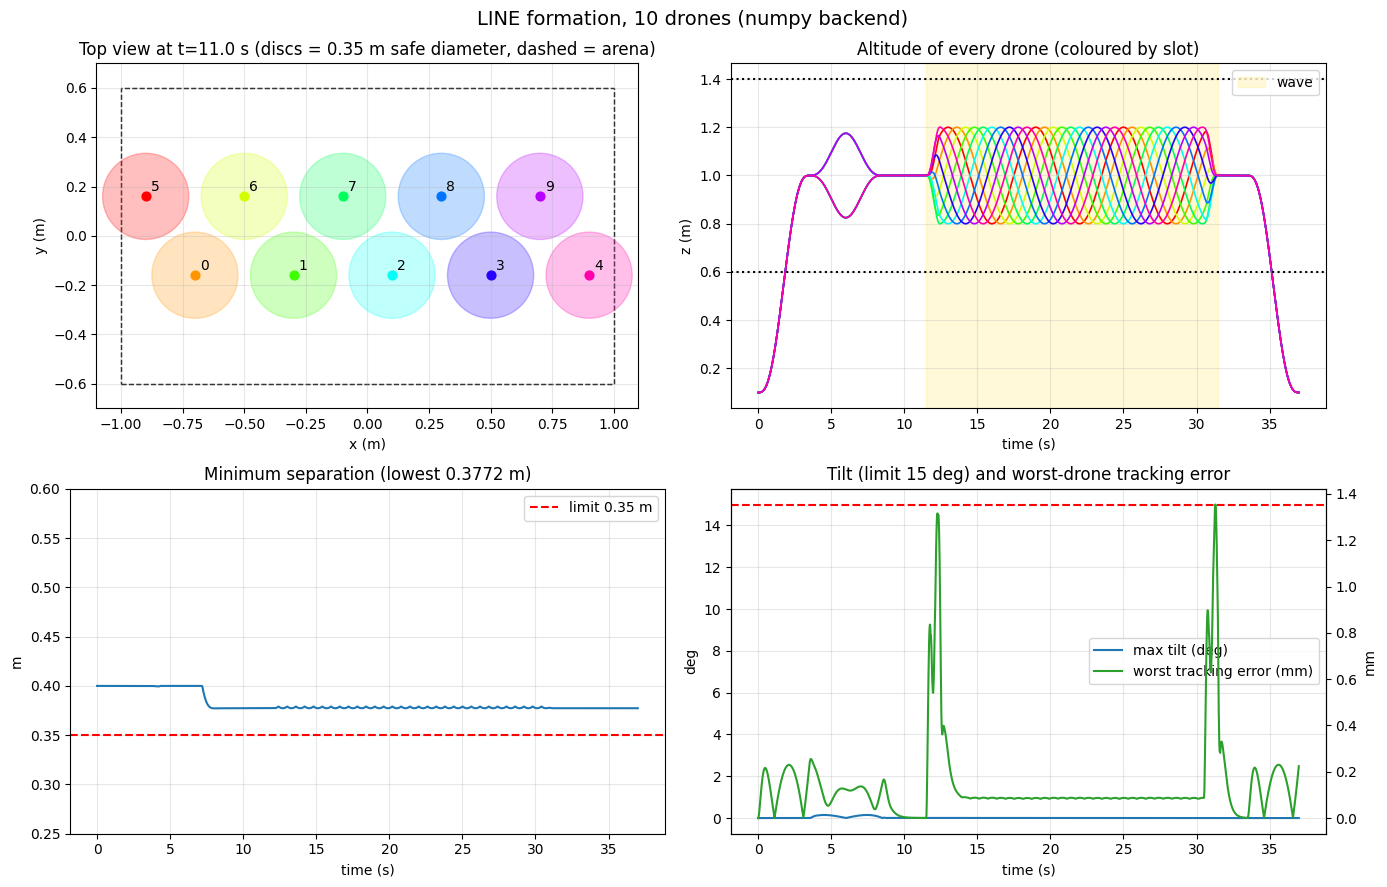

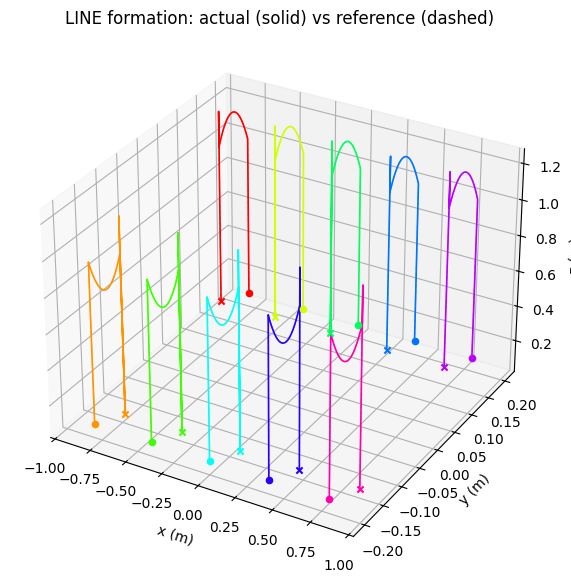

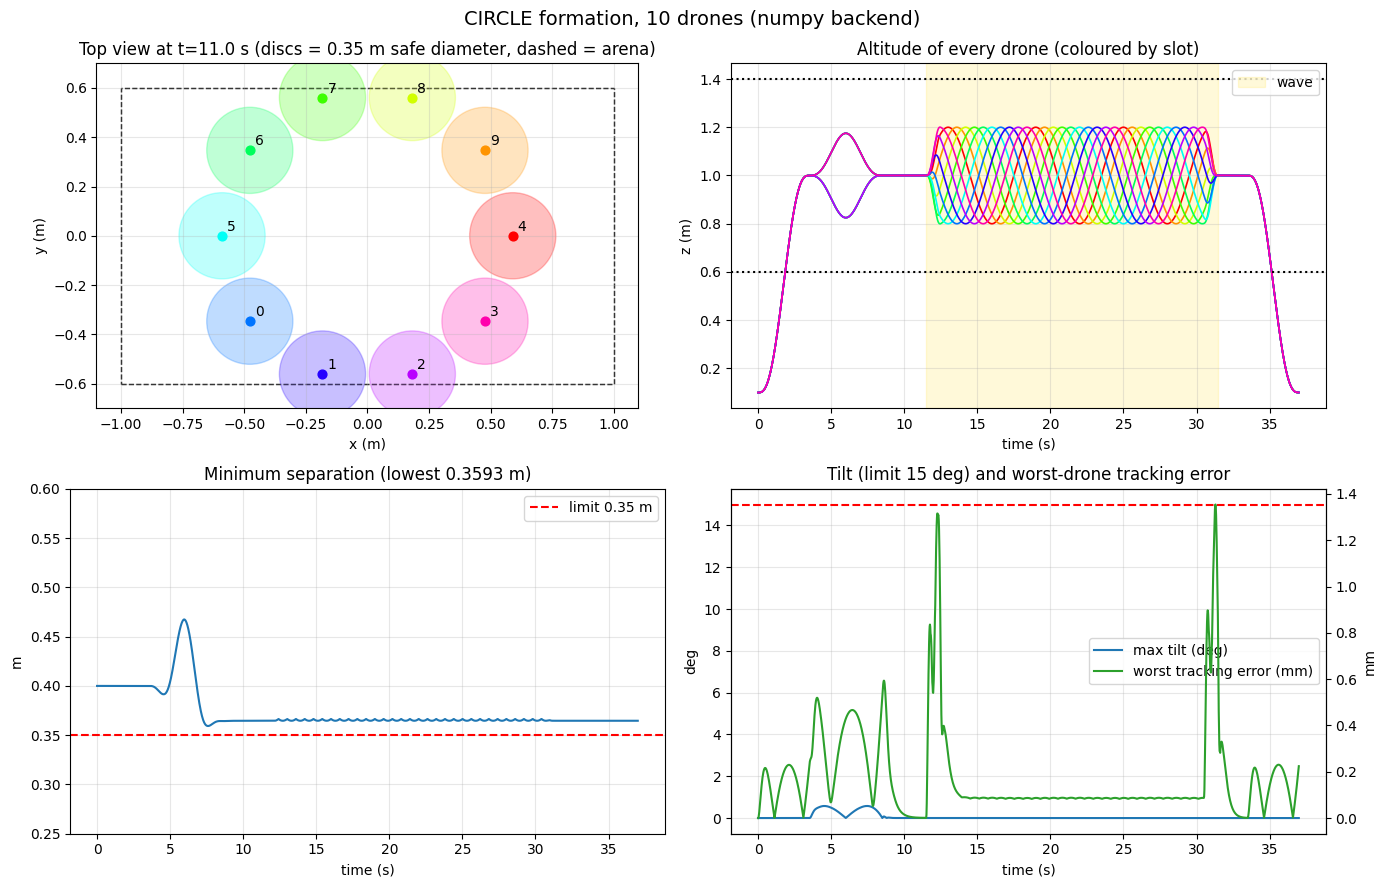

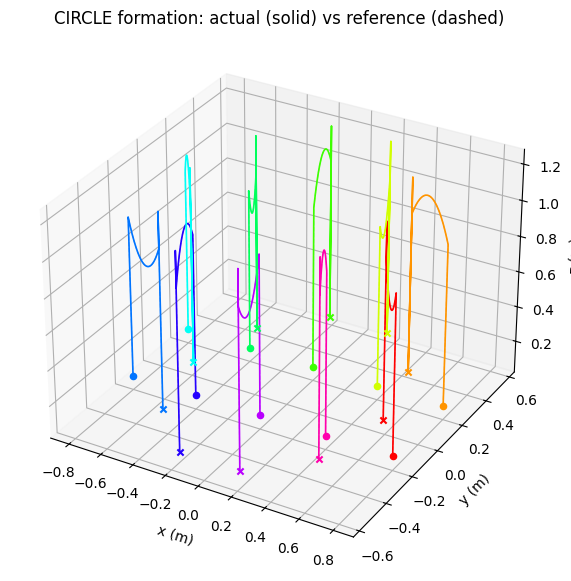

formation backend  drones  3D RMSE (mm)  wave RMSE (mm)  min separation (m)  max tilt (deg)  all checks
     line   numpy      10          0.18            0.22              0.3772            0.15        True
   circle   numpy      10          0.21            0.22              0.3593            0.58        True


In [ ]:
# =====================================================================
# 9. RESULTS
# =====================================================================
def slot_colors(plan):
    cmap = plt.get_cmap("hsv")
    return [cmap(plan["slot_of"][i] / plan["n"]) for i in range(plan["n"])]


def plot_overview(res, ev, save=True):
    plan, t, P, R_ = res["plan"], res["time"], res["p"], res["ref"]
    n, cols = plan["n"], slot_colors(plan)
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))

    # (a) top view in the hold phase: circles of diameter = min separation must not overlap
    a = ax[0, 0]; kh = int(np.searchsorted(t, T_WAVE_START - 0.5))
    a.add_patch(plt.Rectangle((X_MIN, Y_MIN), X_MAX - X_MIN, Y_MAX - Y_MIN, fill=False, ls="--", color="k"))
    for i in range(n):
        a.add_patch(plt.Circle(P[kh, i, :2], MIN_SEPARATION / 2, color=cols[i], alpha=0.25))
        a.scatter(*P[kh, i, :2], color=cols[i], s=40, zorder=3); a.annotate(str(i), P[kh, i, :2] + 0.02)
    a.set_aspect("equal"); a.set_xlim(X_MIN - .1, X_MAX + .1); a.set_ylim(Y_MIN - .1, Y_MAX + .1)
    a.set_title(f"Top view at t={t[kh]:.1f} s (discs = {MIN_SEPARATION} m safe diameter, dashed = arena)")
    a.set_xlabel("x (m)"); a.set_ylabel("y (m)"); a.grid(alpha=.3)

    # (b) altitude: the Mexican wave
    a = ax[0, 1]
    order = np.argsort(plan["slot_of"])
    for i in order:
        a.plot(t, P[:, i, 2], color=cols[i], lw=1.2)
    a.axhline(Z_MIN, ls=":", c="k"); a.axhline(Z_MAX, ls=":", c="k")
    a.axvspan(T_WAVE_START, T_WAVE_END, color="gold", alpha=.15, label="wave")
    a.set_title("Altitude of every drone (coloured by slot)"); a.set_xlabel("time (s)"); a.set_ylabel("z (m)"); a.legend(); a.grid(alpha=.3)

    # (c) minimum pairwise separation, checked at the physics rate
    a = ax[1, 0]
    a.plot(t, res["min_sep"], lw=1.5); a.axhline(MIN_SEPARATION, c="r", ls="--", label=f"limit {MIN_SEPARATION} m")
    a.set_ylim(0.25, max(0.6, res["min_sep"].max() + .02)); a.set_title(f"Minimum separation (lowest {ev['min_sep']:.4f} m)")
    a.set_xlabel("time (s)"); a.set_ylabel("m"); a.legend(); a.grid(alpha=.3)

    # (d) tilt and tracking error
    a = ax[1, 1]
    a.plot(t, np.rad2deg(res["tilt"].max(axis=1)), label="max tilt (deg)")
    a.axhline(15, c="r", ls="--"); a.set_xlabel("time (s)"); a.set_ylabel("deg"); a.grid(alpha=.3)
    b = a.twinx(); b.plot(t, 1000 * np.linalg.norm(P - R_, axis=2).max(axis=1), c="tab:green", label="worst tracking error (mm)")
    b.set_ylabel("mm"); a.set_title("Tilt (limit 15 deg) and worst-drone tracking error")
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = b.get_legend_handles_labels(); a.legend(h1 + h2, l1 + l2, loc="center right")

    fig.suptitle(f"{res['name'].upper()} formation, {n} drones ({res['backend']} backend)", fontsize=14)
    fig.tight_layout()
    if save: fig.savefig(f"/content/{res['name']}_overview.png" if Path("/content").exists() else f"{res['name']}_overview.png", dpi=140)
    plt.show()


def plot_3d(res, save=True):
    plan, P, R_ = res["plan"], res["p"], res["ref"]
    cols = slot_colors(plan)
    fig = plt.figure(figsize=(10, 7)); ax = fig.add_subplot(111, projection="3d")
    for i in range(plan["n"]):
        ax.plot(*P[:, i].T, color=cols[i], lw=1.2)
        ax.plot(*R_[:, i].T, color=cols[i], lw=.8, ls="--", alpha=.5)
        ax.scatter(*P[0, i], marker="o", color=cols[i]); ax.scatter(*P[-1, i], marker="x", color=cols[i])
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z (m)")
    ax.set_title(f"{res['name'].upper()} formation: actual (solid) vs reference (dashed)")
    if save: fig.savefig(f"/content/{res['name']}_3d.png" if Path("/content").exists() else f"{res['name']}_3d.png", dpi=140)
    plt.show()


def summary_table(results, evals):
    rows = []
    for r, e in zip(results, evals):
        rows.append({"formation": r["name"], "backend": r["backend"], "drones": r["plan"]["n"],
                     "3D RMSE (mm)": round(1000 * e["rmse"], 2), "wave RMSE (mm)": round(1000 * e["wave_rmse"], 2),
                     "min separation (m)": round(e["min_sep"], 4), "max tilt (deg)": round(e["max_tilt_deg"], 2),
                     "all checks": all(e["checks"].values())})
    return pd.DataFrame(rows)


plot_overview(line_res, line_eval);     plot_3d(line_res)
plot_overview(circle_res, circle_eval); plot_3d(circle_res)
display_df = summary_table([line_res, circle_res], [line_eval, circle_eval])
print(display_df.to_string(index=False))

In [ ]:
# =====================================================================
# 11. EXPORT  (CSV logs, figures, videos)
# =====================================================================
OUT = Path("/content") if Path("/content").exists() else Path(".")

def create_log(res):
    t, P, R_, V, tilt, plan = res["time"], res["p"], res["ref"], res["v"], res["tilt"], res["plan"]
    rows = []
    for i in range(plan["n"]):
        rows.append(pd.DataFrame({"time": t, "drone_id": i, "slot": plan["slot_of"][i], "phase": plan["phase"],
            "ref_x": R_[:, i, 0], "ref_y": R_[:, i, 1], "ref_z": R_[:, i, 2],
            "x": P[:, i, 0], "y": P[:, i, 1], "z": P[:, i, 2],
            "vx": V[:, i, 0], "vy": V[:, i, 1], "vz": V[:, i, 2], "tilt_deg": np.rad2deg(tilt[:, i])}))
    return pd.concat(rows, ignore_index=True)

for res in (line_res, circle_res):
    path = OUT / f"{res['name']}_{N_DRONES}drones_log.csv"
    create_log(res).to_csv(path, index=False); print("saved", path)

saved /content/line_10drones_log.csv
saved /content/circle_10drones_log.csv


In [ ]:
# =====================================================================
# 10. VIDEO  (matplotlib, so it does not depend on MuJoCo's OpenGL renderer)
# =====================================================================
import imageio.v2 as imageio

def make_video(res, out_path, fps=25, trail=40):
    plan, t, P = res["plan"], res["time"], res["p"]
    n, cols = plan["n"], slot_colors(plan)
    step = max(1, int(round(CONTROL_HZ / fps)))
    frames_idx = range(0, len(t), step)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), dpi=90)
    a1.add_patch(plt.Rectangle((X_MIN, Y_MIN), X_MAX - X_MIN, Y_MAX - Y_MIN, fill=False, ls="--", color="k"))
    a1.set_xlim(X_MIN - .15, X_MAX + .15); a1.set_ylim(Y_MIN - .15, Y_MAX + .15); a1.set_aspect("equal")
    a1.set_title("Top view (x-y)"); a1.set_xlabel("x (m)"); a1.set_ylabel("y (m)"); a1.grid(alpha=.3)
    a2.set_xlim(X_MIN - .15, X_MAX + .15); a2.set_ylim(0, Z_MAX + .2)
    a2.axhspan(Z_MIN, Z_MAX, color="g", alpha=.08); a2.set_title("Front view (x-z)")
    a2.set_xlabel("x (m)"); a2.set_ylabel("z (m)"); a2.grid(alpha=.3)
    discs = [plt.Circle((0, 0), MIN_SEPARATION / 2, color=cols[i], alpha=.22) for i in range(n)]
    for d in discs: a1.add_patch(d)
    s1 = a1.scatter(np.zeros(n), np.zeros(n), c=cols, s=40, zorder=3)
    s2 = a2.scatter(np.zeros(n), np.zeros(n), c=cols, s=40, zorder=3)
    txt = fig.text(0.5, 0.96, "", ha="center", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.94))

    writer = imageio.get_writer(str(out_path), fps=fps, codec="libx264", macro_block_size=16)
    for k in frames_idx:
        p = P[k]
        s1.set_offsets(p[:, :2]); s2.set_offsets(p[:, [0, 2]])
        for i, d in enumerate(discs): d.center = p[i, :2]
        txt.set_text(f"{res['name'].upper()} formation, {n} drones | t = {t[k]:5.1f} s | phase: {plan['phase'][k]} "
                     f"| min separation {res['min_sep'][k]:.3f} m")
        fig.canvas.draw()

        # Convert frame to numpy array and crop to make dimensions even (divisible by 16)
        frame = np.asarray(fig.canvas.buffer_rgba())[..., :3]
        h, w, c = frame.shape
        h_even = (h // 16) * 16
        w_even = (w // 16) * 16
        frame_cropped = frame[:h_even, :w_even].copy()

        writer.append_data(frame_cropped)
    writer.close(); plt.close(fig)
    print("saved", out_path)
    return out_path


line_video   = make_video(line_res,   OUT / f"line_{N_DRONES}drones.mp4")
circle_video = make_video(circle_res, OUT / f"circle_{N_DRONES}drones.mp4")

try:
    from IPython.display import Video, display
    display(Video(str(line_video), embed=True, width=800))
    display(Video(str(circle_video), embed=True, width=800))
except Exception as e:
    print("Inline playback skipped:", e)

saved /content/line_10drones.mp4
saved /content/circle_10drones.mp4


In [11]:
# =====================================================================
# 12. DOWNLOAD (Colab only)
# =====================================================================
try:
    from google.colab import files
    for p in sorted(OUT.glob(f"*_{N_DRONES}drones*")) + sorted(OUT.glob("*_overview.png")) + sorted(OUT.glob("*_3d.png")):
        files.download(str(p))
except ImportError:
    print("Not running in Colab. Files are in:", OUT.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>